In [35]:
import pandas as pd
import os
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , PolynomialFeatures
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [6]:
DATA_PATH = 'final_feature_matrix.csv'

In [13]:
def prepare_data(df, val_size=10, random_seed=42):
    """
    Prepares the dataset for training by:
    - Dropping non-predictive metadata (IDs)
    - Encoding categorical variables (Gender)
    - Imputing missing values with column means
    - Splitting features (X) from the target label (y)
    - Creating a stratified train/validation split
    """
    print("Preparing data...")
    
    # Isolate target variable and drop it from features alongside the Subject ID
    y = df['Label']
    X = df.drop(columns=['Subject Number', 'Label'], errors='ignore')
        
    # One-Hot Encode categorical variables (e.g., 'Gender_M', 'Gender_F' -> 0/1)
    if 'Gender' in X.columns:
        X = pd.get_dummies(X, columns=['Gender'], drop_first=True).astype(float)
        
    # Impute any missing numerical values (NaNs) with the mean of their respective columns
    X = X.fillna(X.mean())
    
    # --- NEW: Stratified split for the validation set ---
    # Setting test_size=10 and stratify=y guarantees 5 from Class 1 and 5 from Class 0
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, 
        test_size=val_size, 
        stratify=y, 
        random_state=random_seed
    )
    
    print(f"Split complete:")
    print(f"  Training set: {len(X_train)} subjects ({sum(y_train==1)} Class 1, {sum(y_train==0)} Class 0)")
    print(f"  Validation set: {len(X_val)} subjects ({sum(y_val==1)} Class 1, {sum(y_val==0)} Class 0)")
    
    return X_train, X_val, y_train, y_val

In [28]:
def evaluate_logistic_regression_with_kfold(K_FOLDS=5):
    """Evaluates Logistic Regression using Stratified K-Fold on training data, displays metrics, and validates on the holdout set."""
    if not os.path.exists(DATA_PATH):
        print(f"Error: '{DATA_PATH}' not found.")
        return

    df = pd.read_csv(DATA_PATH)
    
    # Unpack all four variables from the updated prepare_data function
    X_train, X_val, y_train, y_val = prepare_data(df)

    # 1. Pipeline for Logistic Regression
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('log_reg', LogisticRegression(solver='liblinear', random_state=42))
    ])

    cv_strategy = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)

    print(f"\nRunning {K_FOLDS}-Fold Stratified Cross Validation on Training Set ({len(X_train)} subjects)...")
    
    # 2. Get Accuracy Scores using ONLY the training data
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv_strategy, scoring='accuracy')

    # 3. Get 'Out-of-fold' Predictions
    y_pred = cross_val_predict(pipeline, X_train, y_train, cv=cv_strategy)

    # 4. Print Summary Results
    print("\n" + "="*45)
    print("LOGISTIC REGRESSION CROSS VALIDATION RESULTS")
    print("="*45)
    print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
    
    # 5. Display Confusion Matrix (Training/CV)
    cm = confusion_matrix(y_train, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
                xticklabels=['Class 0 Predicted', 'Class 1 Predicted'], 
                yticklabels=['Class 0 Actual', 'Class 1 Actual'])
    plt.title('CV Confusion Matrix (Training Data)')
    plt.tight_layout()
    plt.show() 
    
    # 5.5 Display Additional Metrics Figure
    tn, fp, fn, tp = cm.ravel()
    
    acc = accuracy_score(y_train, y_pred)
    prec = precision_score(y_train, y_pred, zero_division=0)
    rec = recall_score(y_train, y_pred, zero_division=0)
    f1 = f1_score(y_train, y_pred, zero_division=0)
    
    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0 
    tnr = tn / (tn + fp) if (tn + fp) > 0 else 0 
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0

    metrics_data = {
        'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'TPR', 'TNR', 'FPR', 'FNR'],
        'Score': [acc, prec, rec, f1, tpr, tnr, fpr, fnr]
    }
    metrics_df = pd.DataFrame(metrics_data)
    
    plt.figure(figsize=(9, 5))
    # FIX 1: Added hue='Metric' and legend=False
    ax = sns.barplot(x='Metric', y='Score', data=metrics_df, hue='Metric', palette='viridis', legend=False)
    plt.title('CV Classification Evaluation Metrics')
    plt.ylim(0, 1.1) 
    plt.ylabel('Score')
    
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", 
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='baseline', fontsize=10, color='black', 
                    xytext=(0, 5), textcoords='offset points')
                    
    plt.tight_layout()
    plt.show()

    # 6. Extract Feature Importance
    pipeline.fit(X_train, y_train)
    coefs = pd.DataFrame({
        'Feature': X_train.columns,
        'Coefficient': pipeline.named_steps['log_reg'].coef_[0]
    }).sort_values(by='Coefficient', ascending=False)
    
    # 7. Display Feature Importance
    plt.figure(figsize=(10, 8)) 
    # FIX 2: Added hue='Feature' and legend=False
    sns.barplot(x='Coefficient', y='Feature', data=coefs, hue='Feature', palette='coolwarm', legend=False)
    plt.title('Logistic Regression Feature Coefficients (Trained on CV Data)')
    plt.xlabel('Coefficient Value (Importance)')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()

    # 8. Validate on the Holdout Set
    print("\n" + "="*45)
    print("VALIDATION SET RESULTS (10 Held-out Subjects)")
    print("="*45)
    
    y_val_pred = pipeline.predict(X_val)
    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = f1_score(y_val, y_val_pred, zero_division=0)
    
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation F1 Score: {val_f1:.4f}")
    
    cm_val = confusion_matrix(y_val, y_val_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Class 0 Pred', 'Class 1 Pred'], 
                yticklabels=['Class 0 Act', 'Class 1 Act'])
    plt.title('Validation Confusion Matrix')
    plt.tight_layout()
    plt.show()

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

Running 3-Fold Stratified Cross Validation on Training Set (60 subjects)...

LOGISTIC REGRESSION CROSS VALIDATION RESULTS
Mean CV Accuracy: 0.6667 (+/- 0.0850)


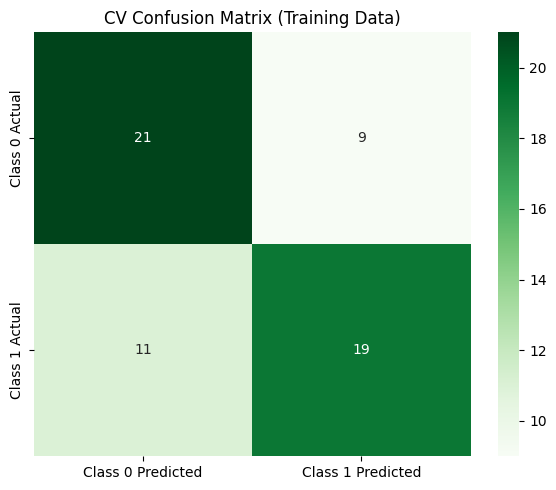

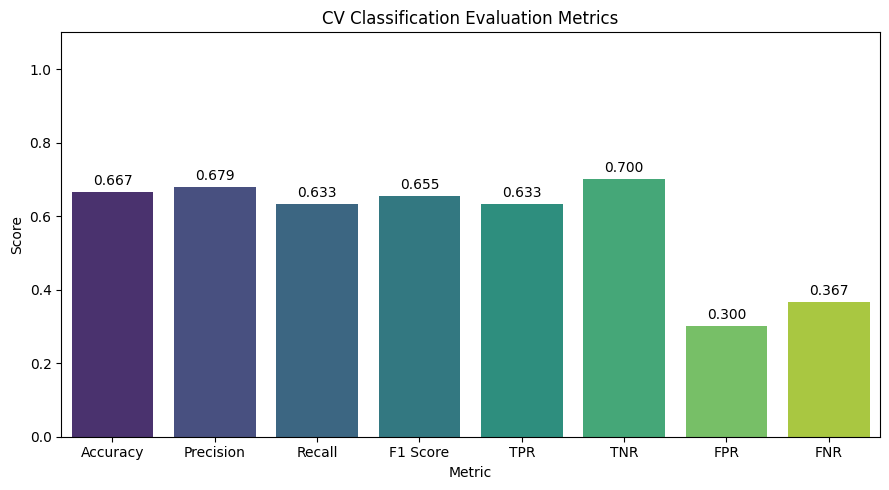

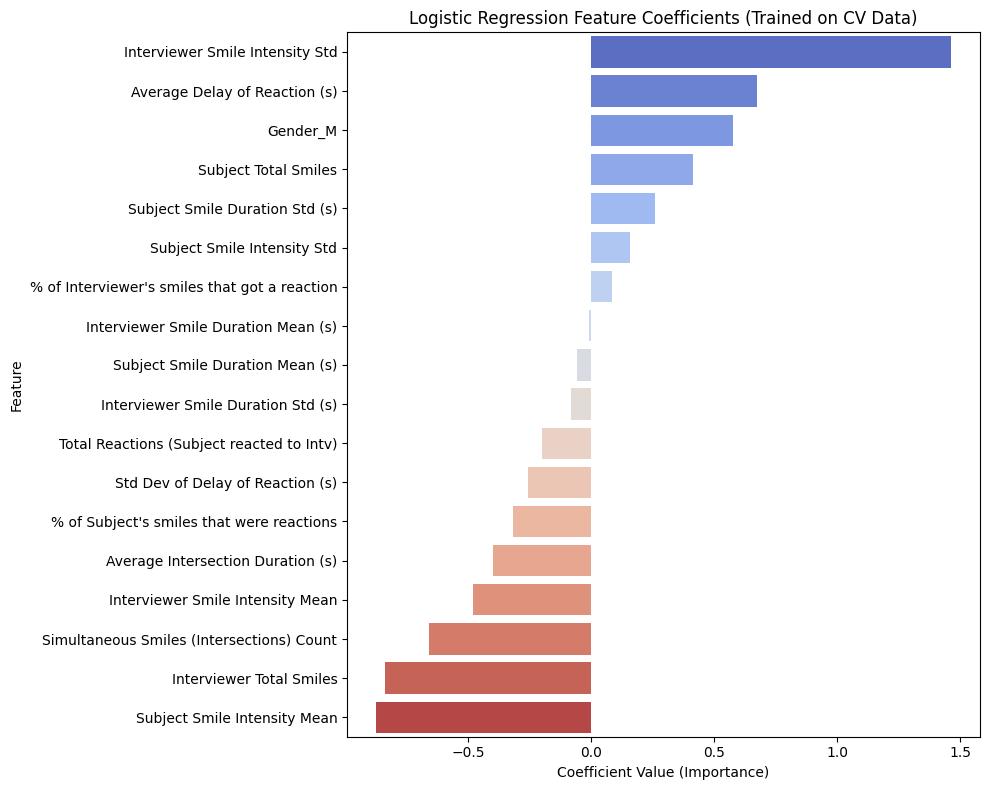


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4444


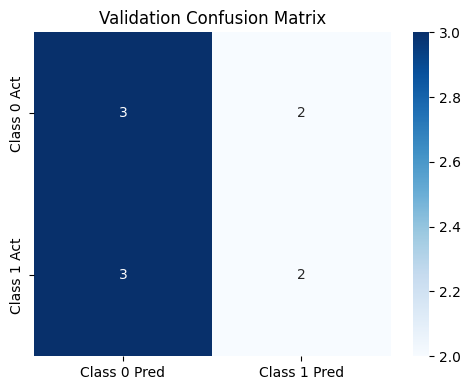

In [29]:
evaluate_logistic_regression_with_kfold(3)

In [32]:
def evaluate_logreg_with_kfold(K_FOLDS=5, use_l1=True, C_value=1.0, max_iter=1000):
    """
    Evaluates Logistic Regression and displays a 2x2 figure on training data,
    followed by validation on the holdout set.
    """
    if not os.path.exists(DATA_PATH):
        print(f"Error: '{DATA_PATH}' not found.")
        return

    df = pd.read_csv(DATA_PATH)
    
    # Unpack all four variables from the updated prepare_data function
    X_train, X_val, y_train, y_val = prepare_data(df)

    # --- FIX: Update for scikit-learn 1.8+ ---
    # Use l1_ratio instead of penalty. 1.0 = L1 (Sparse), 0.0 = L2 (Standard)
    ratio = 1.0 if use_l1 else 0.0
    
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('log_reg', LogisticRegression(
            l1_ratio=ratio,         # Replaced 'penalty' with 'l1_ratio'
            C=C_value, 
            solver='saga',          # Switched to 'saga' which natively supports l1_ratio
            max_iter=max_iter, 
            random_state=42
        ))
    ])
    # -----------------------------------------

    cv_strategy = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    # Apply CV only to the training set
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv_strategy, scoring='accuracy')
    y_pred = cross_val_predict(pipeline, X_train, y_train, cv=cv_strategy)

    # Metrics DataFrame for plotting
    metrics_df = pd.DataFrame({
        "Metric": ["Accuracy", "Precision", "Recall", "F1", "CV Mean Acc"],
        "Score": [
            accuracy_score(y_train, y_pred),
            precision_score(y_train, y_pred, average='weighted', zero_division=0),
            recall_score(y_train, y_pred, average='weighted', zero_division=0),
            f1_score(y_train, y_pred, average='weighted', zero_division=0),
            cv_scores.mean()
        ]
    })

    # Coefficients
    pipeline.fit(X_train, y_train)
    coefs = pd.DataFrame({
        'Feature': X_train.columns,
        'Coefficient': pipeline.named_steps['log_reg'].coef_[0]
    }).sort_values(by='Coefficient', ascending=False)

    # --- 2x2 Subplot Visualization for Notebook Display ---
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    penalty_display = "L1 (Sparse)" if use_l1 else "L2 (Standard)"
    fig.suptitle(f'CV Evaluation | Penalty: {penalty_display} | C = {C_value}', fontsize=18, fontweight='bold')
    
    # 1. Confusion Matrix (Top-Left)
    sns.heatmap(confusion_matrix(y_train, y_pred), annot=True, fmt='d', cmap='Greens', ax=axes[0, 0],
                xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
    axes[0, 0].set_title('CV Confusion Matrix (Training Data)', fontsize=14)

    # 2. Feature Importance (Top-Right)
    sns.barplot(x='Coefficient', y='Feature', data=coefs, ax=axes[0, 1], hue='Feature', palette='viridis', legend=False)
    axes[0, 1].set_title('Feature Importance', fontsize=14)
    axes[0, 1].axvline(x=0, color='black', linestyle='--', linewidth=0.8)

    # 3. Coefficient Distribution (Bottom-Left)
    sns.histplot(coefs['Coefficient'], kde=True, color='purple', ax=axes[1, 0])
    axes[1, 0].set_title('Coefficient Distribution', fontsize=14)
    axes[1, 0].set_xlabel('Coefficient Value')

    # 4. Metrics Histogram (Bottom-Right)
    sns.barplot(x='Score', y='Metric', data=metrics_df, ax=axes[1, 1], hue='Metric', palette='magma', legend=False)
    axes[1, 1].set_title('CV Performance Metrics', fontsize=14)
    axes[1, 1].set_xlim(0, 1.1) 
    
    # Add values on bars
    for i in axes[1, 1].containers:
        axes[1, 1].bar_label(i, fmt='%.3f', padding=5)

    plt.tight_layout()
    fig.subplots_adjust(top=0.92) 
    plt.show() 

    # --- 5. Validate on the Holdout Set ---
    print("\n" + "="*45)
    print("VALIDATION SET RESULTS (10 Held-out Subjects)")
    print("="*45)
    
    # Predict on the unseen validation data
    y_val_pred = pipeline.predict(X_val)
    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = f1_score(y_val, y_val_pred, average='weighted', zero_division=0)
    
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation F1 Score: {val_f1:.4f}")
    
    # Display Validation Confusion Matrix
    cm_val = confusion_matrix(y_val, y_val_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['TD Pred', 'ASD Pred'], 
                yticklabels=['TD Act', 'ASD Act'])
    plt.title('Validation Confusion Matrix')
    plt.tight_layout()
    plt.show()

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


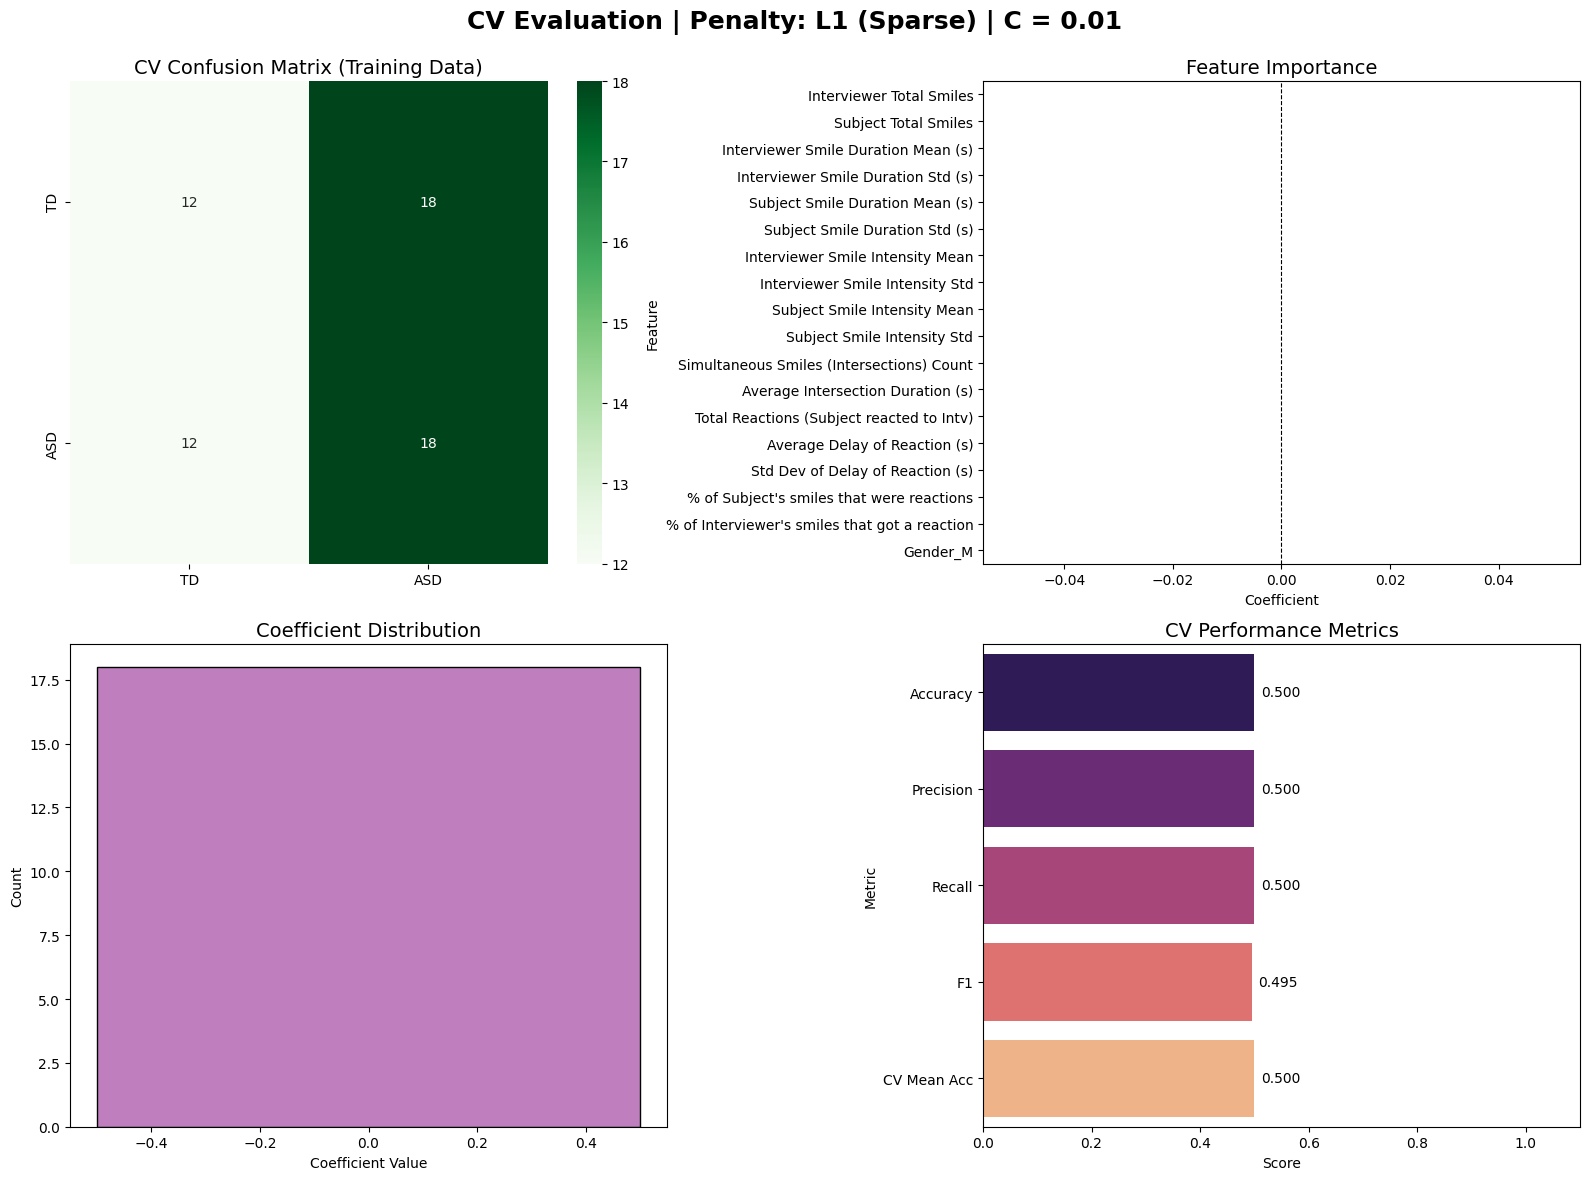


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.3333


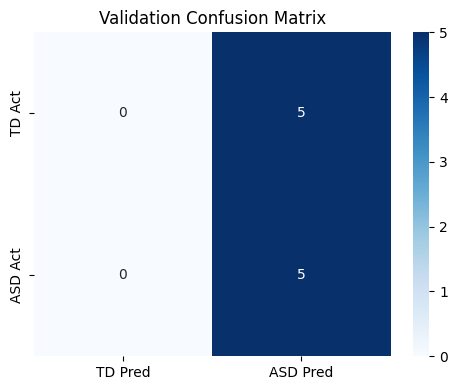


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


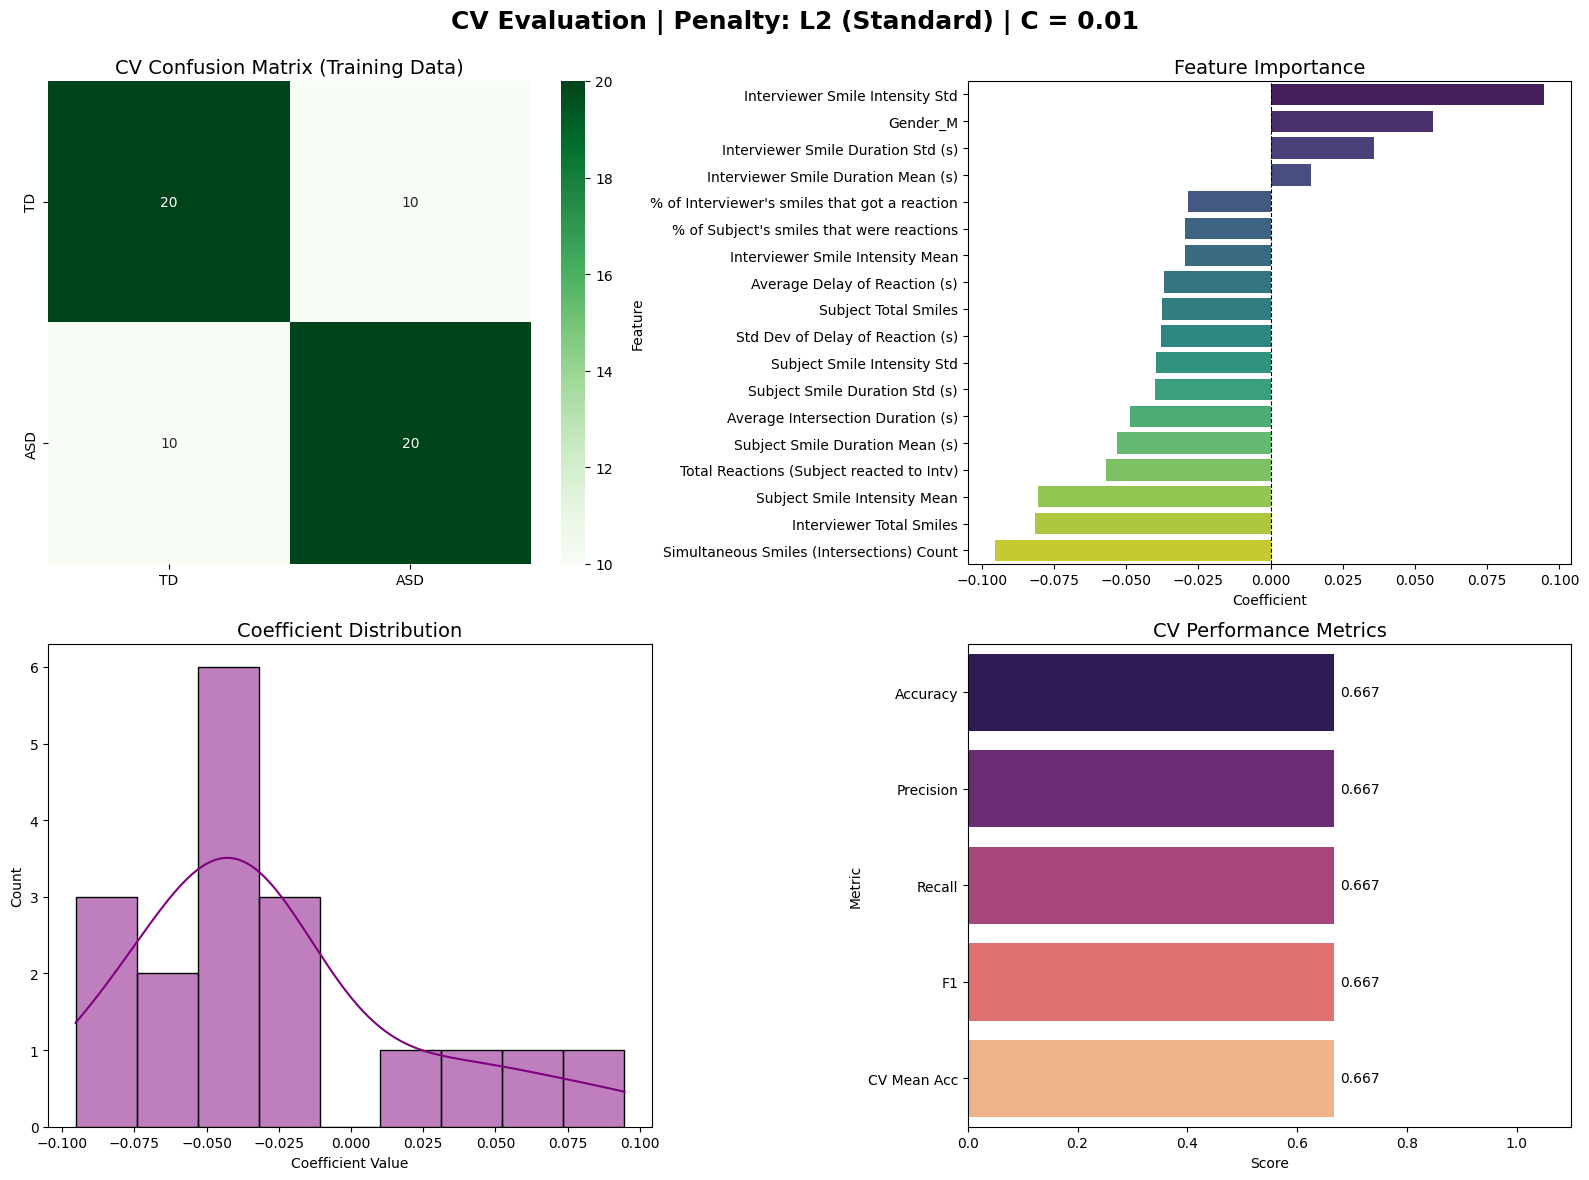


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.6000
Validation F1 Score: 0.5833


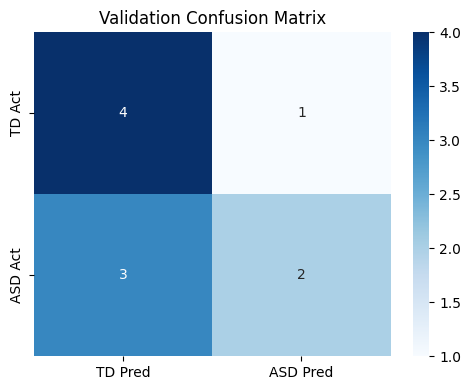

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


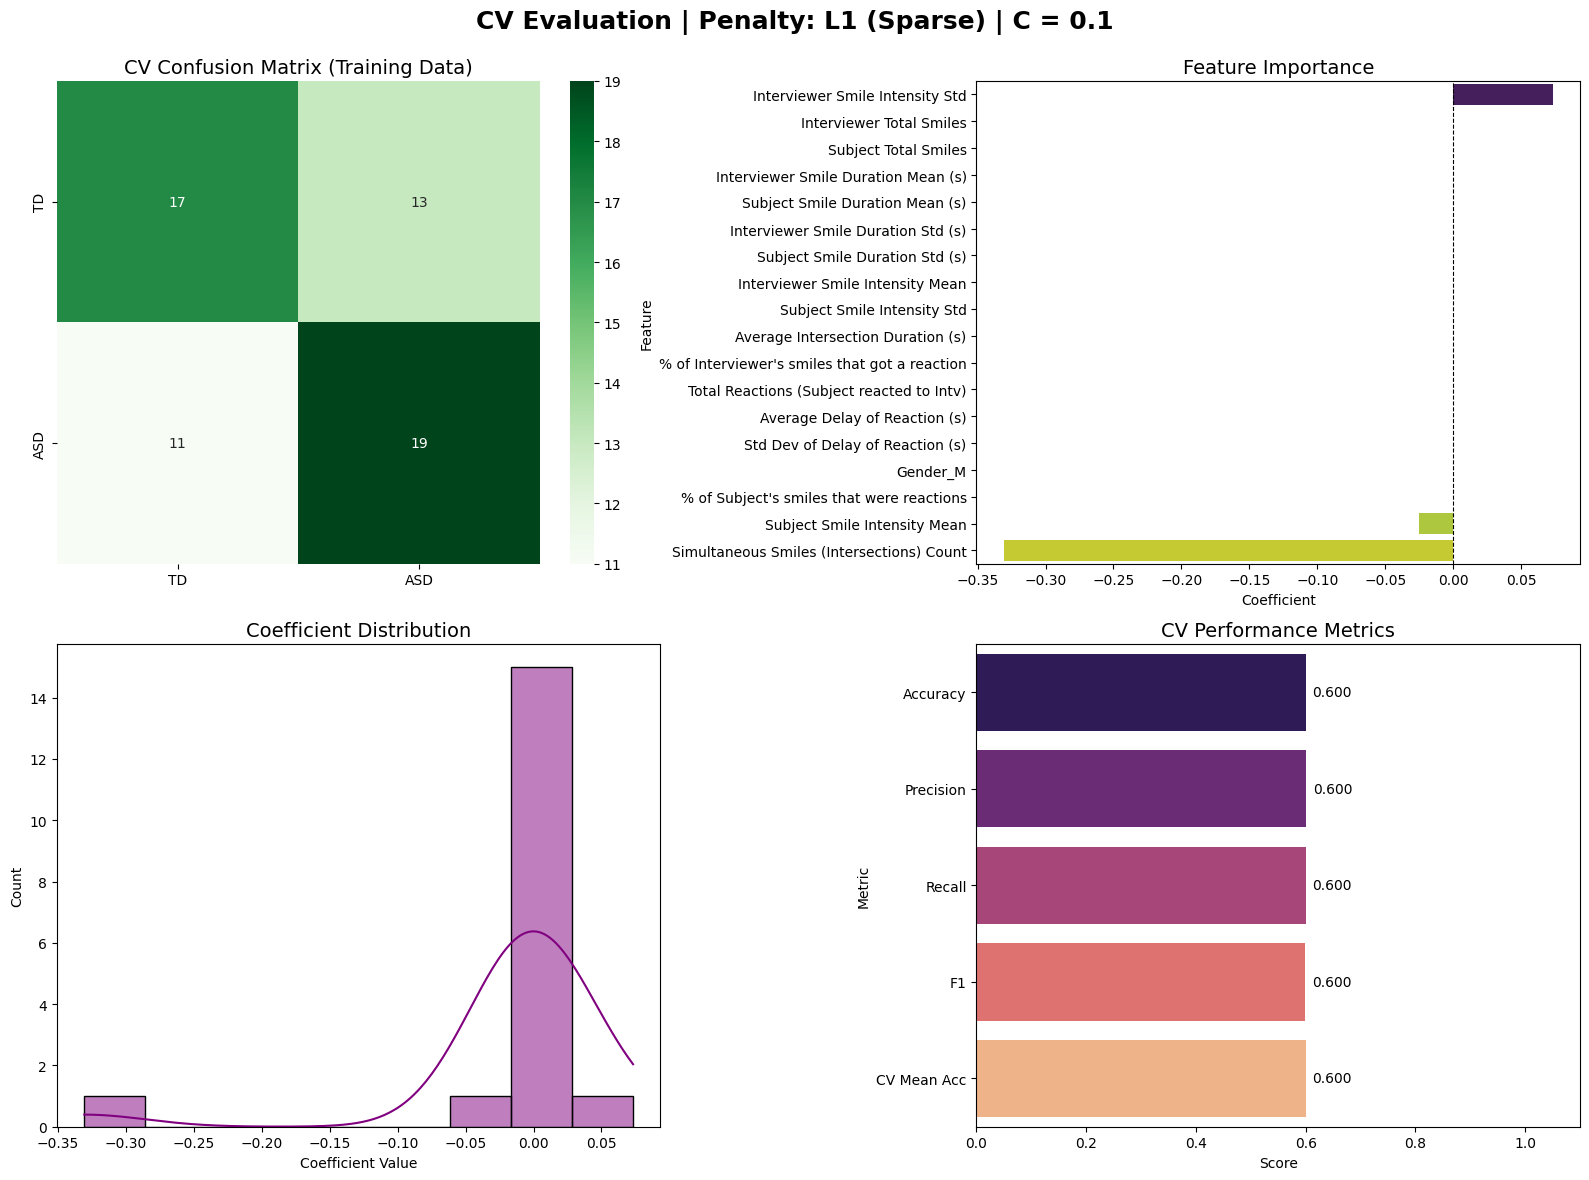


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970


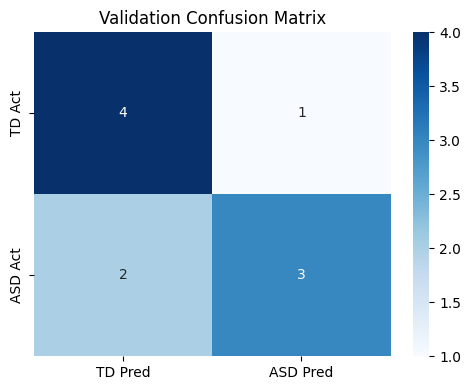


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


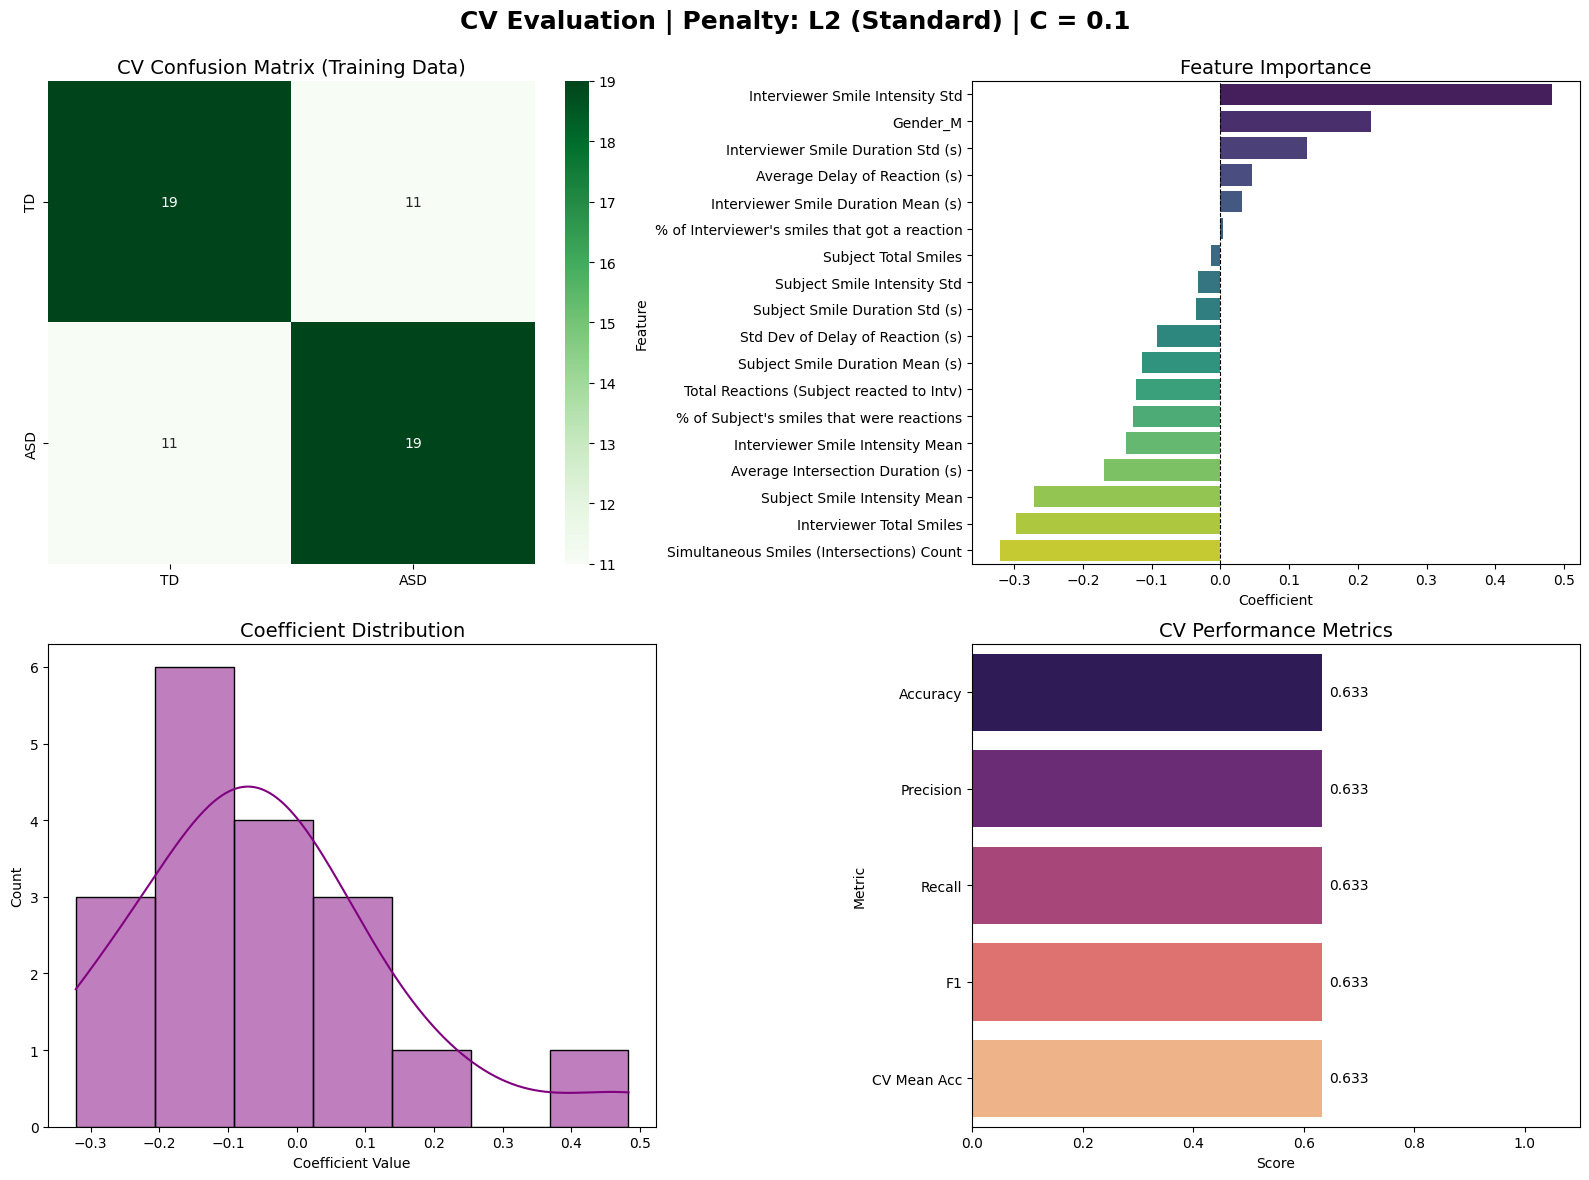


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4949


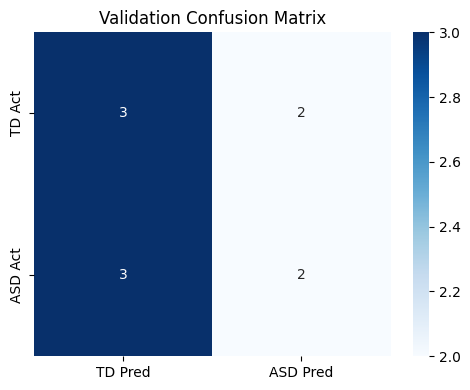

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


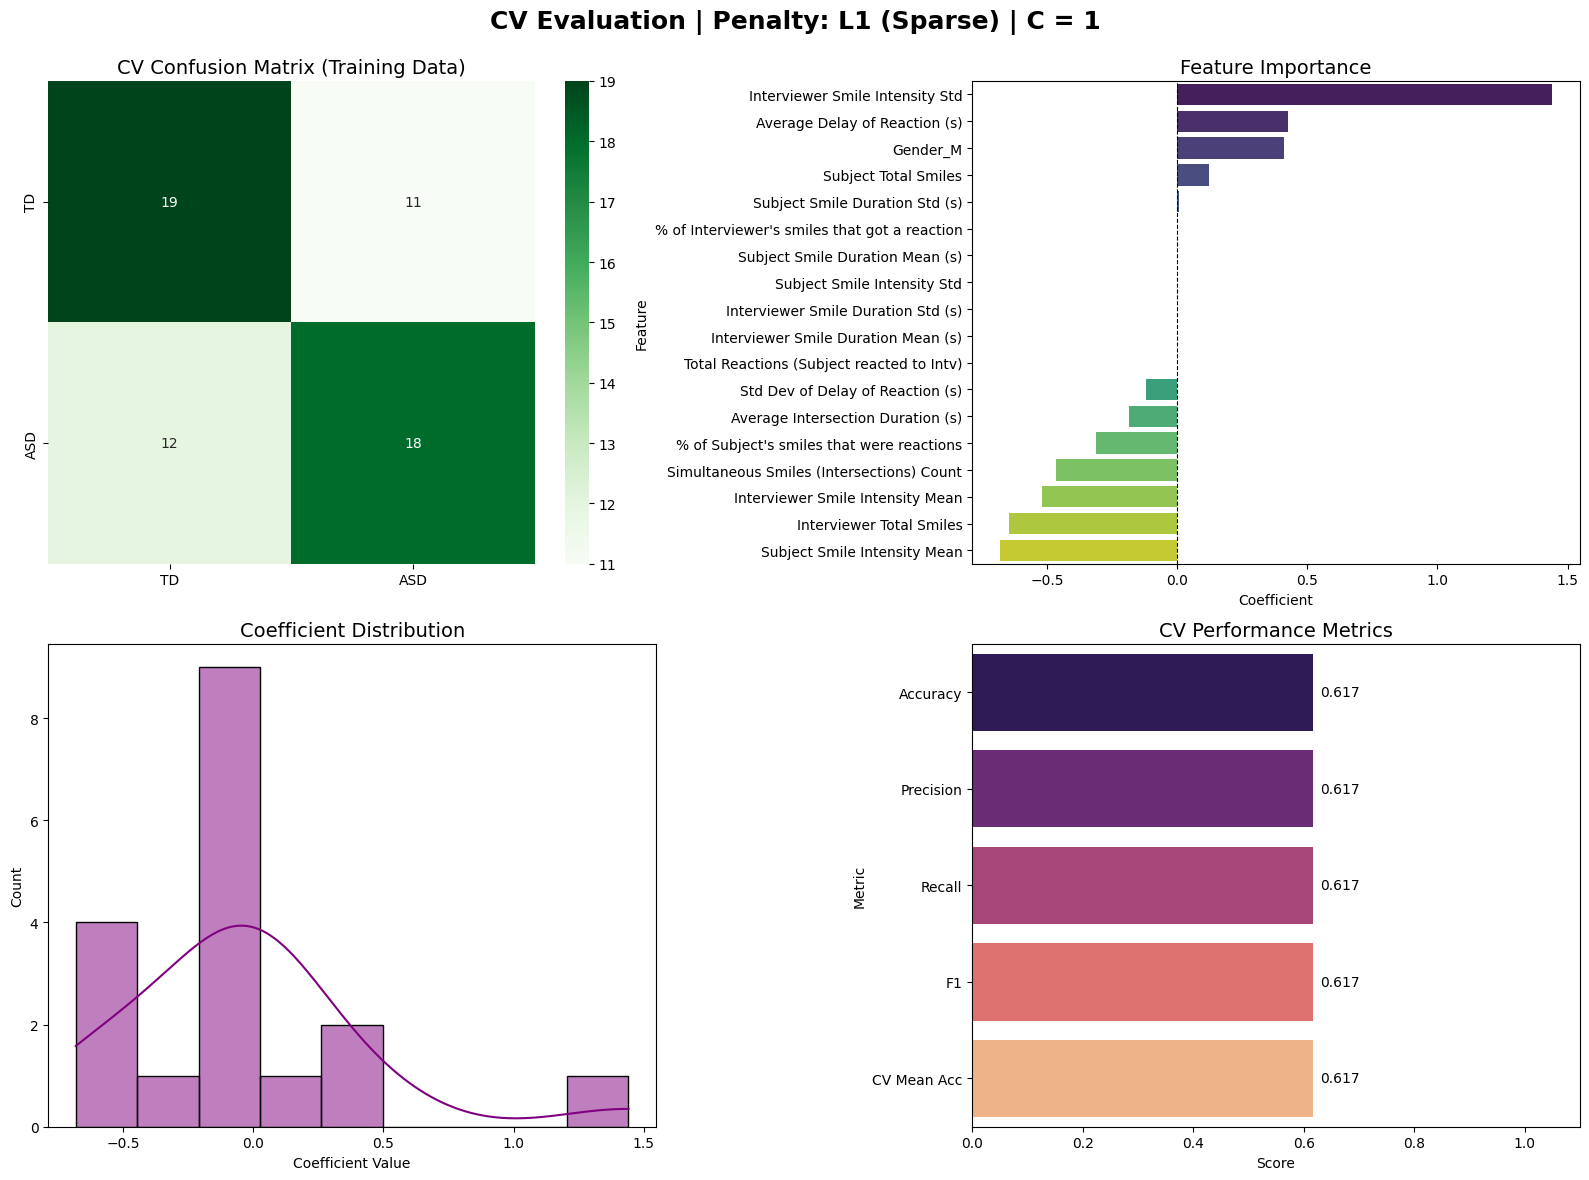


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4949


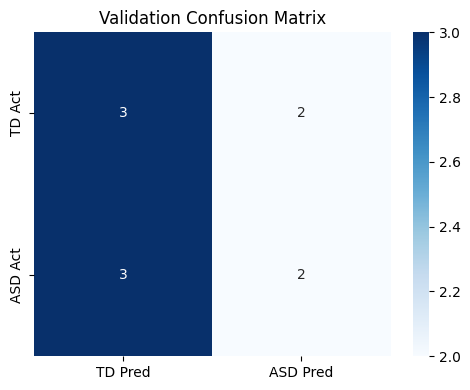


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


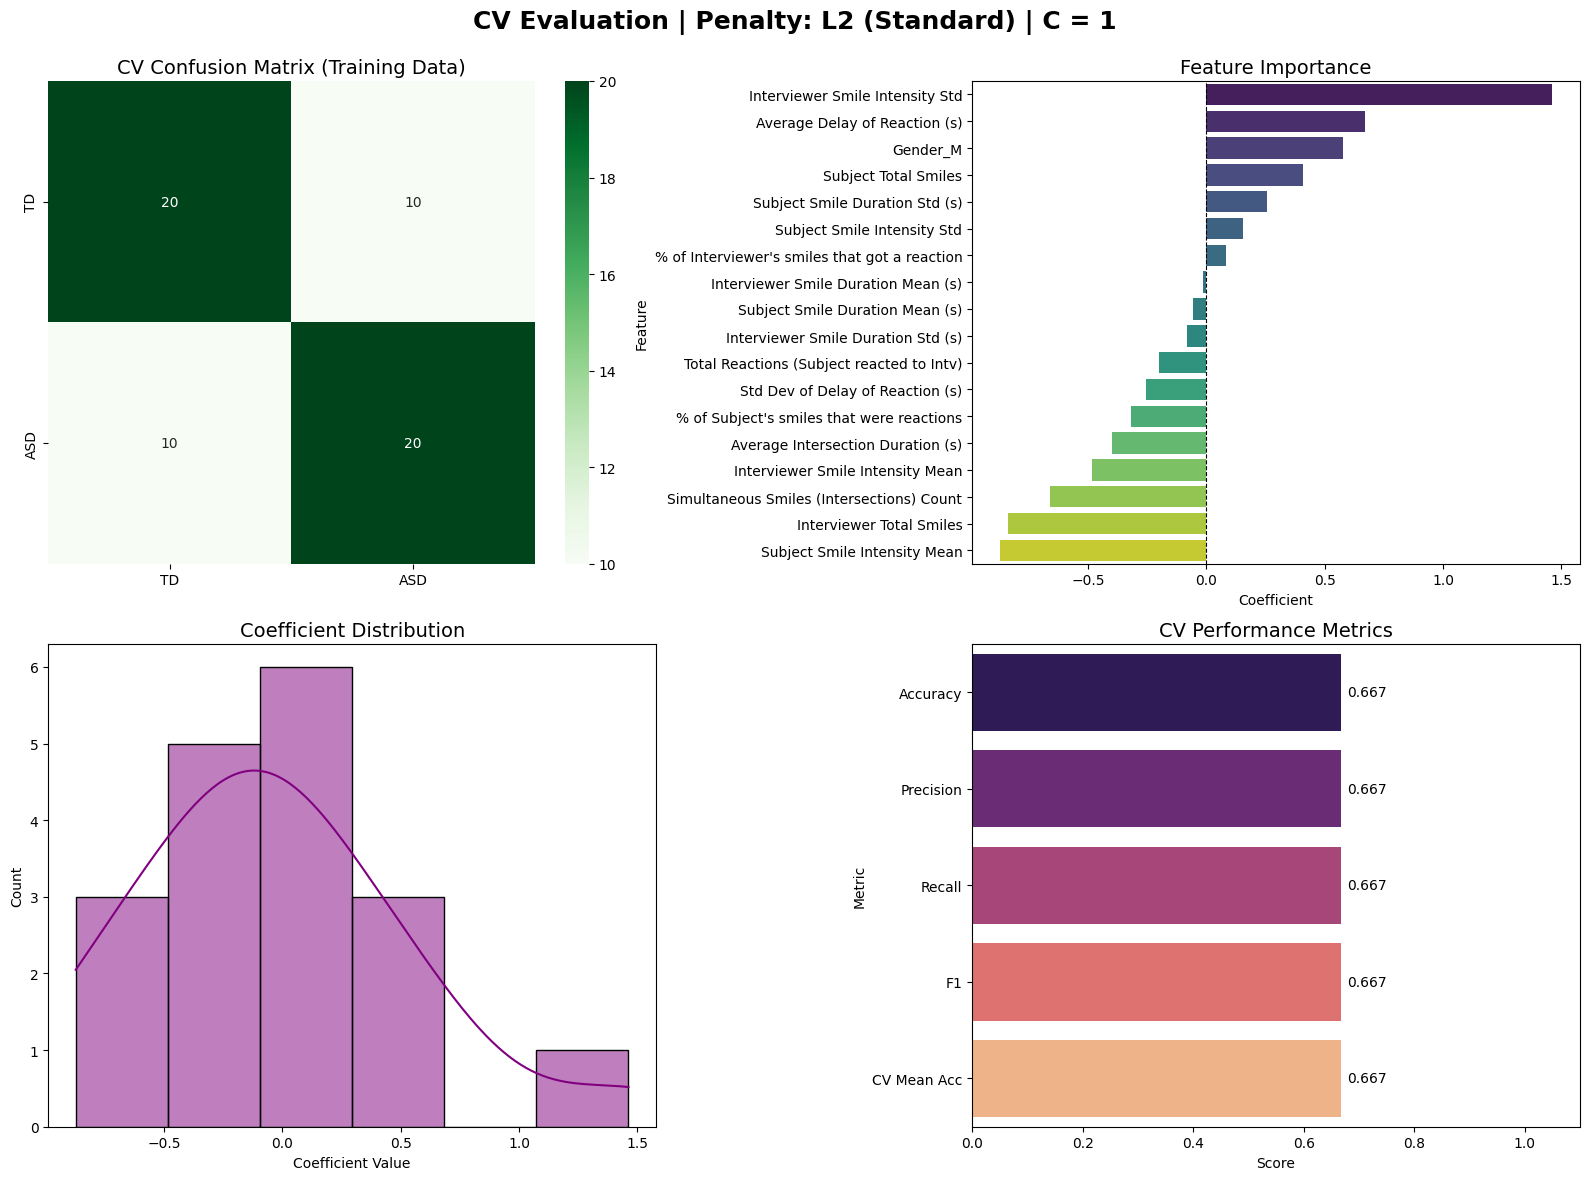


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4949


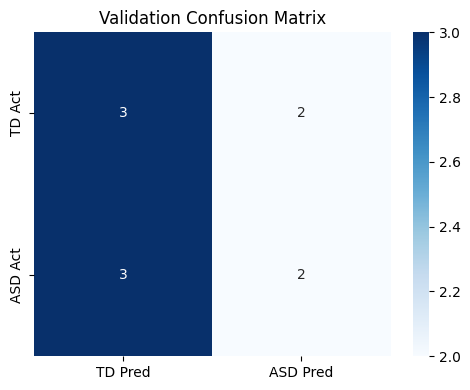

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-pack

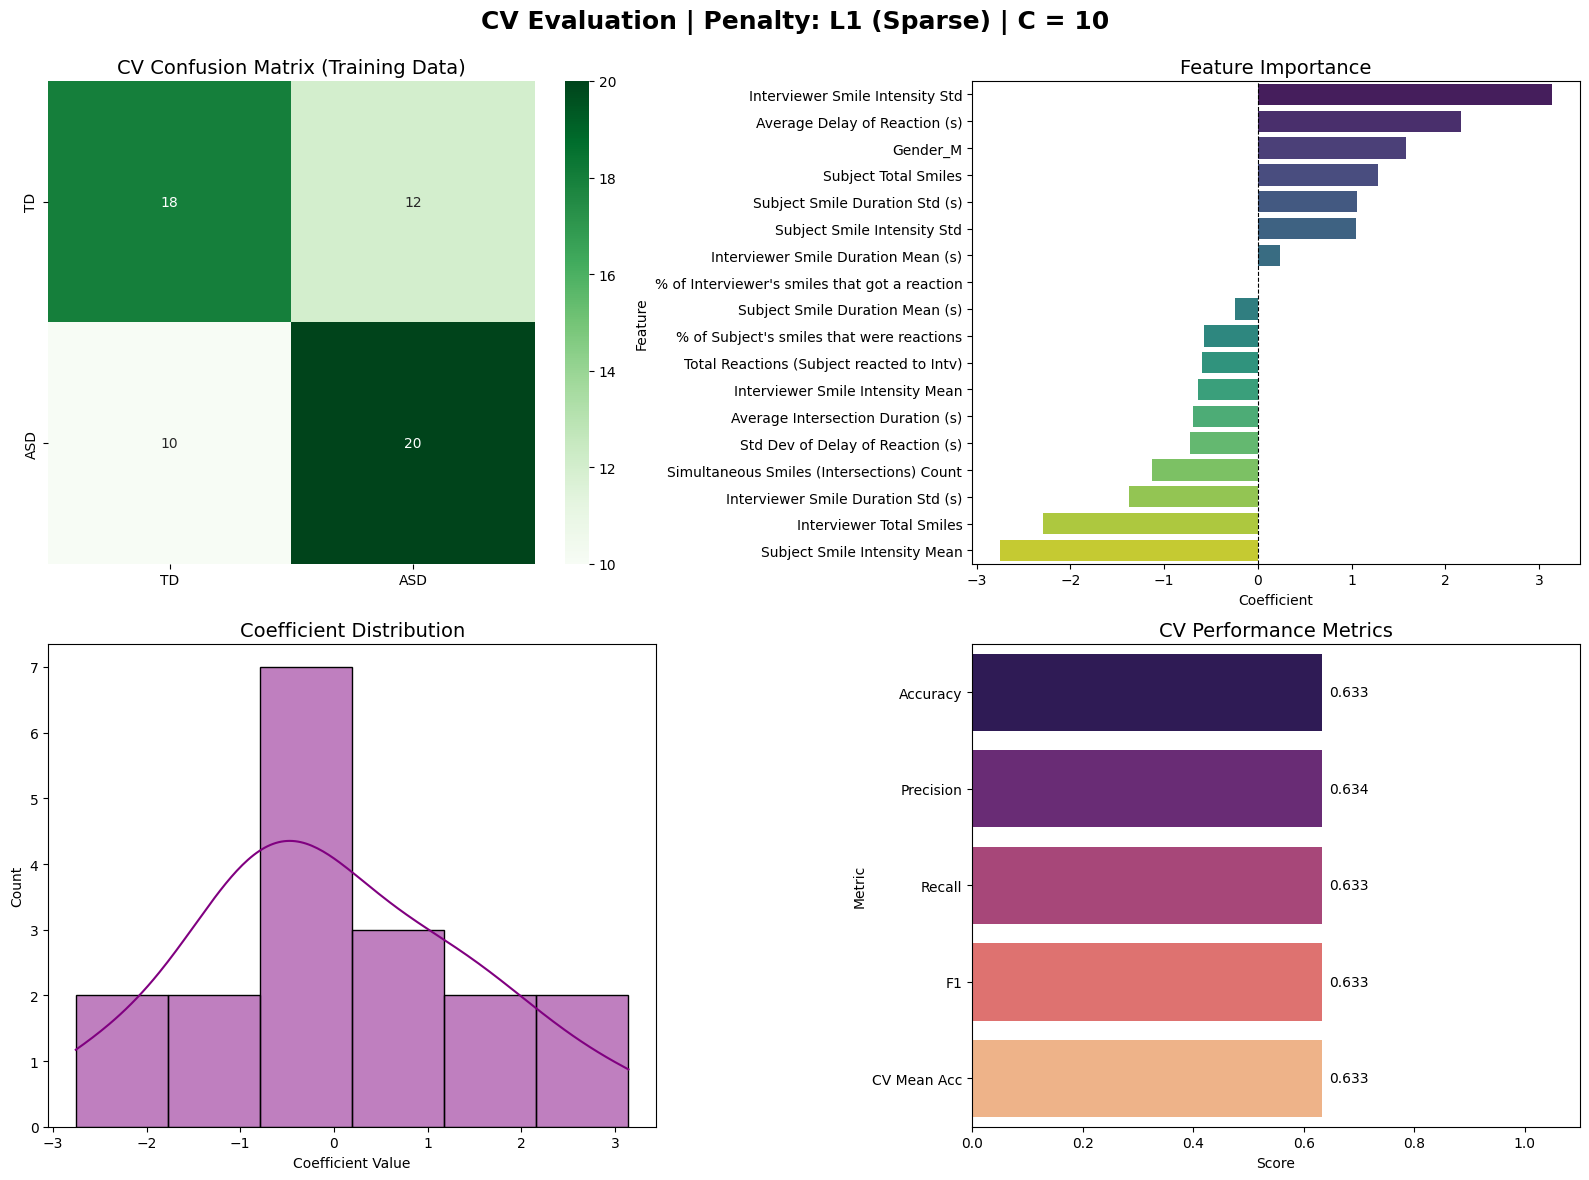


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.4000
Validation F1 Score: 0.4000


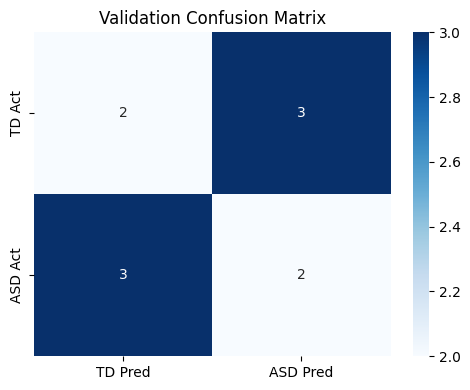


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


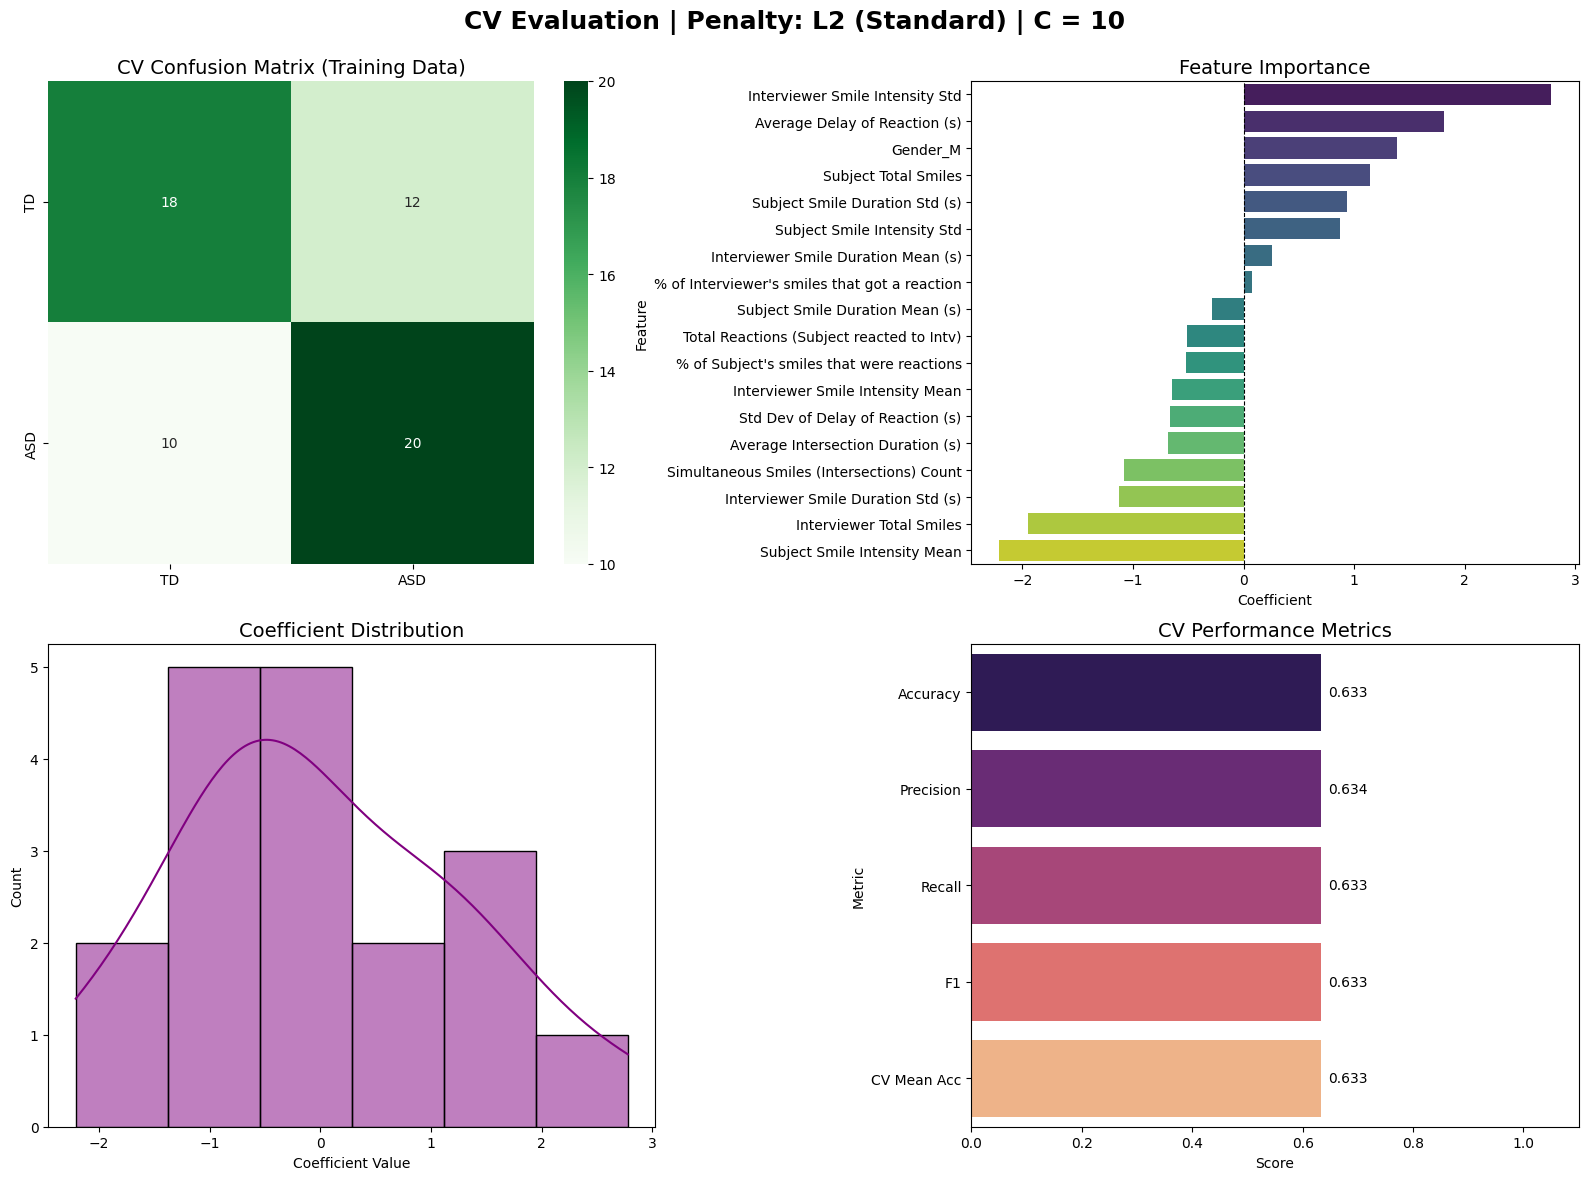


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.4000
Validation F1 Score: 0.4000


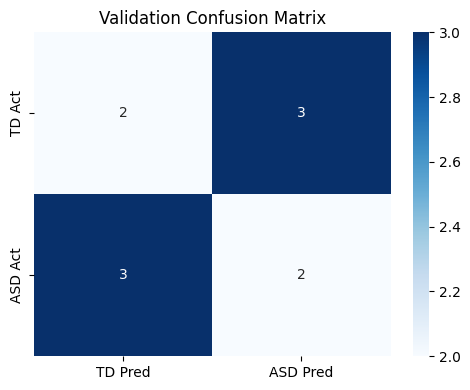

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-pack

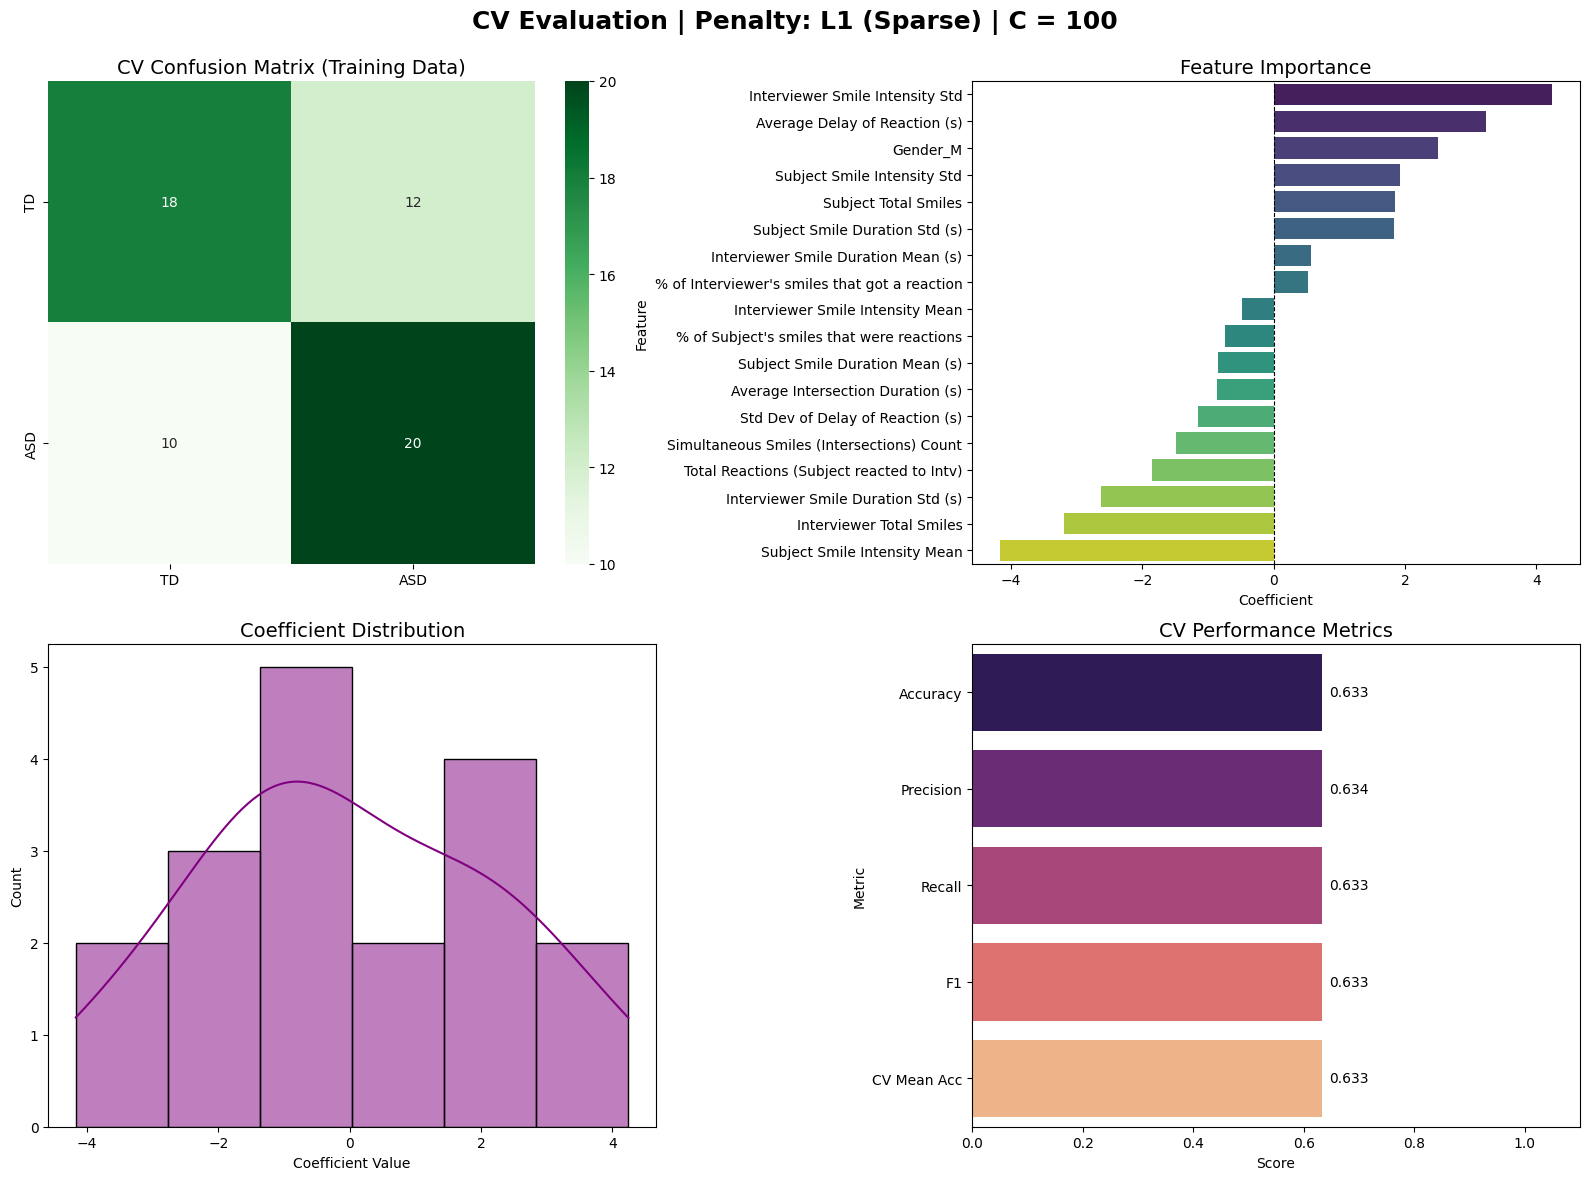


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.4000
Validation F1 Score: 0.4000


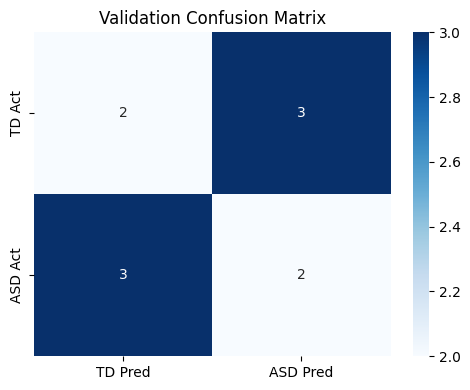


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-pack

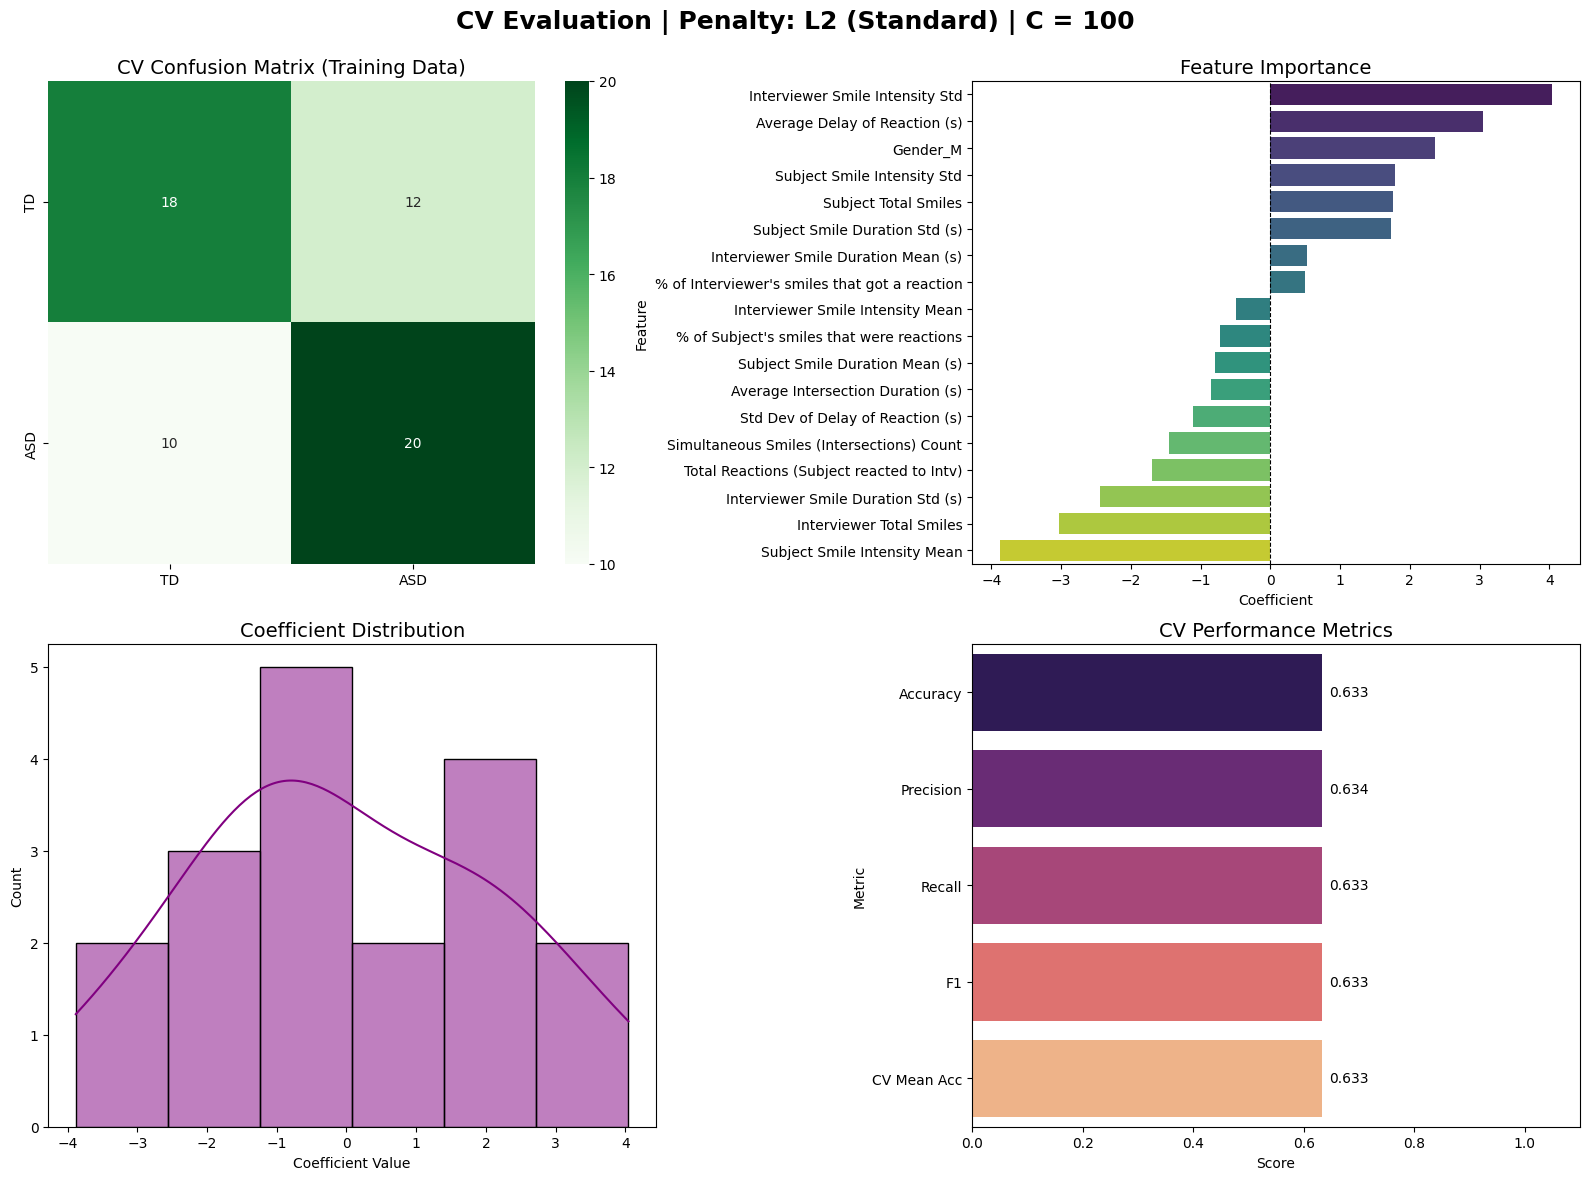


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.4000
Validation F1 Score: 0.4000


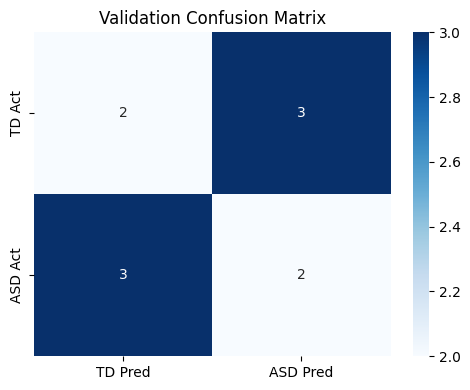

In [33]:
if __name__ == "__main__":
    c_values = [0.01, 0.1, 1, 10, 100]
    for c in c_values:
        # Experiment 1: Sparse model (L1 Regularization)
        # This will effectively prune features by pushing coefficients to zero.
        print("--- Running Experiment 1: L1 (Sparse/Pruned) ---")
        evaluate_logreg_with_kfold(use_l1=True, C_value=c)
        
        # Experiment 2: Standard model (L2 Regularization)
        # This will keep all features and distribute weights more evenly.
        print("\n--- Running Experiment 2: L2 (Standard) ---")
        evaluate_logreg_with_kfold(use_l1=False, C_value=c)

In [36]:
def evaluate_logreg_with_kfold_poly(K_FOLDS=5, use_l1=True, C_value=1.0, max_iter=1000, poly_degree=2):
    """
    Evaluates Logistic Regression with Polynomial Features. 
    Displays a 2x2 figure on training data, followed by validation on the holdout set.
    """
    if not os.path.exists(DATA_PATH):
        print(f"Error: '{DATA_PATH}' not found.")
        return

    df = pd.read_csv(DATA_PATH)
    
    # Unpack all four variables from the updated prepare_data function
    X_train, X_val, y_train, y_val = prepare_data(df)

    # Use l1_ratio instead of penalty. 1.0 = L1 (Sparse), 0.0 = L2 (Standard)
    ratio = 1.0 if use_l1 else 0.0
    
    pipeline = Pipeline([
        ('poly', PolynomialFeatures(degree=poly_degree, include_bias=False)), # Added Polynomial Features
        ('scaler', StandardScaler()),
        ('log_reg', LogisticRegression(
            penalty='elasticnet',   # Required for l1_ratio to function cleanly in saga
            l1_ratio=ratio,         
            C=C_value, 
            solver='saga',          
            max_iter=max_iter, 
            random_state=42
        ))
    ])

    cv_strategy = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    # Apply CV only to the training set
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv_strategy, scoring='accuracy')
    y_pred = cross_val_predict(pipeline, X_train, y_train, cv=cv_strategy)

    # Metrics DataFrame for plotting
    metrics_df = pd.DataFrame({
        "Metric": ["Accuracy", "Precision", "Recall", "F1", "CV Mean Acc"],
        "Score": [
            accuracy_score(y_train, y_pred),
            precision_score(y_train, y_pred, average='weighted', zero_division=0),
            recall_score(y_train, y_pred, average='weighted', zero_division=0),
            f1_score(y_train, y_pred, average='weighted', zero_division=0),
            cv_scores.mean()
        ]
    })

    # Fit pipeline to extract coefficients and feature names
    pipeline.fit(X_train, y_train)
    
    # Extract the new feature names generated by PolynomialFeatures
    poly_feature_names = pipeline.named_steps['poly'].get_feature_names_out(X_train.columns)
    
    coefs = pd.DataFrame({
        'Feature': poly_feature_names,
        'Coefficient': pipeline.named_steps['log_reg'].coef_[0]
    })
    
    # Create an absolute value column to find the most impactful features (positive or negative)
    coefs['Abs_Coef'] = np.abs(coefs['Coefficient'])
    
    # Sort by absolute coefficient and take the Top 20 for cleaner plotting
    top_coefs = coefs.sort_values(by='Abs_Coef', ascending=False).head(20)

    # --- 2x2 Subplot Visualization for Notebook Display ---
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    penalty_display = "L1 (Sparse)" if use_l1 else "L2 (Standard)"
    fig.suptitle(f'CV Evaluation | Polynomial Degree: {poly_degree} | Penalty: {penalty_display} | C = {C_value}', fontsize=18, fontweight='bold')
    
    # 1. Confusion Matrix (Top-Left)
    sns.heatmap(confusion_matrix(y_train, y_pred), annot=True, fmt='d', cmap='Greens', ax=axes[0, 0],
                xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
    axes[0, 0].set_title('CV Confusion Matrix (Training Data)', fontsize=14)

    # 2. Feature Importance (Top-Right) - Using top_coefs to prevent overlapping text
    sns.barplot(x='Coefficient', y='Feature', data=top_coefs, ax=axes[0, 1], hue='Feature', palette='viridis', legend=False)
    axes[0, 1].set_title('Top 20 Feature Importances', fontsize=14)
    axes[0, 1].axvline(x=0, color='black', linestyle='--', linewidth=0.8)

    # 3. Coefficient Distribution (Bottom-Left) - Still plots distribution of ALL features
    sns.histplot(coefs['Coefficient'], kde=True, color='purple', ax=axes[1, 0])
    axes[1, 0].set_title(f'Coefficient Distribution (Total Features: {len(coefs)})', fontsize=14)
    axes[1, 0].set_xlabel('Coefficient Value')

    # 4. Metrics Histogram (Bottom-Right)
    sns.barplot(x='Score', y='Metric', data=metrics_df, ax=axes[1, 1], hue='Metric', palette='magma', legend=False)
    axes[1, 1].set_title('CV Performance Metrics', fontsize=14)
    axes[1, 1].set_xlim(0, 1.1) 
    
    # Add values on bars
    for i in axes[1, 1].containers:
        axes[1, 1].bar_label(i, fmt='%.3f', padding=5)

    plt.tight_layout()
    fig.subplots_adjust(top=0.92) 
    plt.show() 

    # --- 5. Validate on the Holdout Set ---
    print("\n" + "="*45)
    print("VALIDATION SET RESULTS (10 Held-out Subjects)")
    print("="*45)
    
    # Predict on the unseen validation data
    y_val_pred = pipeline.predict(X_val)
    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = f1_score(y_val, y_val_pred, average='weighted', zero_division=0)
    
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation F1 Score: {val_f1:.4f}")
    
    # Display Validation Confusion Matrix
    cm_val = confusion_matrix(y_val, y_val_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['TD Pred', 'ASD Pred'], 
                yticklabels=['TD Act', 'ASD Act'])
    plt.title('Validation Confusion Matrix')
    plt.tight_layout()
    plt.show()

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

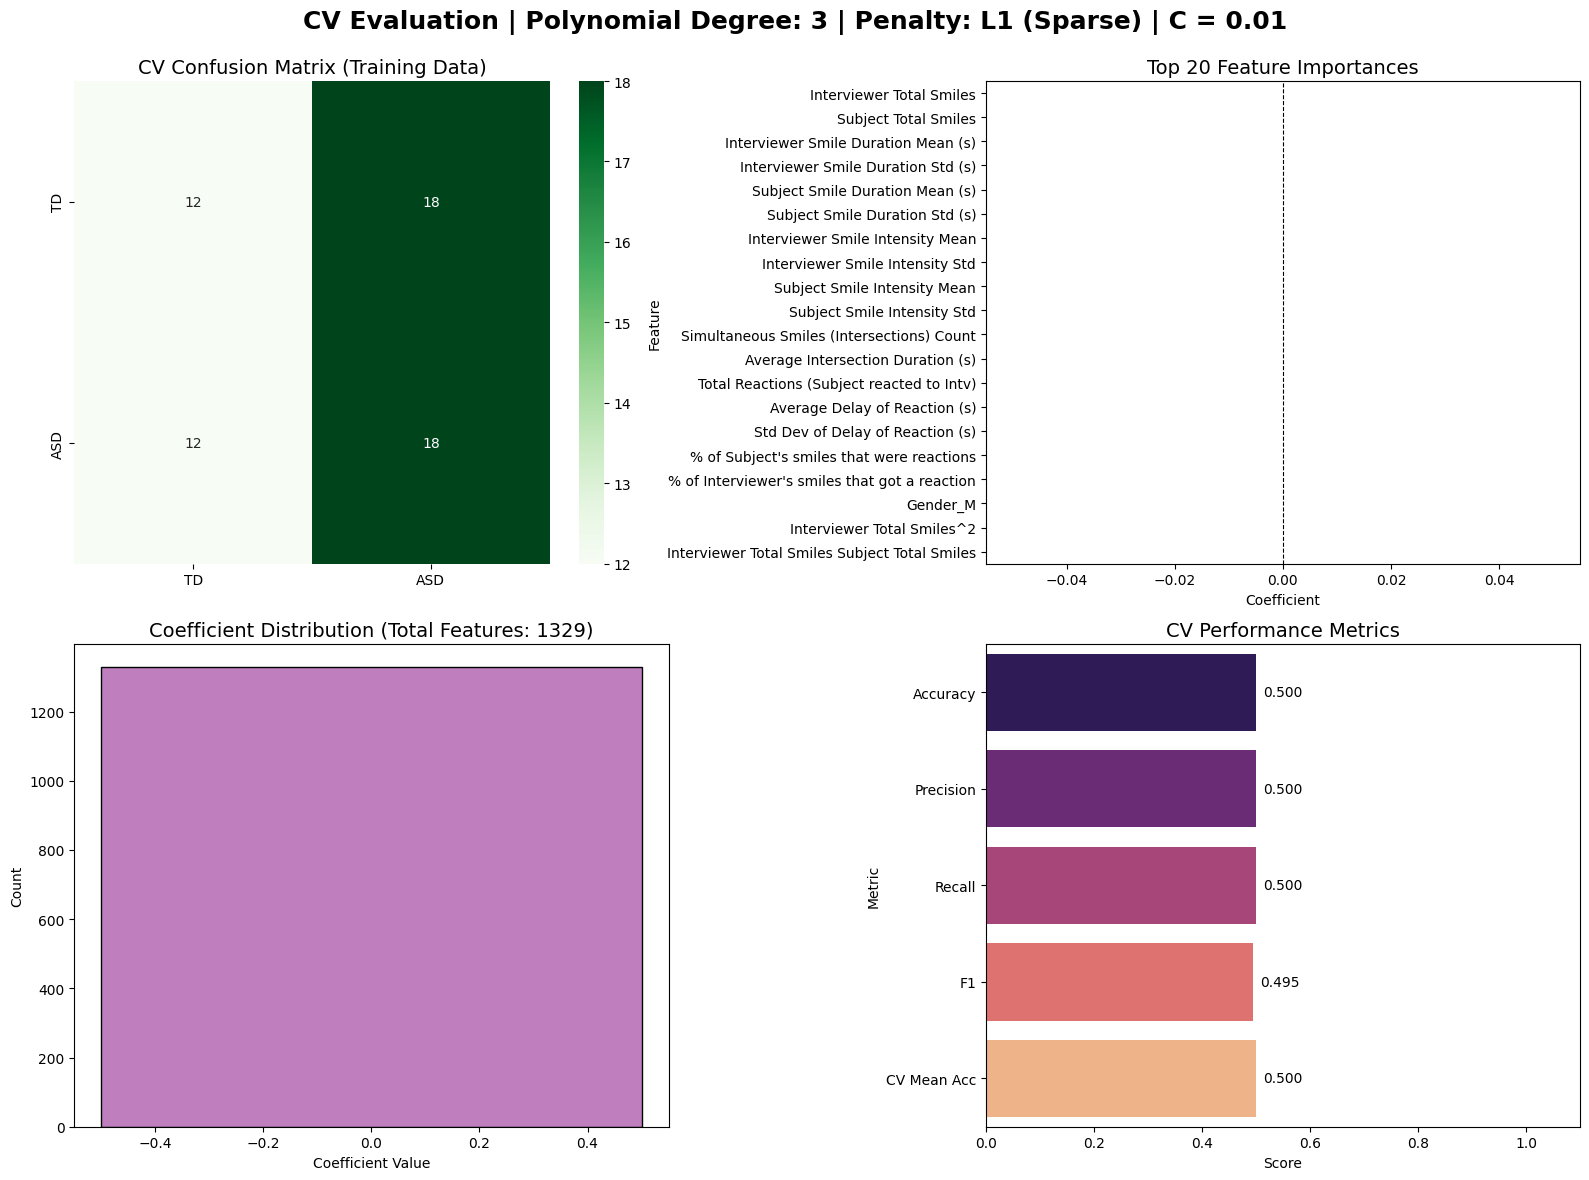


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.3333


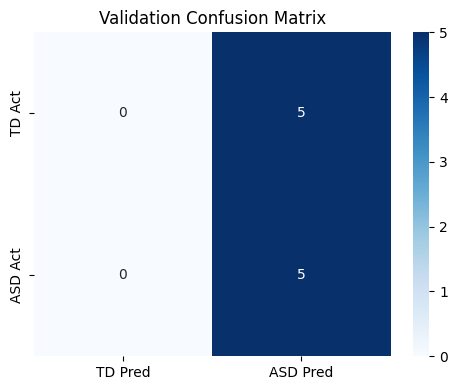


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

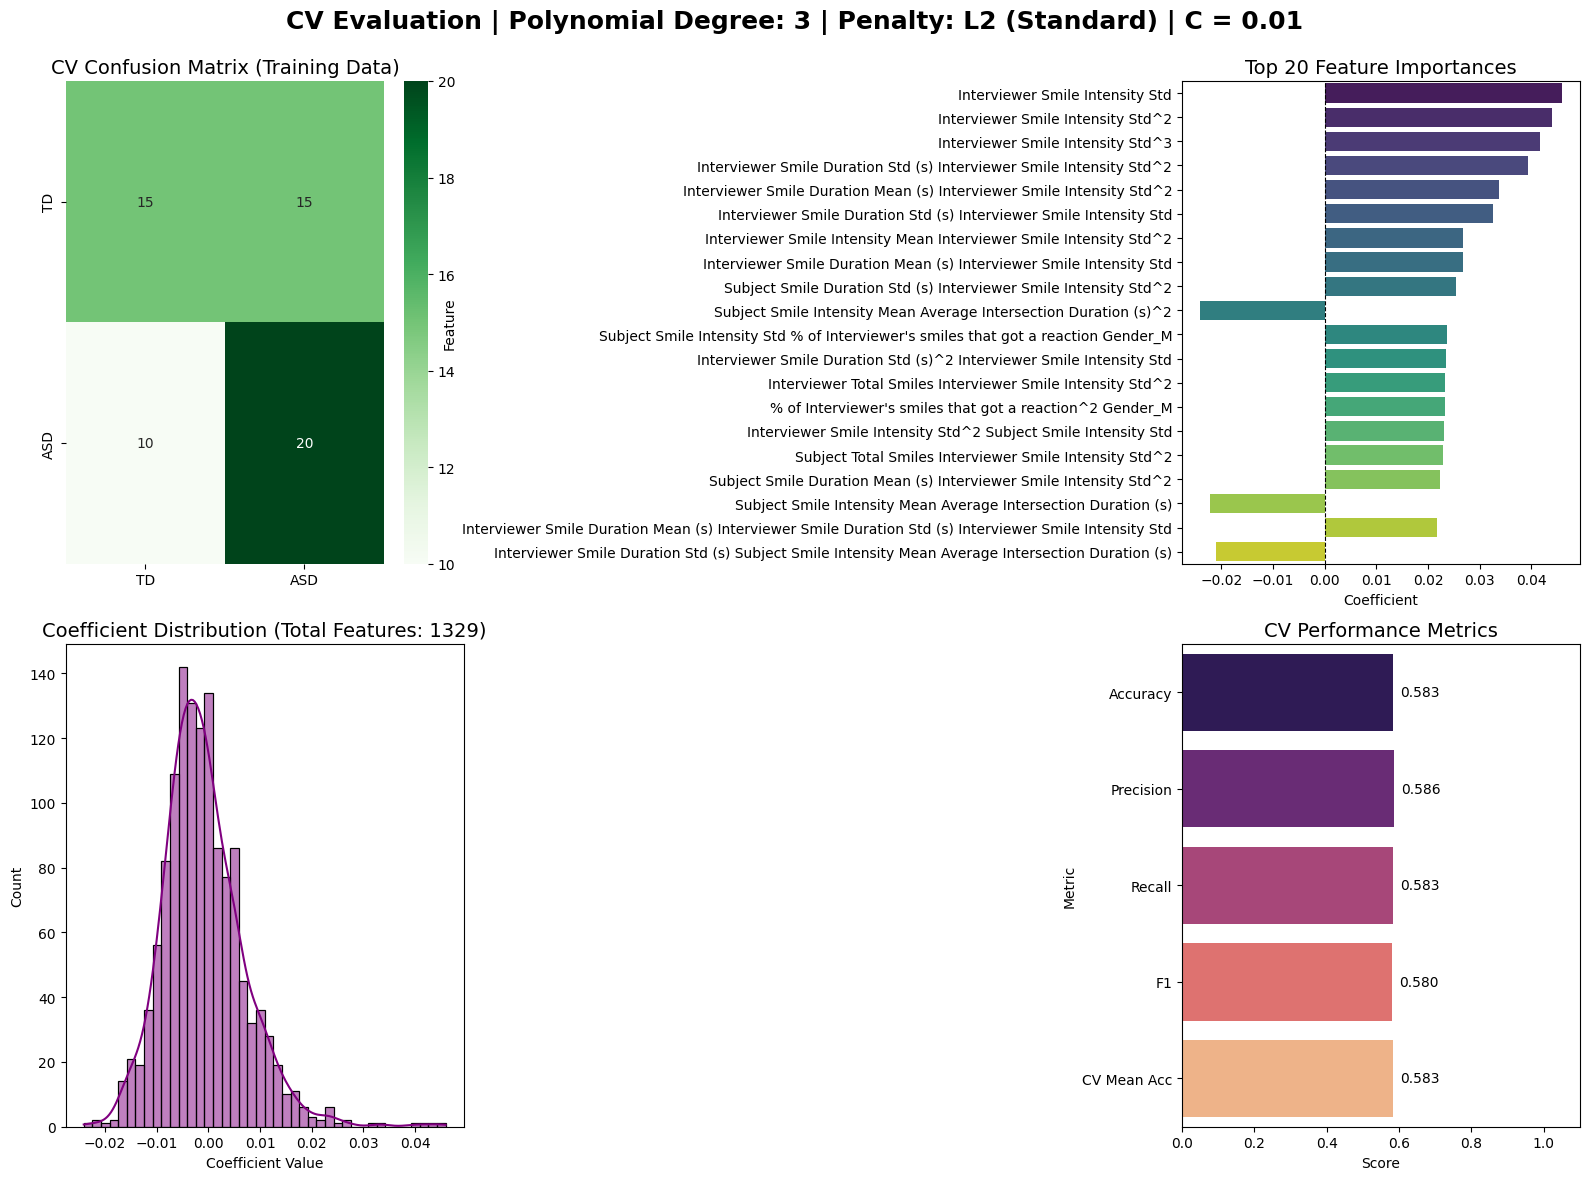


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.6000
Validation F1 Score: 0.6000


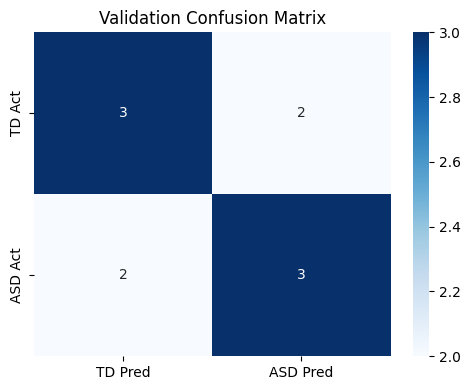

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warning

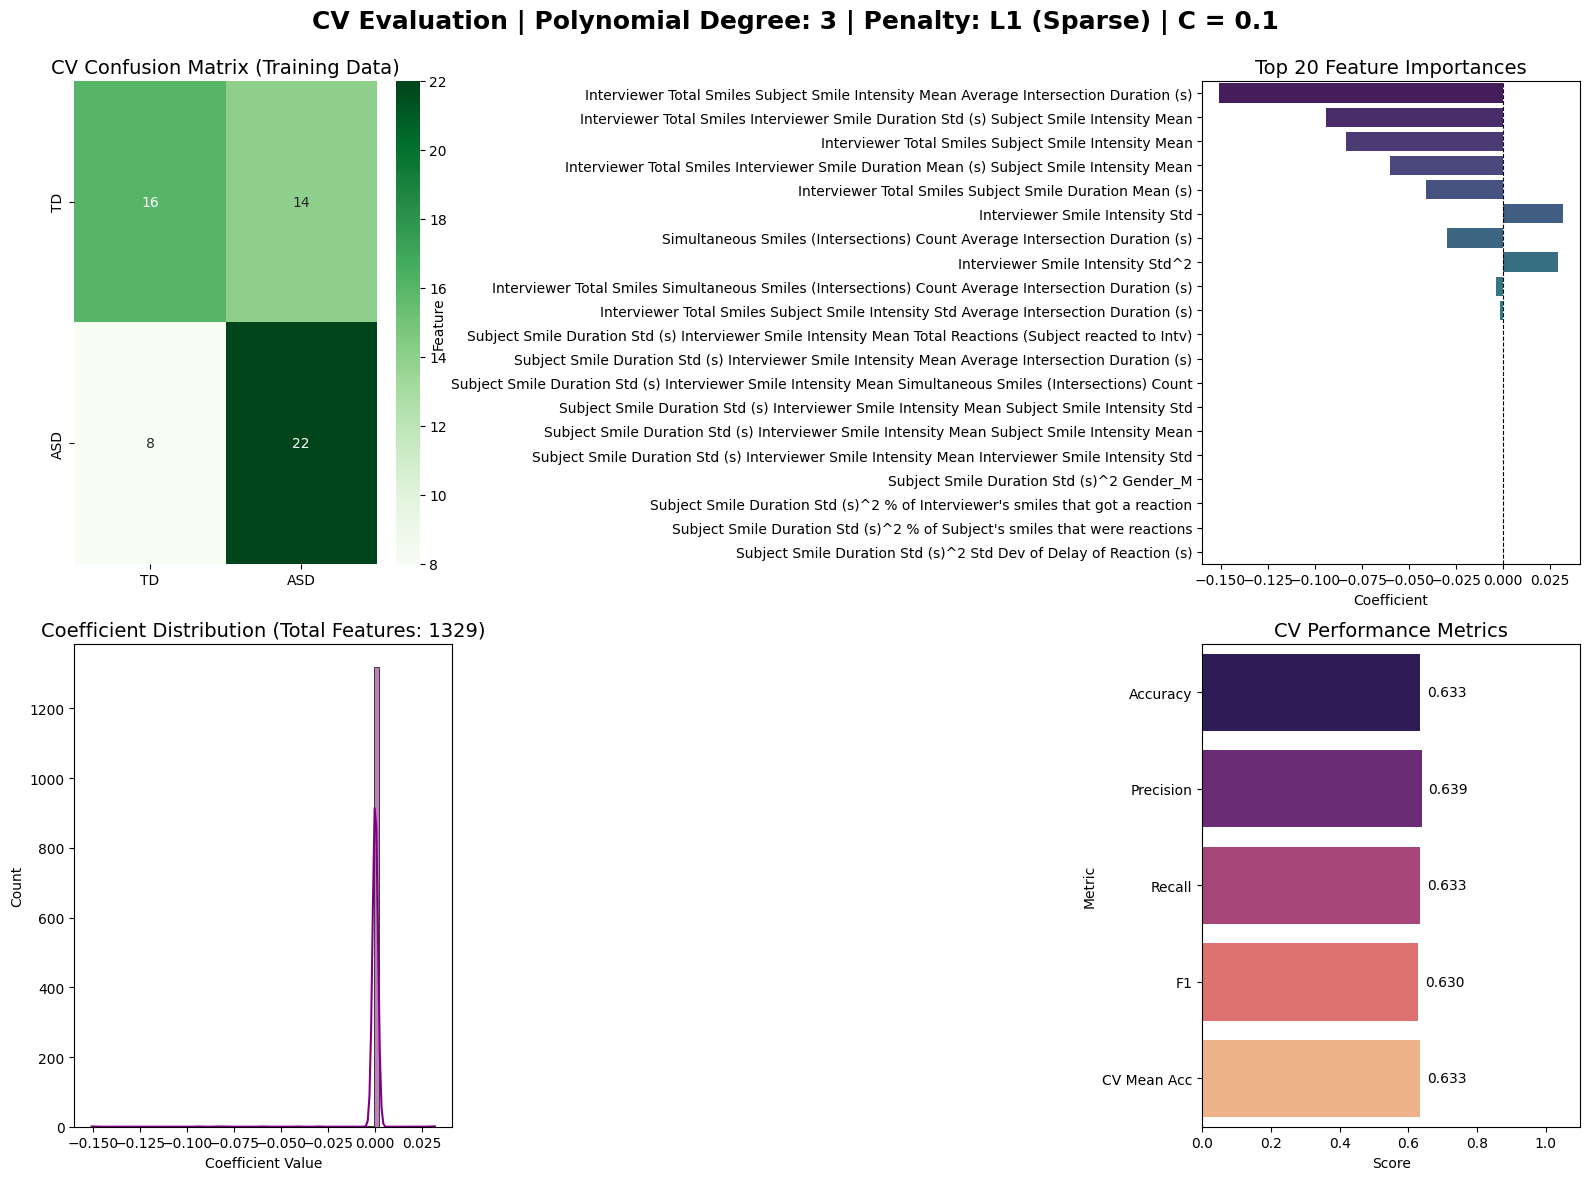


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.6000
Validation F1 Score: 0.6000


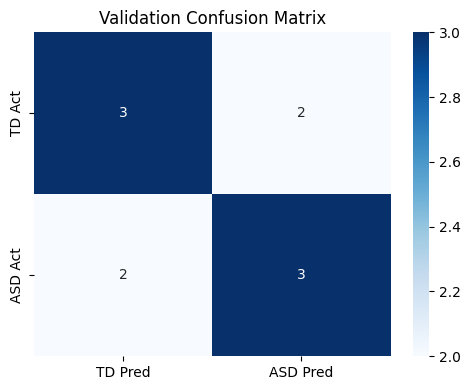


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warning

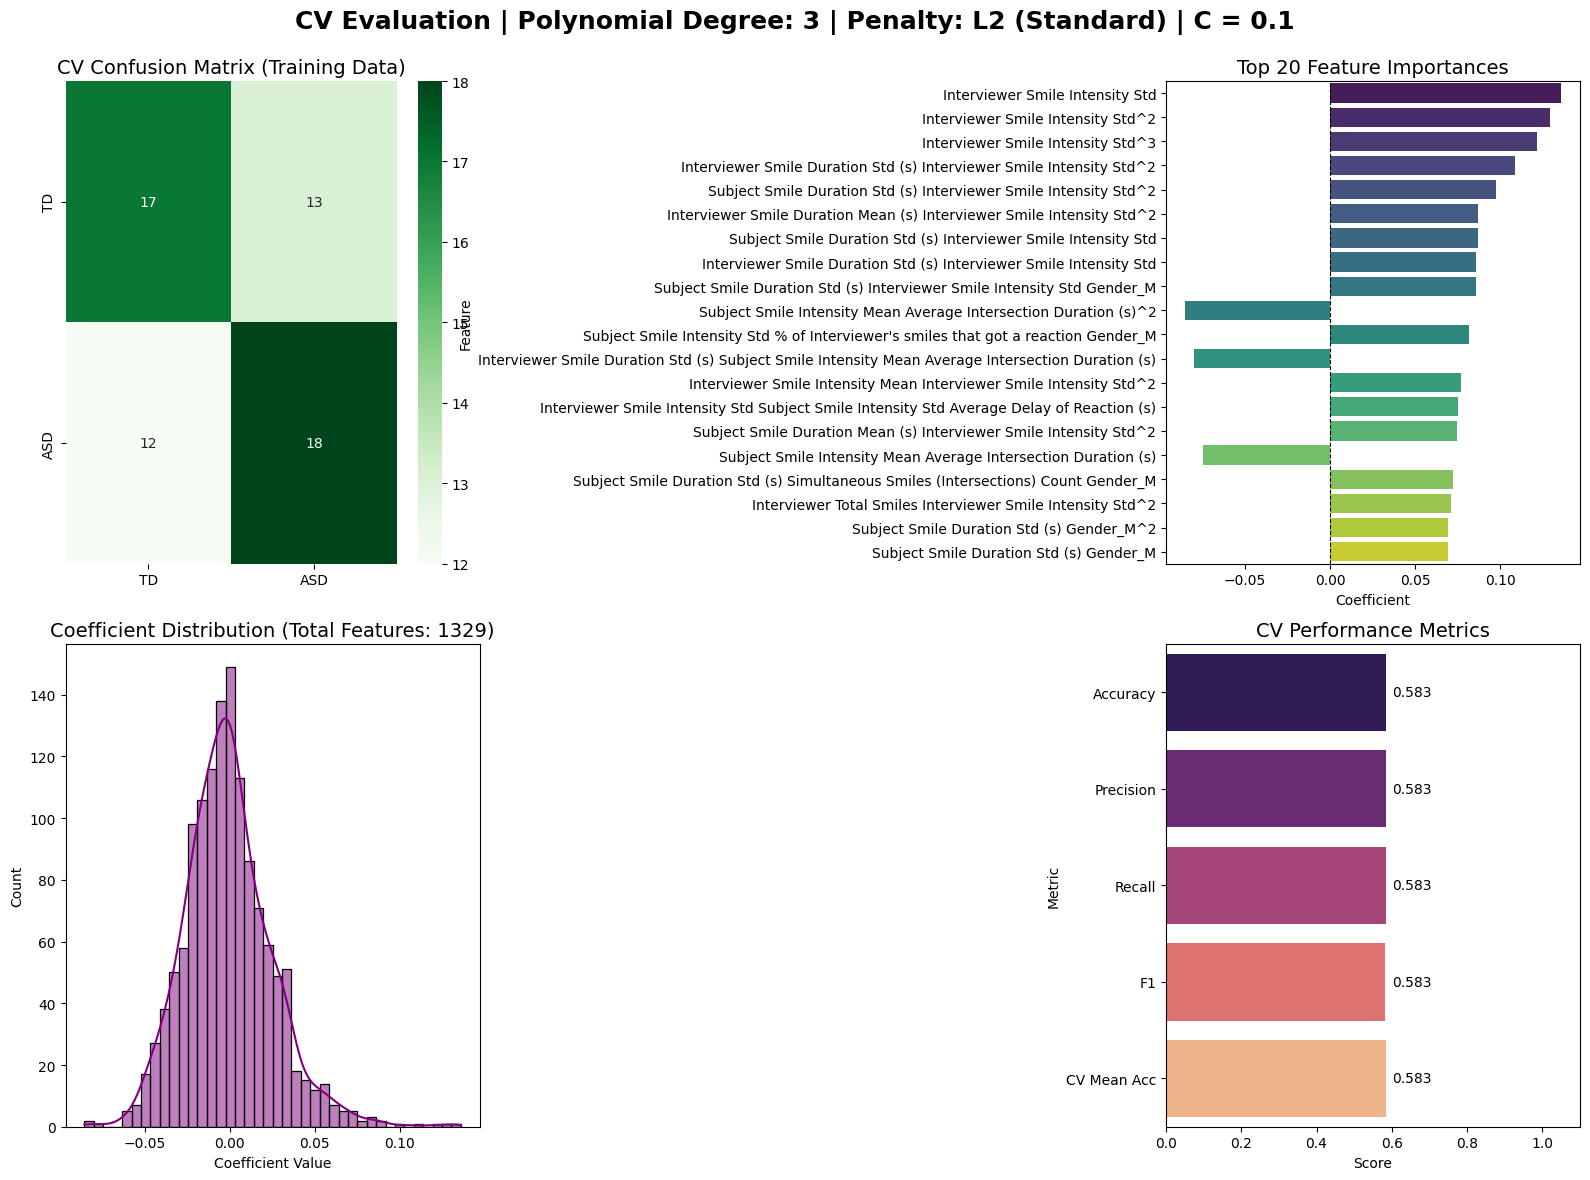


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4949


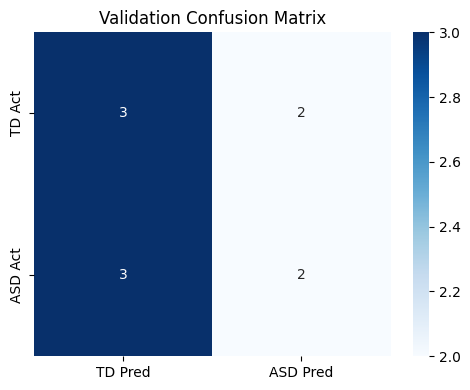

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warning

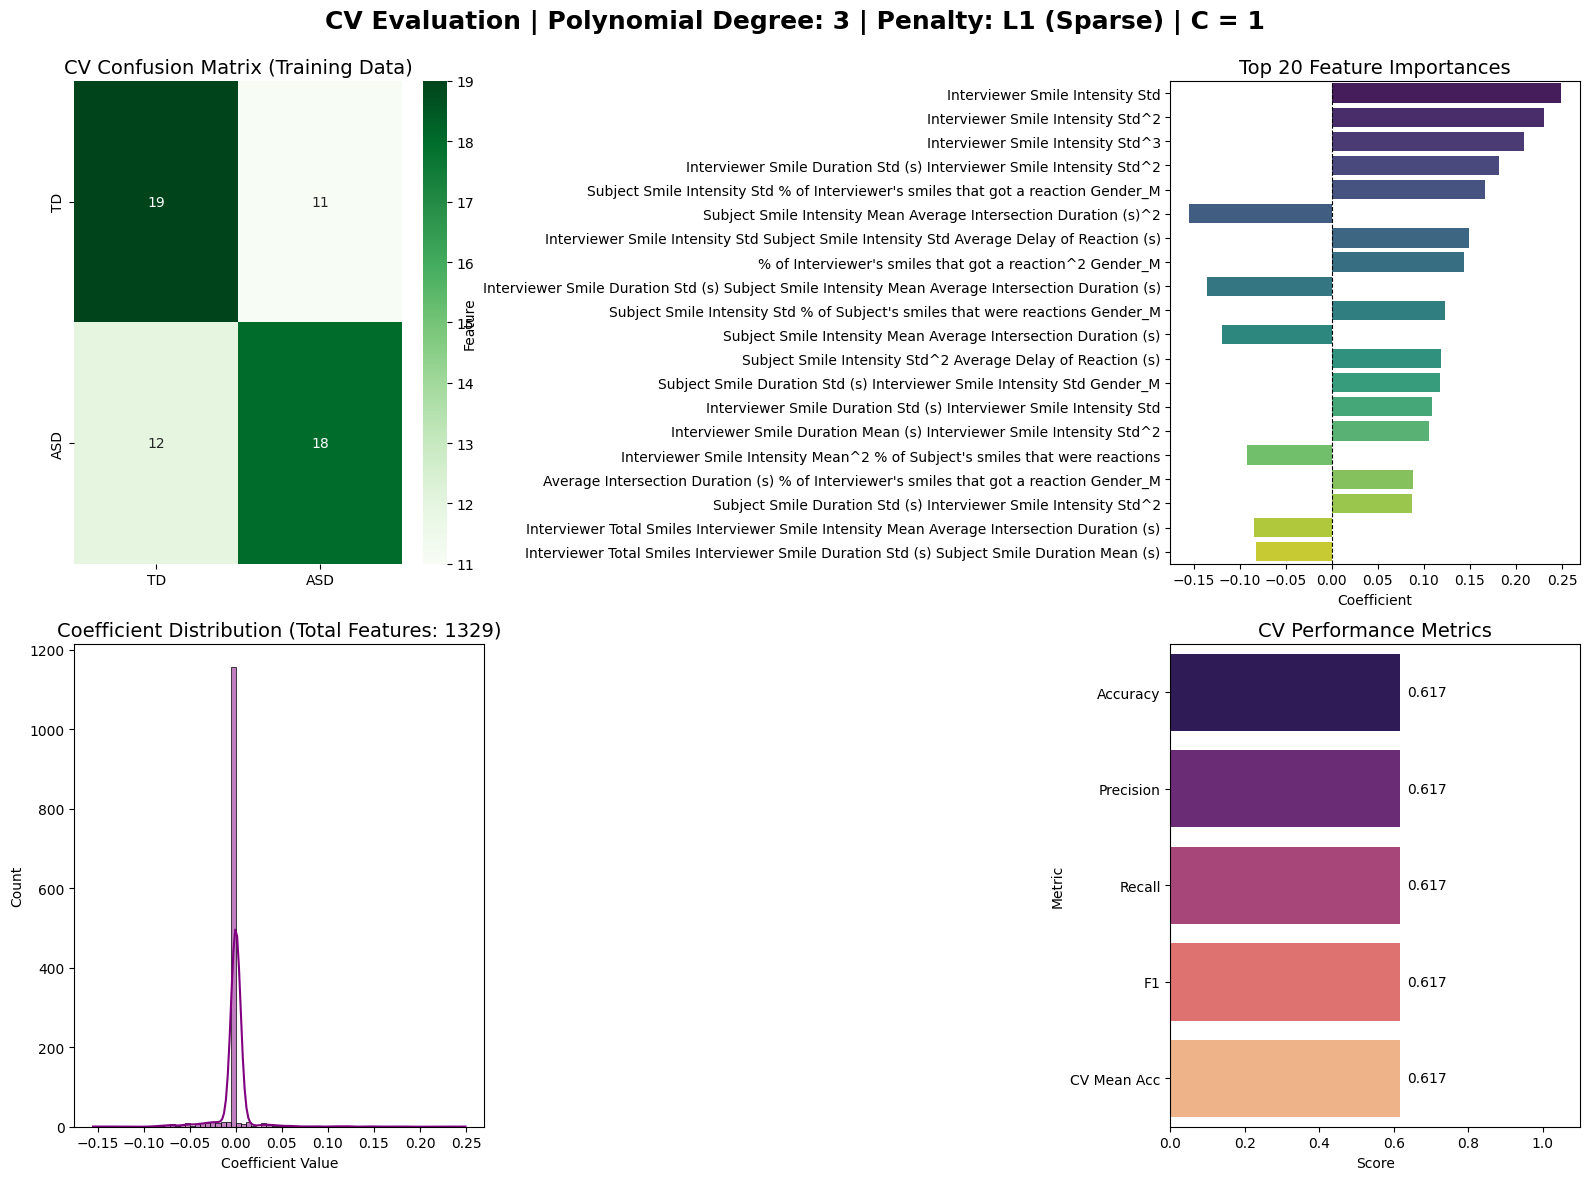


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.6000
Validation F1 Score: 0.5833


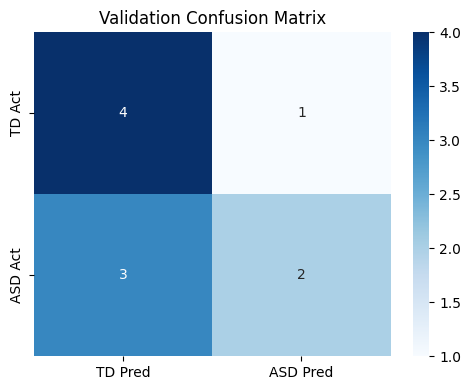


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warning

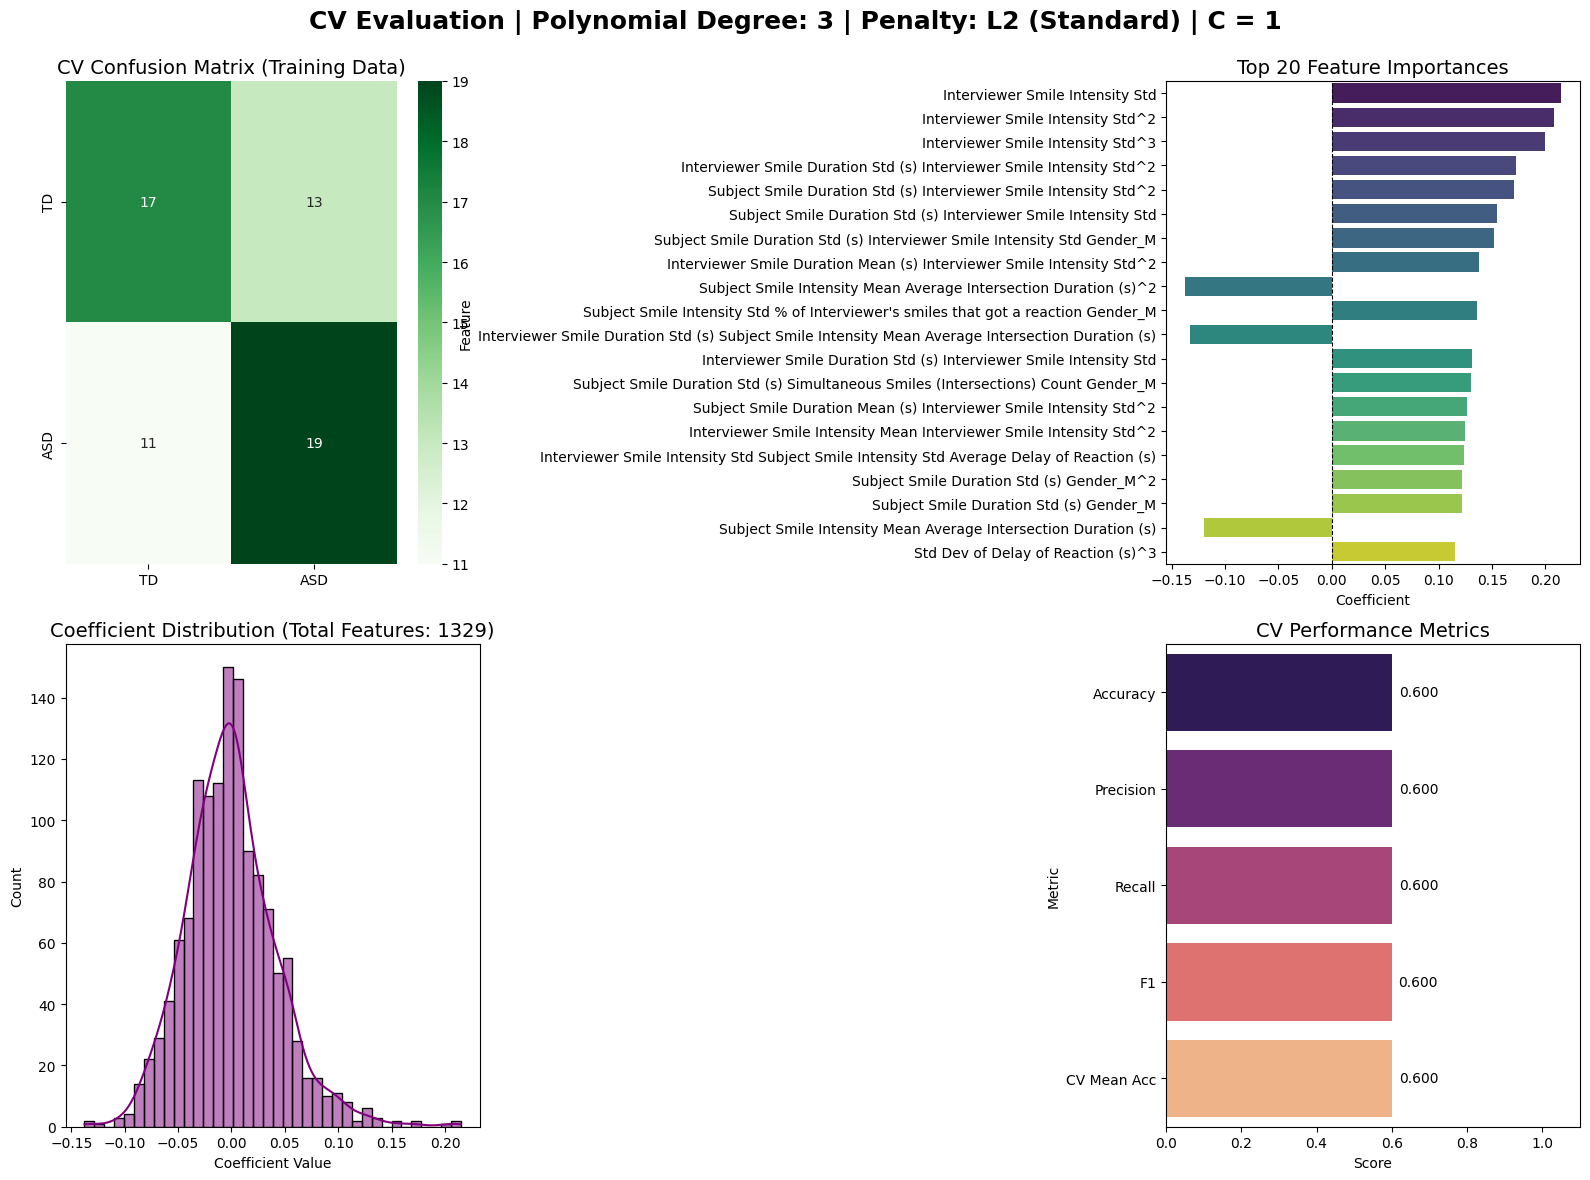


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.6000
Validation F1 Score: 0.5833


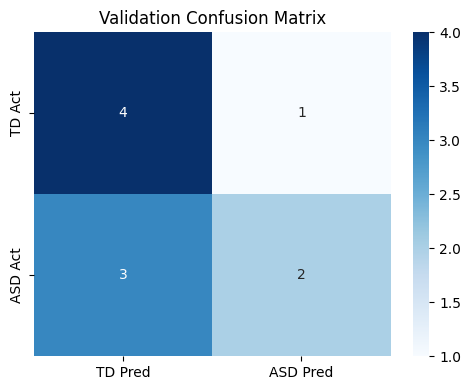

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warning

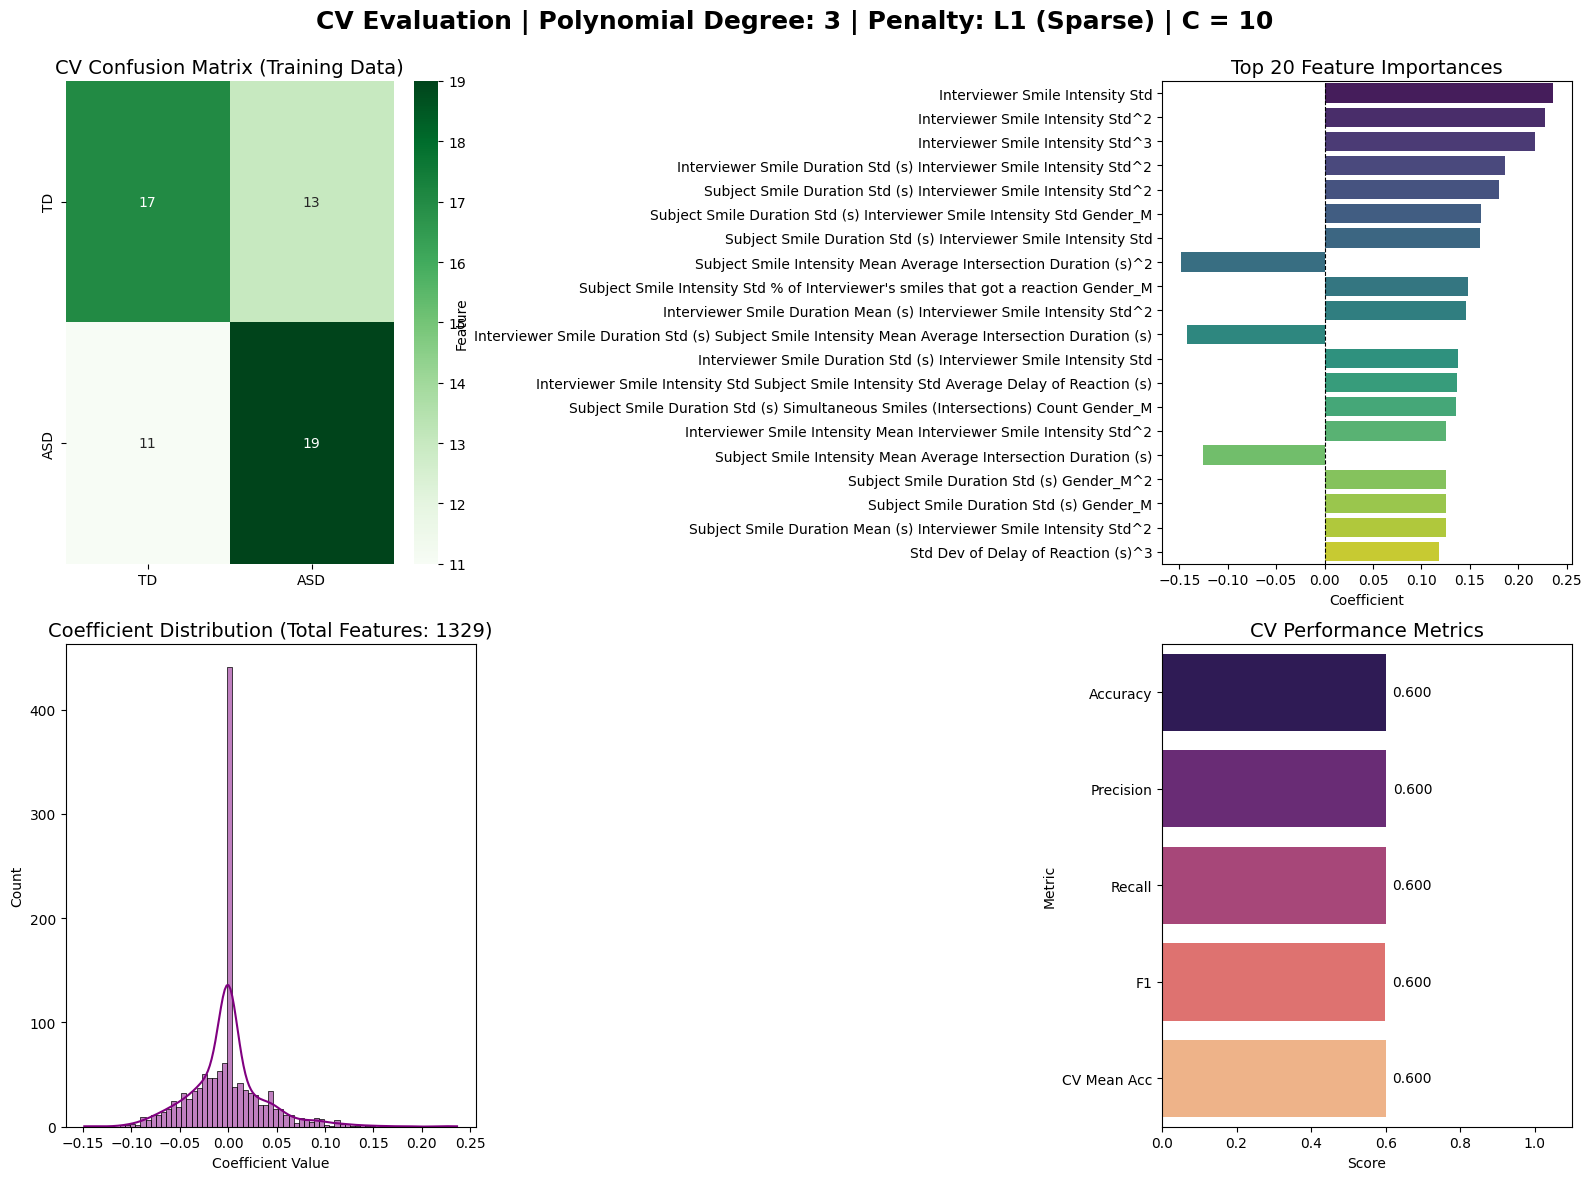


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4949


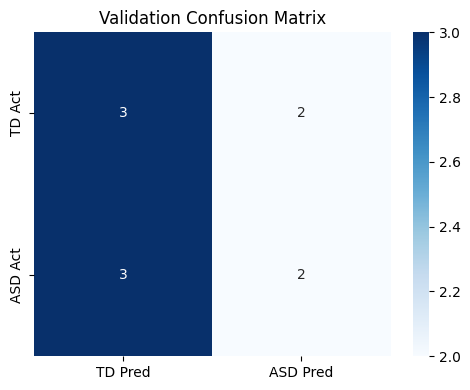


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warning

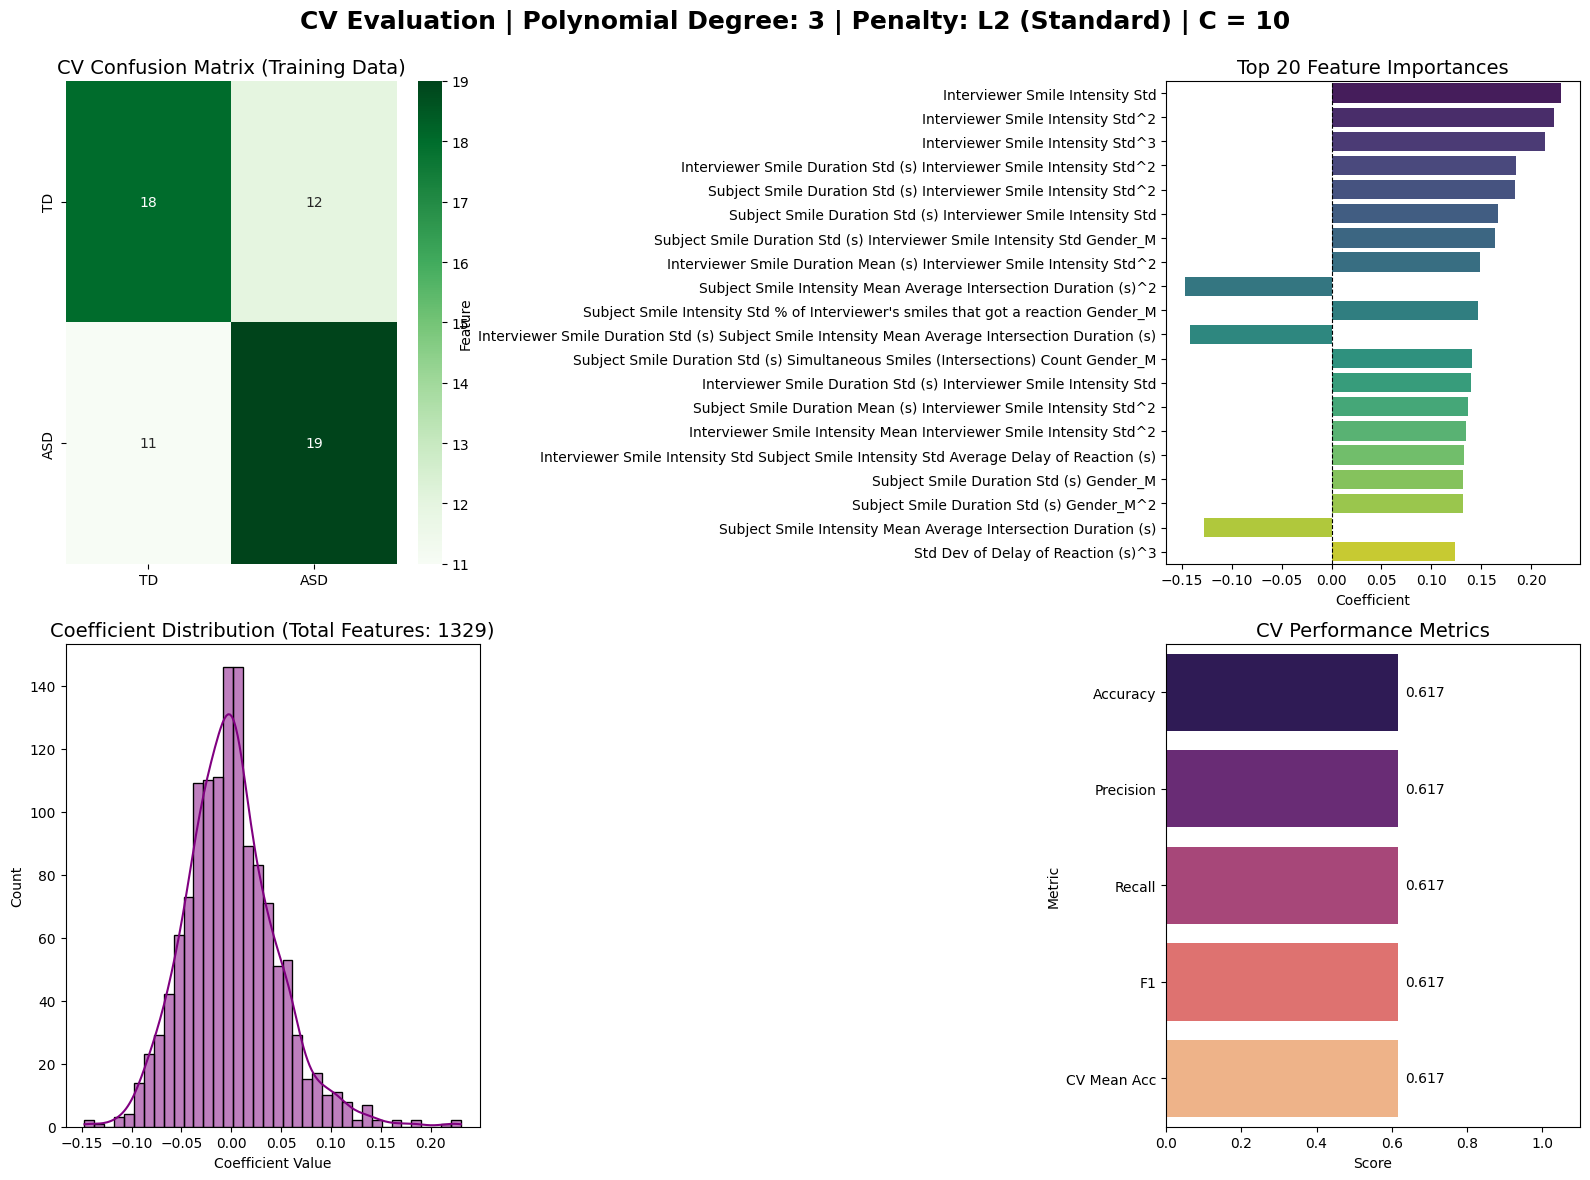


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.6000
Validation F1 Score: 0.5833


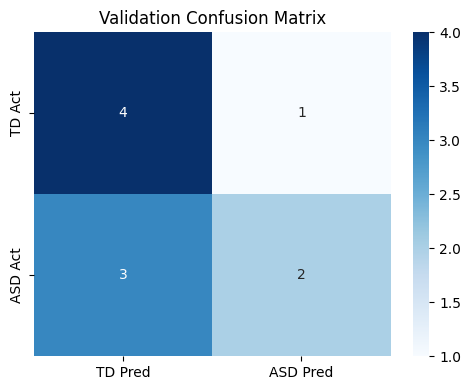

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warning

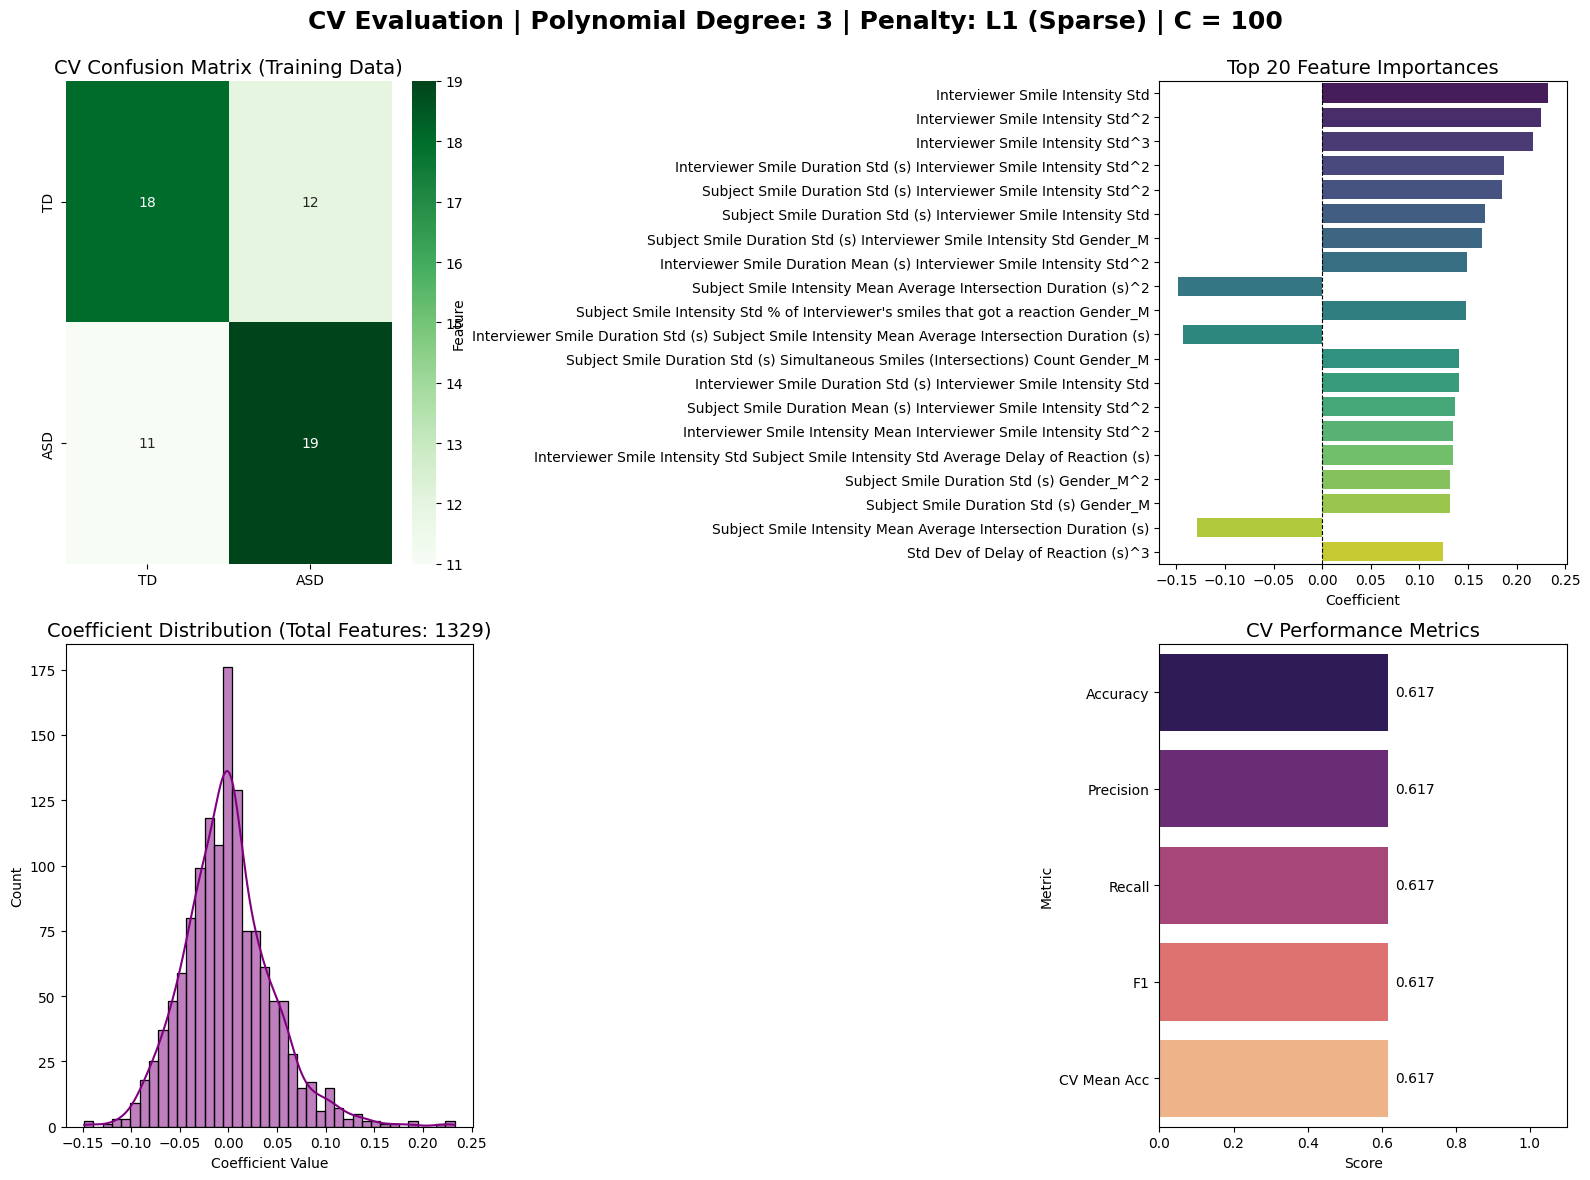


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.6000
Validation F1 Score: 0.5833


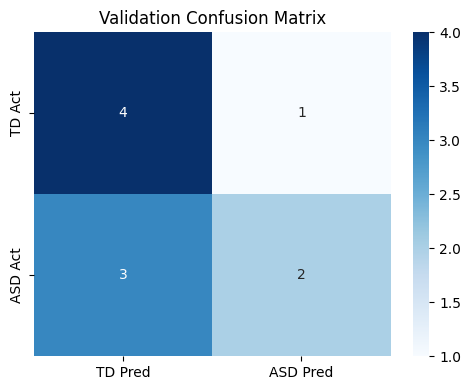


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warning

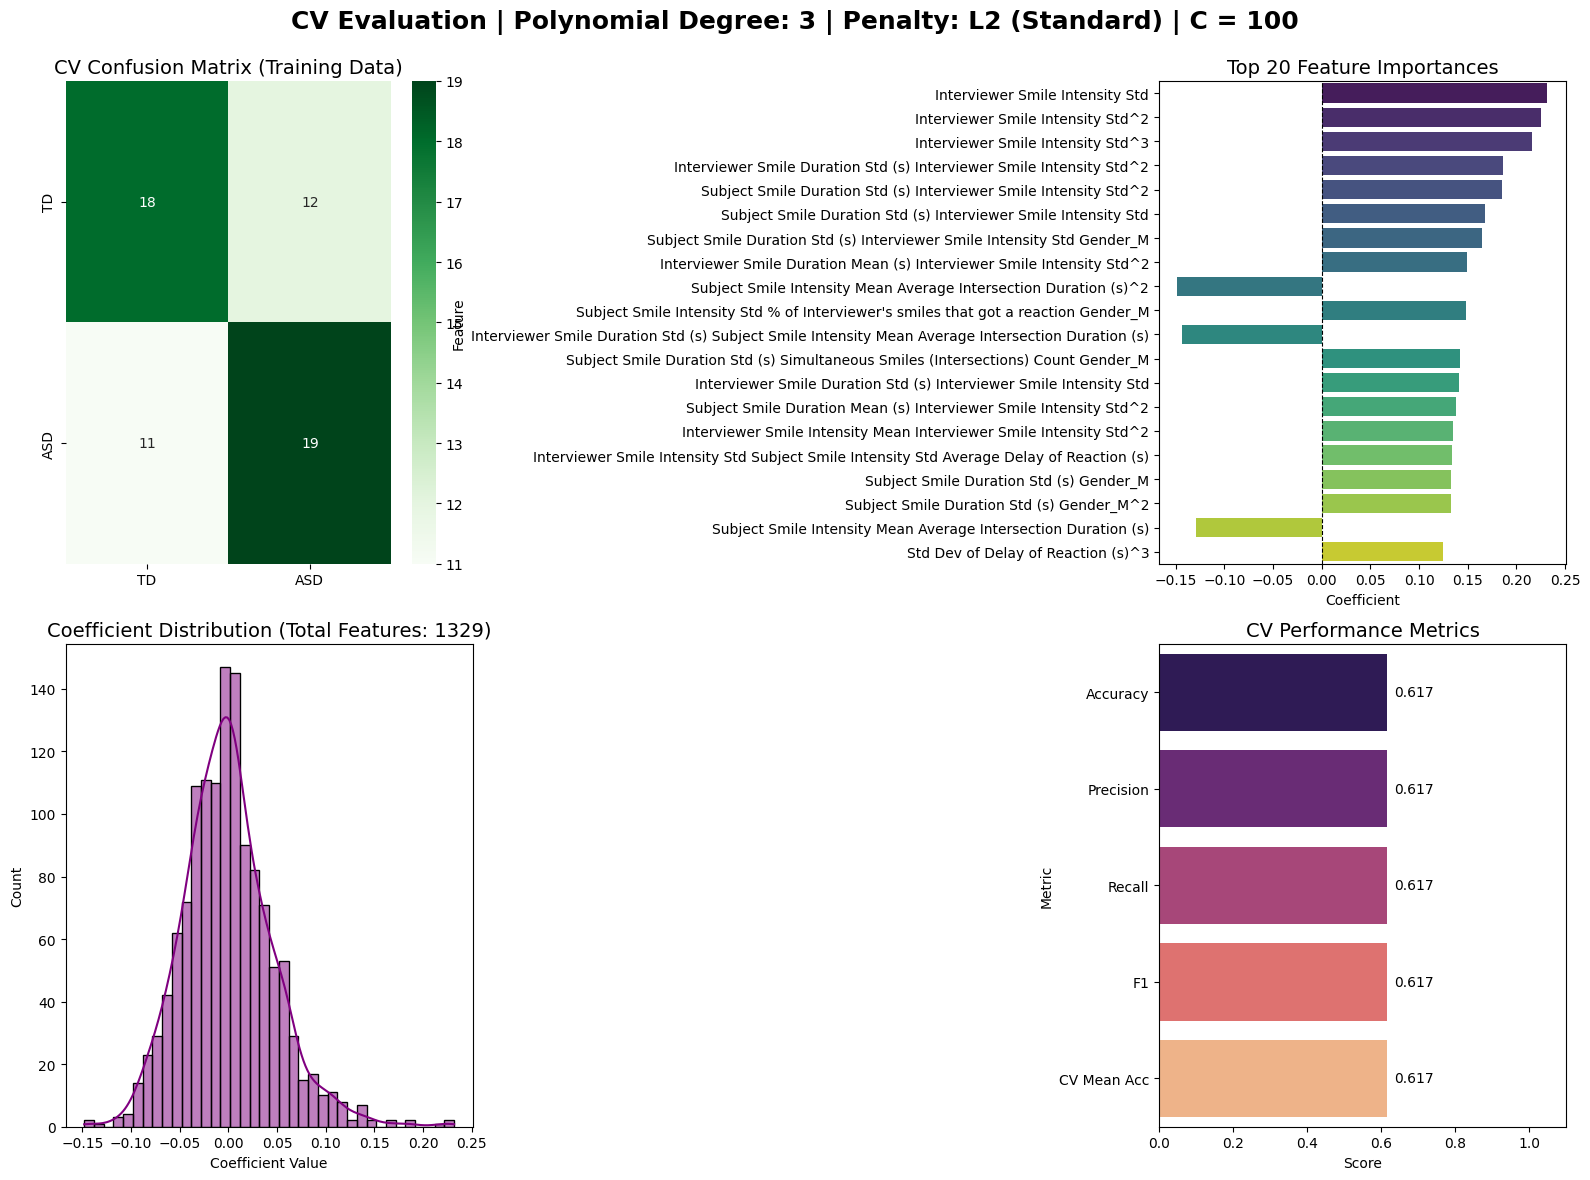


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.6000
Validation F1 Score: 0.5833


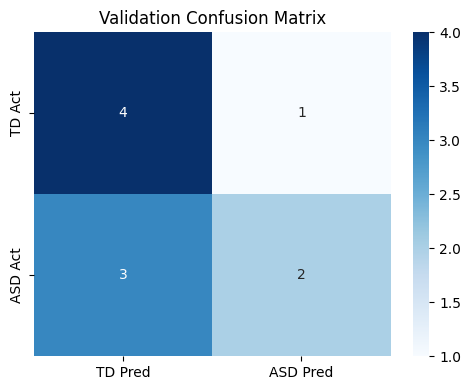

In [40]:
if __name__ == "__main__":
    c_values = [0.01, 0.1, 1, 10, 100]
    for c in c_values:
        # Experiment 1: Sparse model (L1 Regularization)
        # This will effectively prune features by pushing coefficients to zero.
        print("--- Running Experiment 1: L1 (Sparse/Pruned) ---")
        evaluate_logreg_with_kfold_poly(use_l1=True, C_value=c, poly_degree=3)
        
        # Experiment 2: Standard model (L2 Regularization)
        # This will keep all features and distribute weights more evenly.
        print("\n--- Running Experiment 2: L2 (Standard) ---")
        evaluate_logreg_with_kfold_poly(use_l1=False, C_value=c, poly_degree=3)

In [41]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [45]:
def evaluate_kmeans_clustering(clusters=2):
    """
    Applies K-Means (k=2) to the dataset, aligns the arbitrary cluster labels 
    with the true labels, and plots a PCA visualization.
    """
    if not os.path.exists(DATA_PATH):
        print(f"Error: '{DATA_PATH}' not found.")
        return

    df = pd.read_csv(DATA_PATH)
    
    # We will use the entire dataset for exploratory clustering
    # so we concatenate the splits from your prepare_data function
    X_train, X_val, y_train, y_val = prepare_data(df)
    X = pd.concat([X_train, X_val])
    y = pd.concat([y_train, y_val])

    # 1. Scale the data (CRITICAL for distance-based algorithms like K-Means)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # 2. Apply K-Means
    print("\nRunning K-Means with 2 clusters...")
    # n_init='auto' suppresses scikit-learn warnings about initialization changes
    kmeans = KMeans(n_clusters=clusters, random_state=42, n_init='auto')
    cluster_labels = kmeans.fit_predict(X_scaled)

    # 3. Align Cluster Labels with True Labels
    # We check both alignments to see which matches the ground truth best.
    acc_direct = accuracy_score(y, cluster_labels)
    acc_flipped = accuracy_score(y, 1 - cluster_labels)

    if acc_flipped > acc_direct:
        aligned_labels = 1 - cluster_labels
        best_acc = acc_flipped
        print("Note: K-Means labels were flipped to align with ground truth.")
    else:
        aligned_labels = cluster_labels
        best_acc = acc_direct

    print(f"Clustering Accuracy (Compared to True Labels): {best_acc:.4f}")

    # 4. Display Confusion Matrix
    cm = confusion_matrix(y, aligned_labels)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
                xticklabels=['Cluster 0 (Predicted)', 'Cluster 1 (Predicted)'],
                yticklabels=['Class 0 (True)', 'Class 1 (True)'])
    plt.title(f'K-Means vs True Labels (Acc: {best_acc:.2f})')
    plt.tight_layout()
    plt.show()

    # 5. Visualization using PCA (Dimensionality Reduction to 2D)
    # This compresses all your features into 2 axes so we can plot them on a scatter graph
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    
    pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
    pca_df['True Label'] = y.values
    pca_df['K-Means Cluster'] = aligned_labels

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Plot True Labels
    sns.scatterplot(x='PC1', y='PC2', hue='True Label', data=pca_df, 
                    palette=['blue', 'red'], ax=axes[0], s=60, alpha=0.8)
    axes[0].set_title('Ground Truth (Actual Classes)', fontsize=14)
    
    # Plot K-Means Clusters
    sns.scatterplot(x='PC1', y='PC2', hue='K-Means Cluster', data=pca_df, 
                    palette=['blue', 'red'], ax=axes[1], s=60, alpha=0.8)
    axes[1].set_title('K-Means Clusters', fontsize=14)

    plt.suptitle('PCA Visualization: True Labels vs K-Means Clustering', fontsize=18, fontweight='bold')
    plt.tight_layout()
    plt.show()

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

Running K-Means with 2 clusters...
Note: K-Means labels were flipped to align with ground truth.
Clustering Accuracy (Compared to True Labels): 0.6857


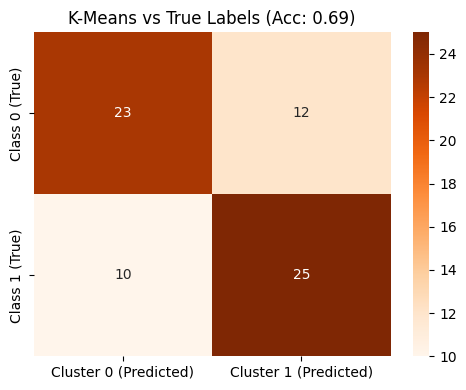

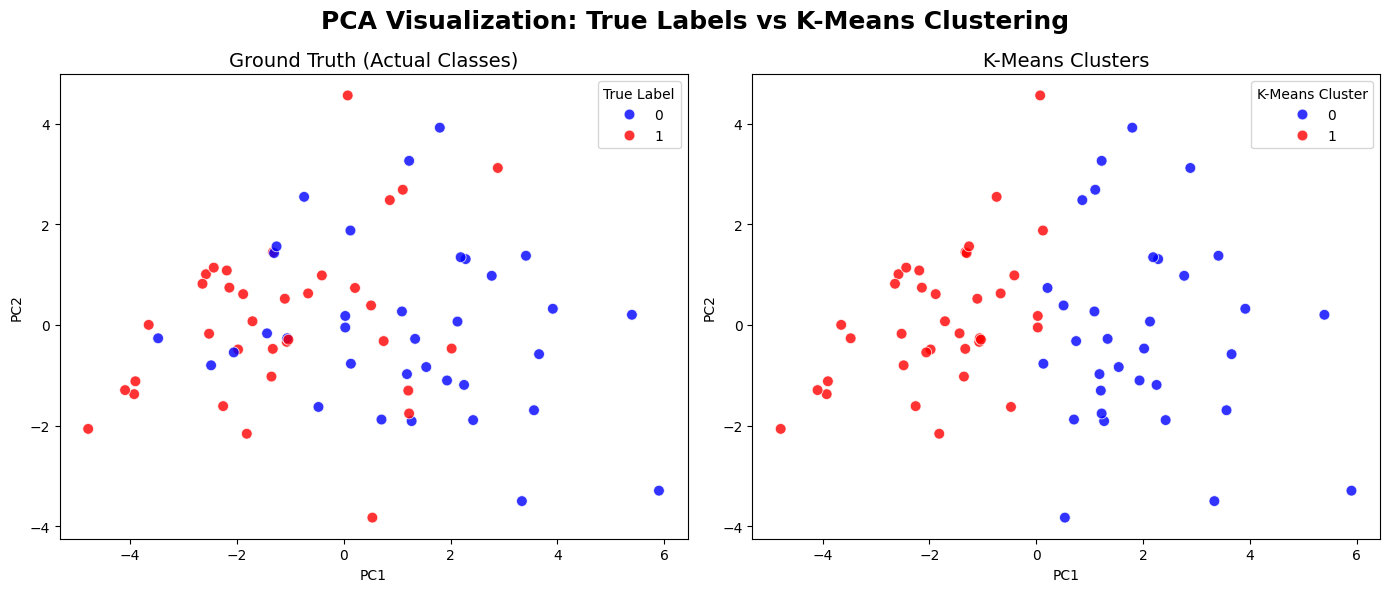

In [47]:
if __name__ == "__main__":
    evaluate_kmeans_clustering(2)

In [48]:
def evaluate_logreg_with_pca_kfold(K_FOLDS=5, use_l1=True, C_value=1.0, max_iter=1000):
    """
    Applies PCA to reduce to 2 components, then evaluates Logistic Regression.
    Displays a 2x2 figure on training data, followed by validation on the holdout set.
    """
    if not os.path.exists(DATA_PATH):
        print(f"Error: '{DATA_PATH}' not found.")
        return

    df = pd.read_csv(DATA_PATH)
    
    # Unpack all four variables from the updated prepare_data function
    X_train, X_val, y_train, y_val = prepare_data(df)

    # Use l1_ratio instead of penalty. 1.0 = L1 (Sparse), 0.0 = L2 (Standard)
    ratio = 1.0 if use_l1 else 0.0
    
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=2)), # NEW: Reduce to 2 Principal Components
        ('log_reg', LogisticRegression(
            penalty='elasticnet',   # Required to use l1_ratio with the 'saga' solver
            l1_ratio=ratio,         
            C=C_value, 
            solver='saga',          
            max_iter=max_iter, 
            random_state=42
        ))
    ])

    cv_strategy = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    # Apply CV only to the training set
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv_strategy, scoring='accuracy')
    y_pred = cross_val_predict(pipeline, X_train, y_train, cv=cv_strategy)

    # Metrics DataFrame for plotting
    metrics_df = pd.DataFrame({
        "Metric": ["Accuracy", "Precision", "Recall", "F1", "CV Mean Acc"],
        "Score": [
            accuracy_score(y_train, y_pred),
            precision_score(y_train, y_pred, average='weighted', zero_division=0),
            recall_score(y_train, y_pred, average='weighted', zero_division=0),
            f1_score(y_train, y_pred, average='weighted', zero_division=0),
            cv_scores.mean()
        ]
    })

    # Coefficients
    pipeline.fit(X_train, y_train)
    coefs = pd.DataFrame({
        'Feature': ['PC1', 'PC2'], # Update names since original features are gone
        'Coefficient': pipeline.named_steps['log_reg'].coef_[0]
    }).sort_values(by='Coefficient', ascending=False)

    # --- 2x2 Subplot Visualization for Notebook Display ---
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    penalty_display = "L1 (Sparse)" if use_l1 else "L2 (Standard)"
    fig.suptitle(f'PCA (2 Components) + CV Evaluation | Penalty: {penalty_display} | C = {C_value}', fontsize=18, fontweight='bold')
    
    # 1. Confusion Matrix (Top-Left)
    sns.heatmap(confusion_matrix(y_train, y_pred), annot=True, fmt='d', cmap='Greens', ax=axes[0, 0],
                xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    axes[0, 0].set_title('CV Confusion Matrix (Training Data)', fontsize=14)

    # 2. Feature Importance (Top-Right)
    sns.barplot(x='Coefficient', y='Feature', data=coefs, ax=axes[0, 1], hue='Feature', palette='viridis', legend=False)
    axes[0, 1].set_title('Principal Component Importance', fontsize=14)
    axes[0, 1].axvline(x=0, color='black', linestyle='--', linewidth=0.8)

    # 3. Coefficient Distribution (Bottom-Left)
    sns.histplot(coefs['Coefficient'], kde=True, color='purple', ax=axes[1, 0], bins=10)
    axes[1, 0].set_title('Coefficient Distribution (Only 2 Components)', fontsize=14)
    axes[1, 0].set_xlabel('Coefficient Value')

    # 4. Metrics Histogram (Bottom-Right)
    sns.barplot(x='Score', y='Metric', data=metrics_df, ax=axes[1, 1], hue='Metric', palette='magma', legend=False)
    axes[1, 1].set_title('CV Performance Metrics', fontsize=14)
    axes[1, 1].set_xlim(0, 1.1) 
    
    # Add values on bars
    for i in axes[1, 1].containers:
        axes[1, 1].bar_label(i, fmt='%.3f', padding=5)

    plt.tight_layout()
    fig.subplots_adjust(top=0.92) 
    plt.show() 

    # --- 5. Validate on the Holdout Set ---
    print("\n" + "="*45)
    print("VALIDATION SET RESULTS (10 Held-out Subjects)")
    print("="*45)
    
    # Predict on the unseen validation data (Pipeline handles PCA automatically)
    y_val_pred = pipeline.predict(X_val)
    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = f1_score(y_val, y_val_pred, average='weighted', zero_division=0)
    
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation F1 Score: {val_f1:.4f}")
    
    # Display Validation Confusion Matrix
    cm_val = confusion_matrix(y_val, y_val_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Class 0 Pred', 'Class 1 Pred'], 
                yticklabels=['Class 0 Act', 'Class 1 Act'])
    plt.title('Validation Confusion Matrix (PCA)')
    plt.tight_layout()
    plt.show()

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

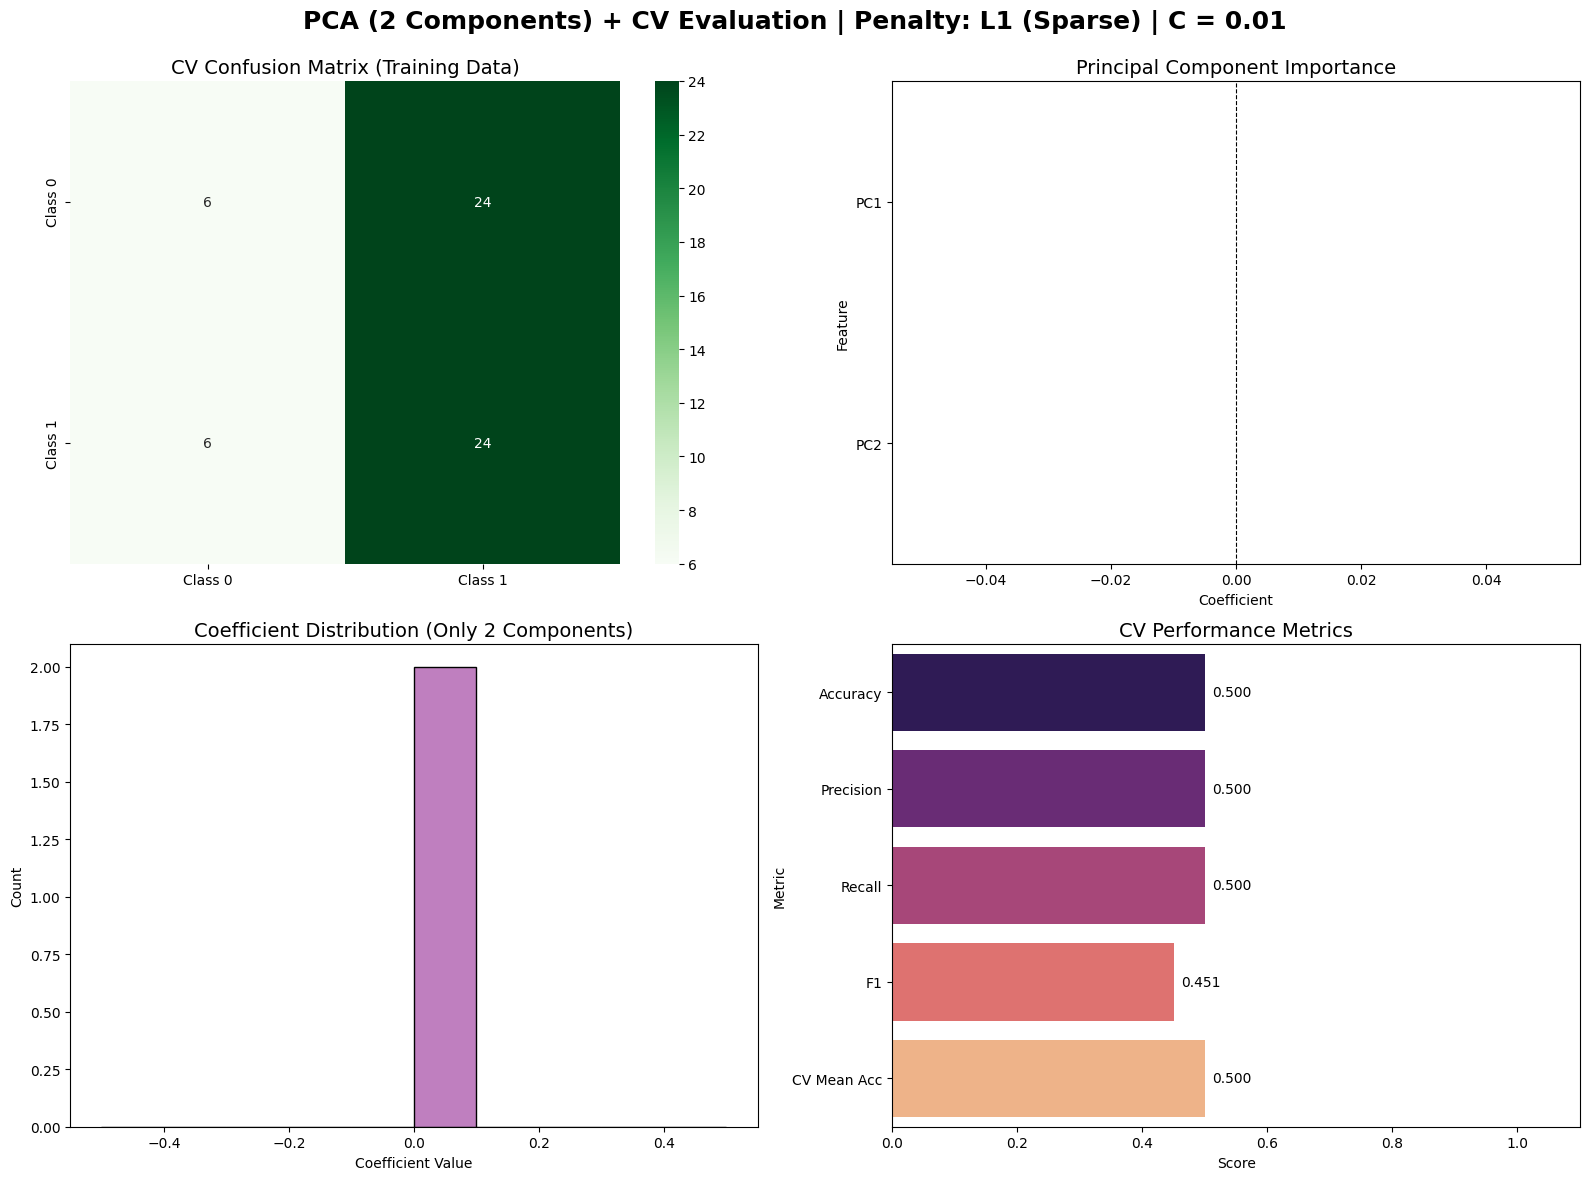


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.3333


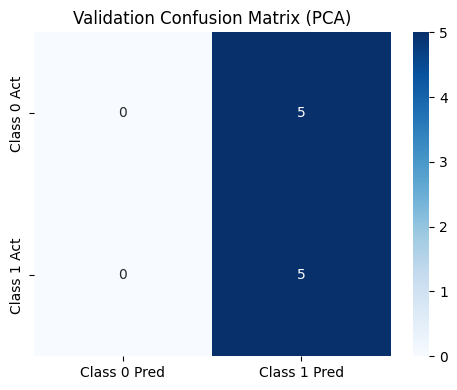


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

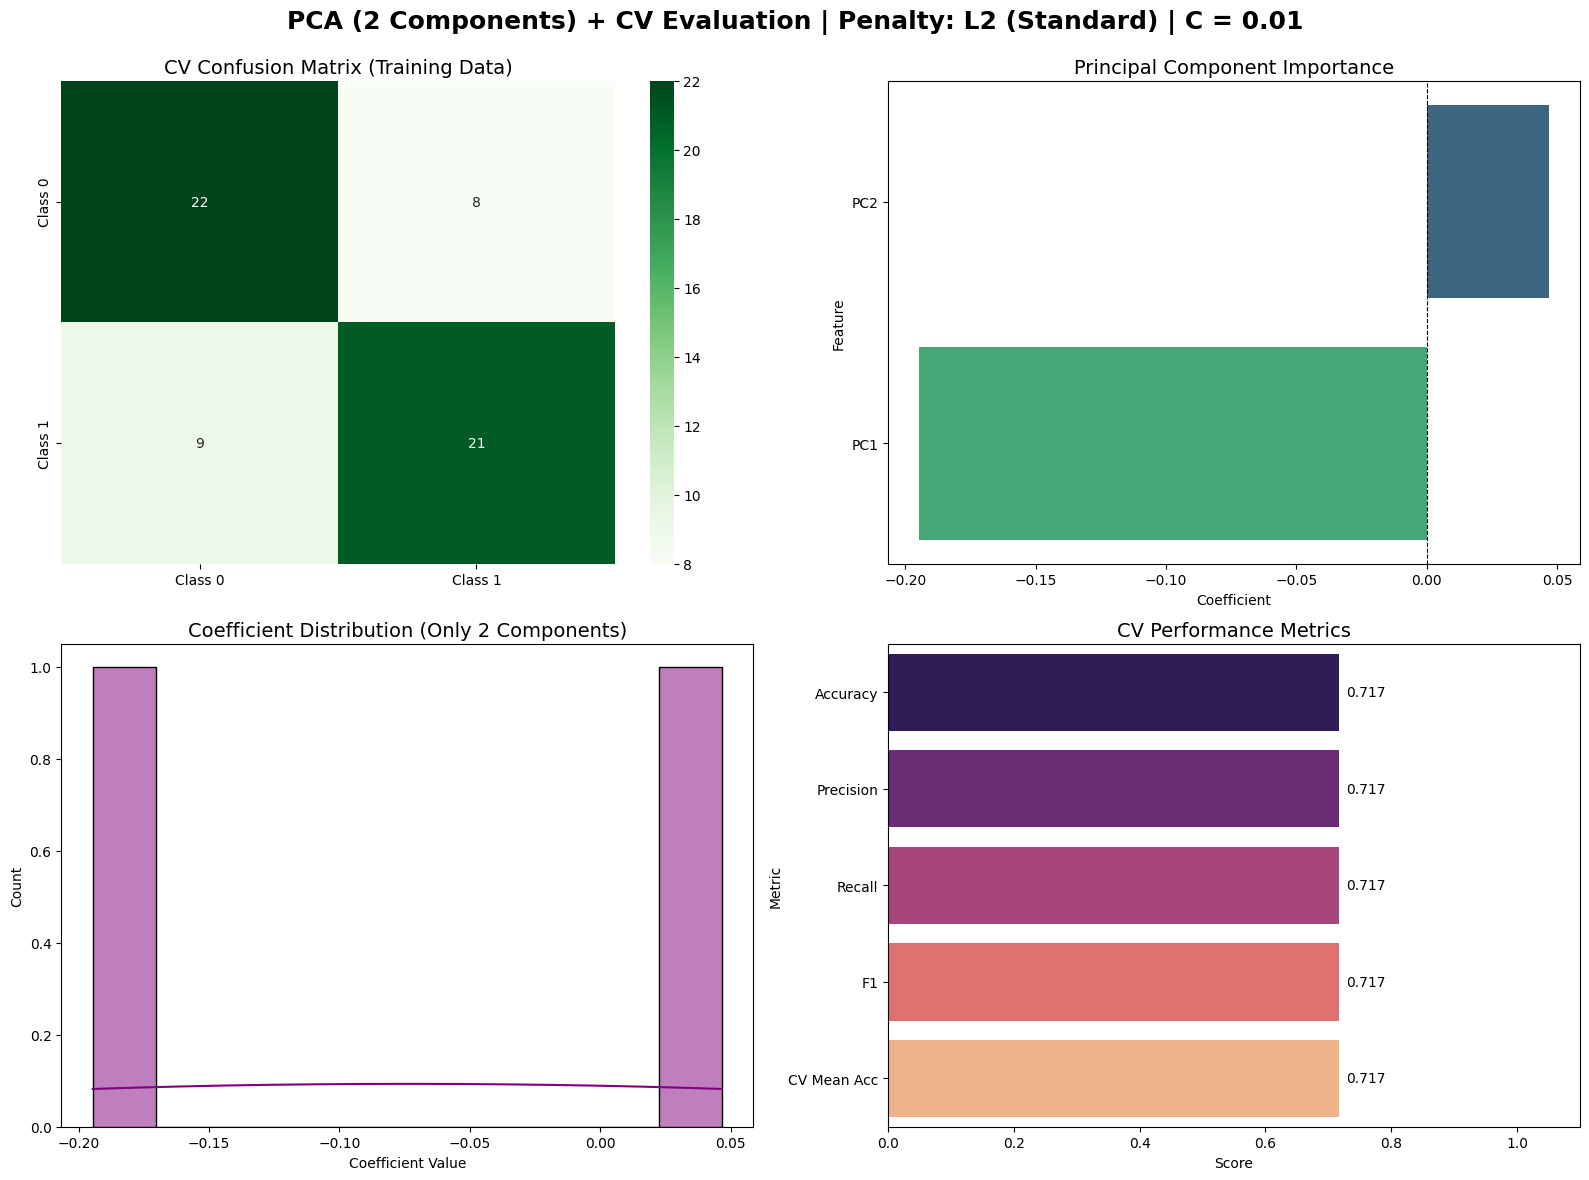


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970


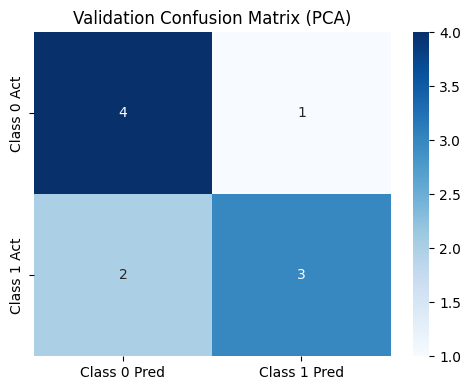

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

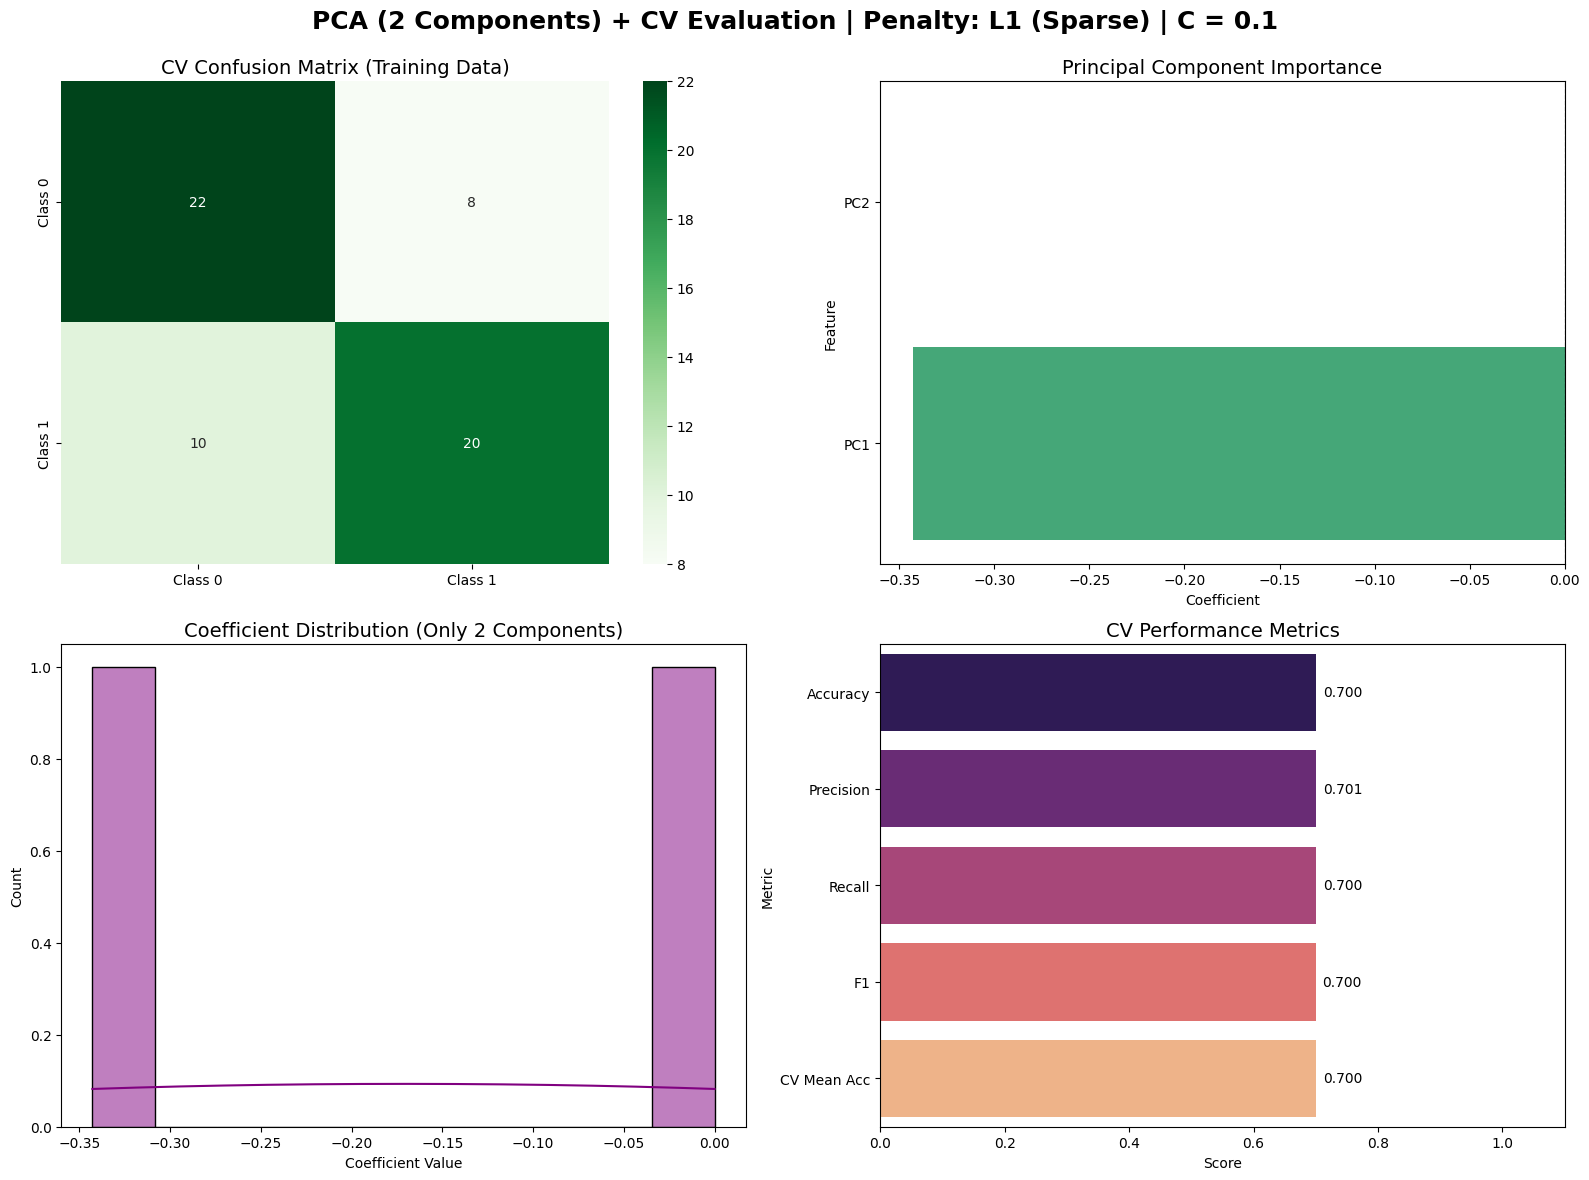


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970


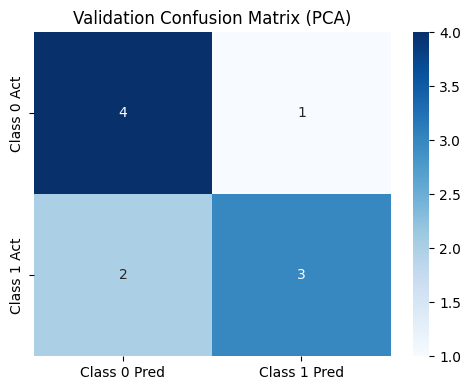


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

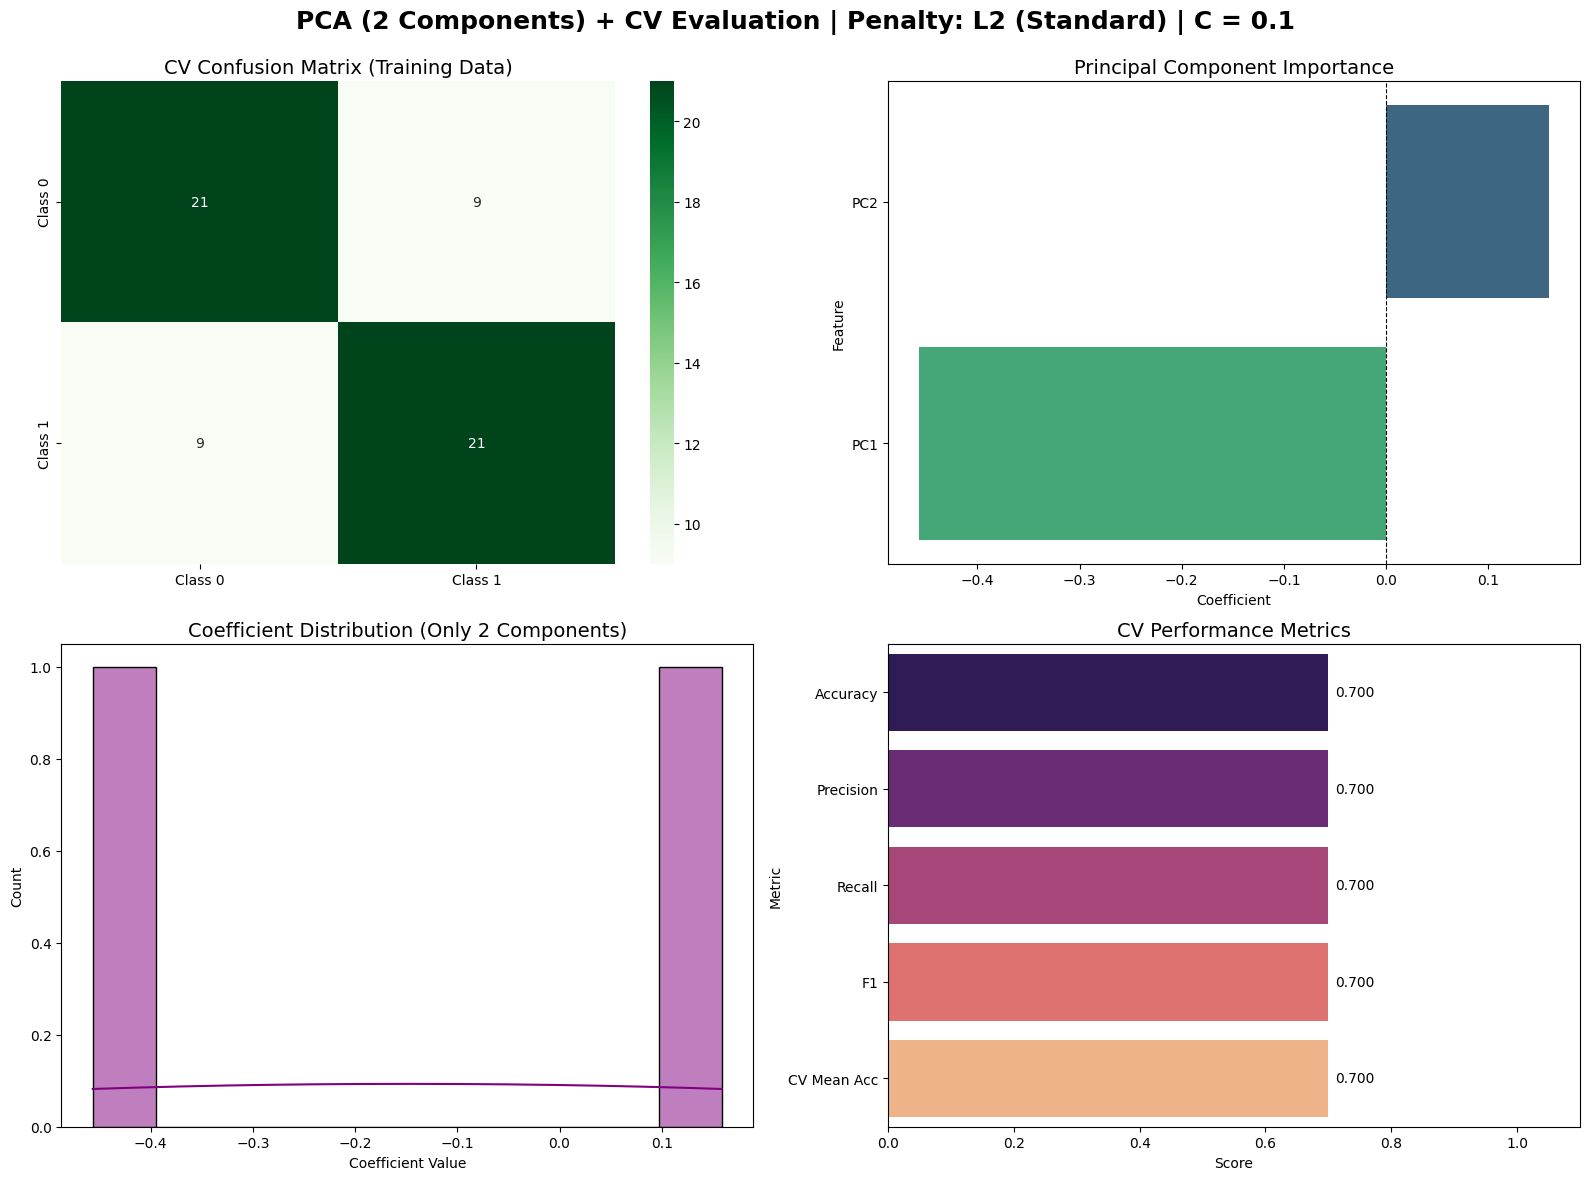


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970


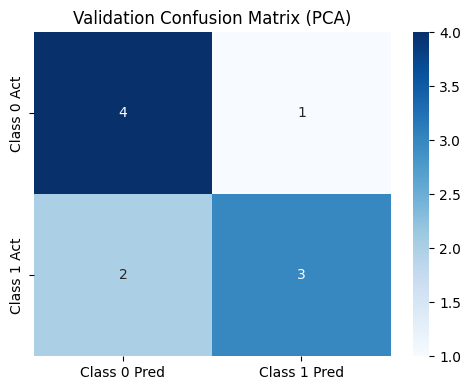

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

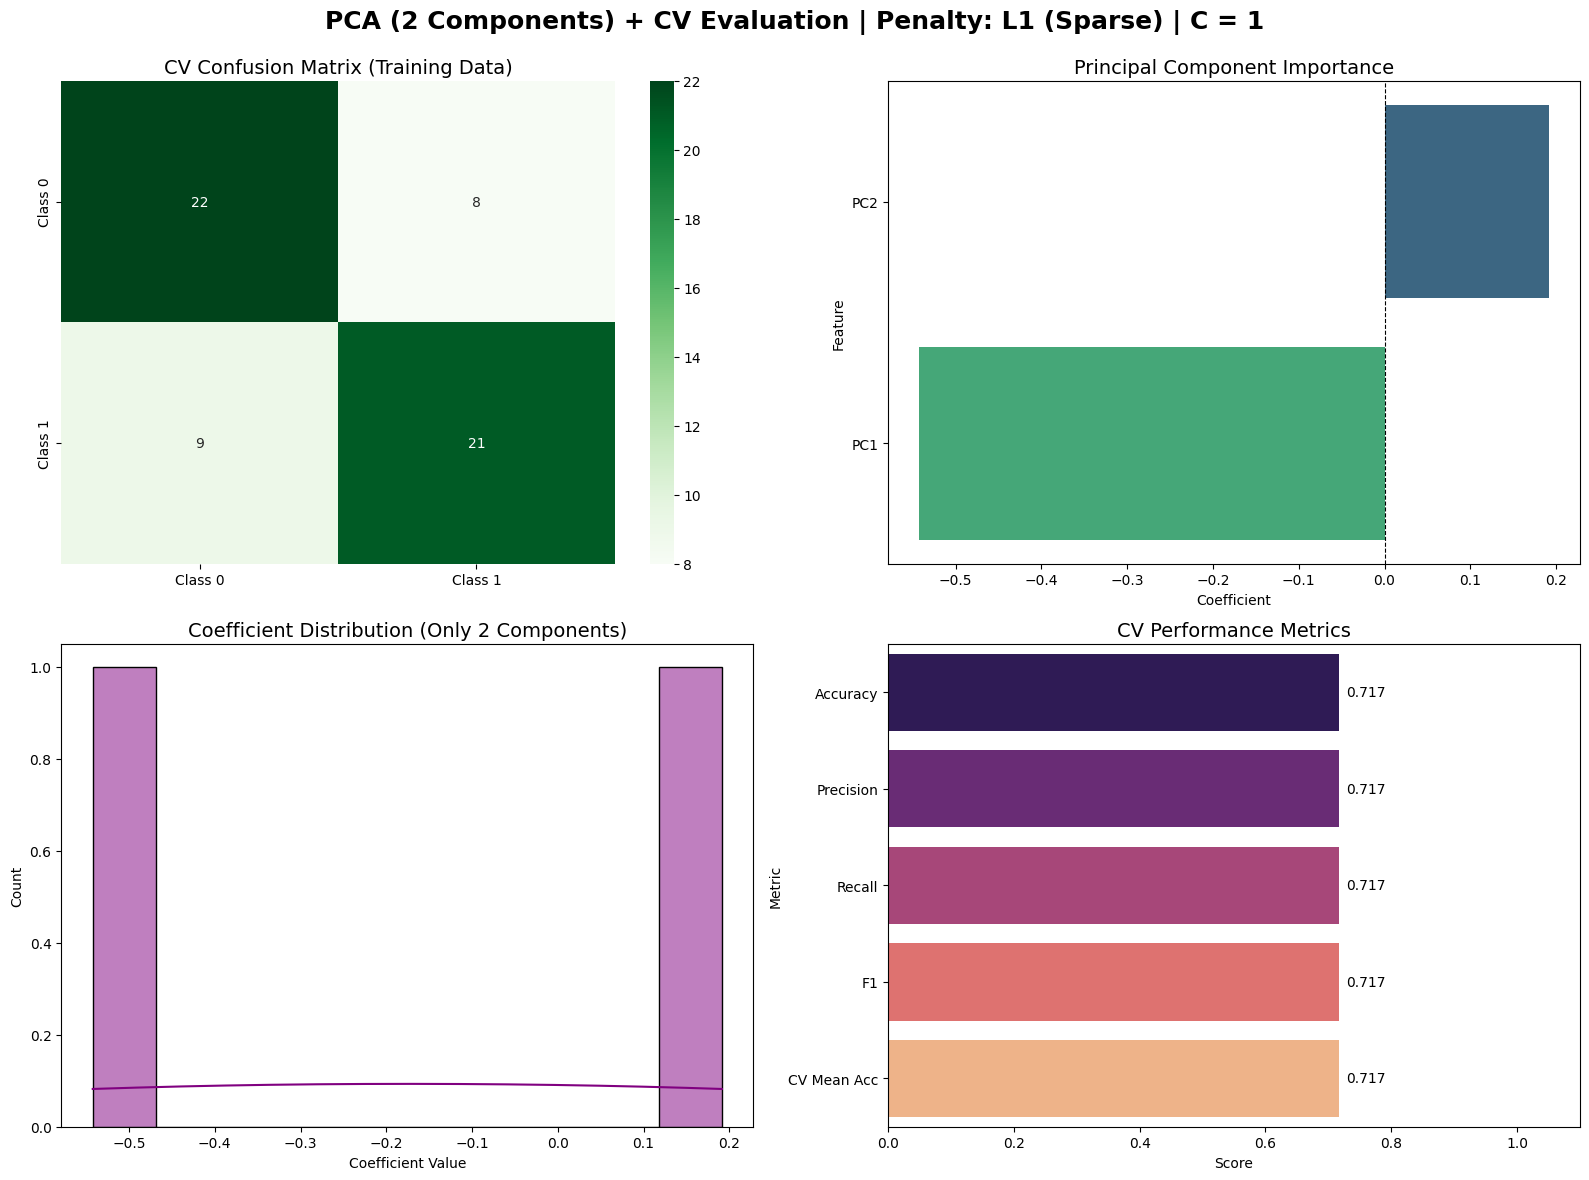


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970


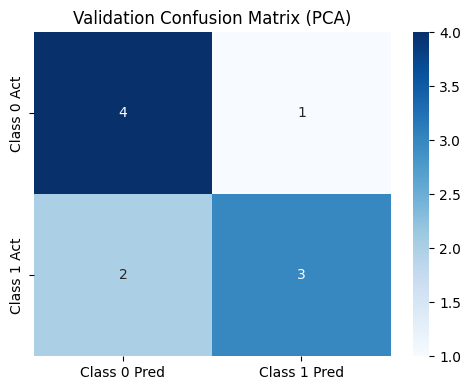


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

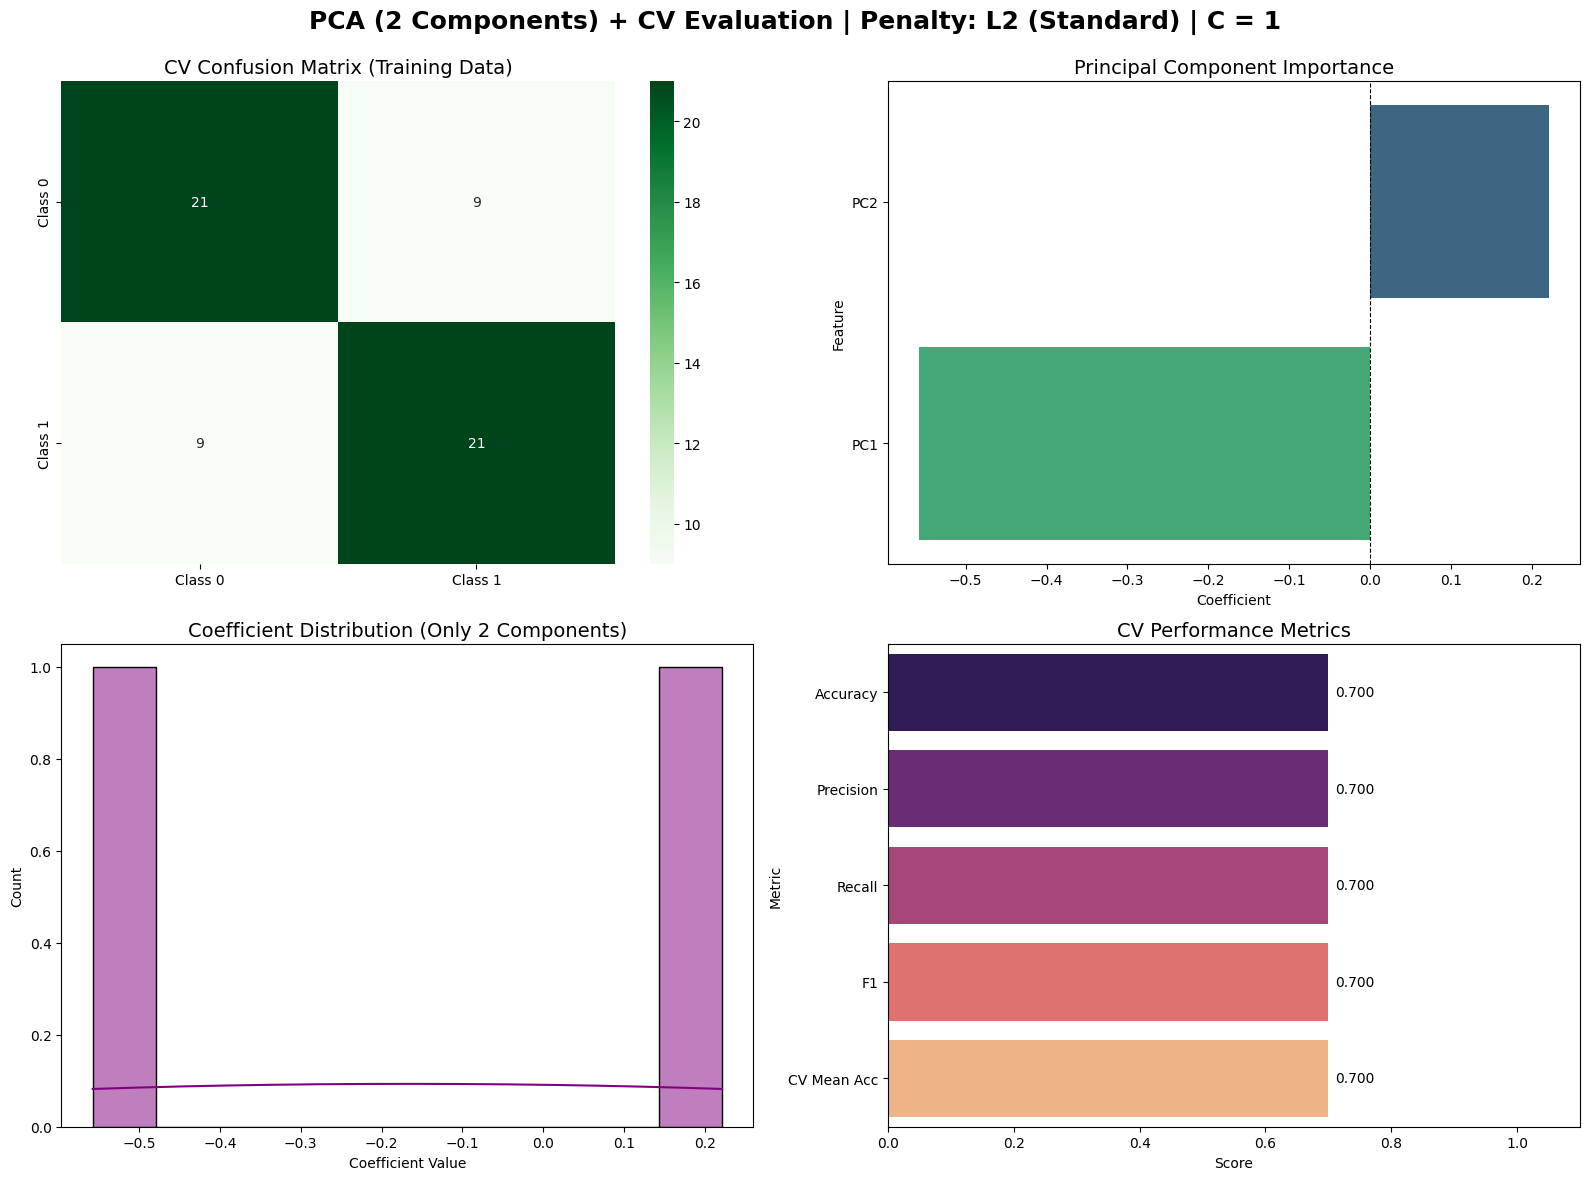


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970


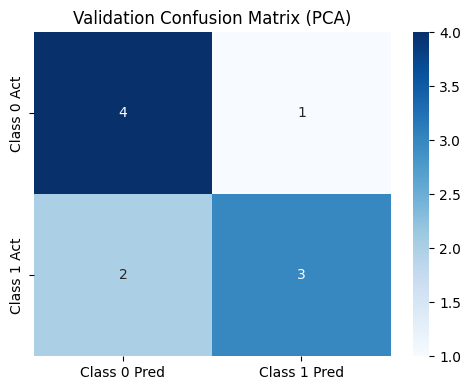

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

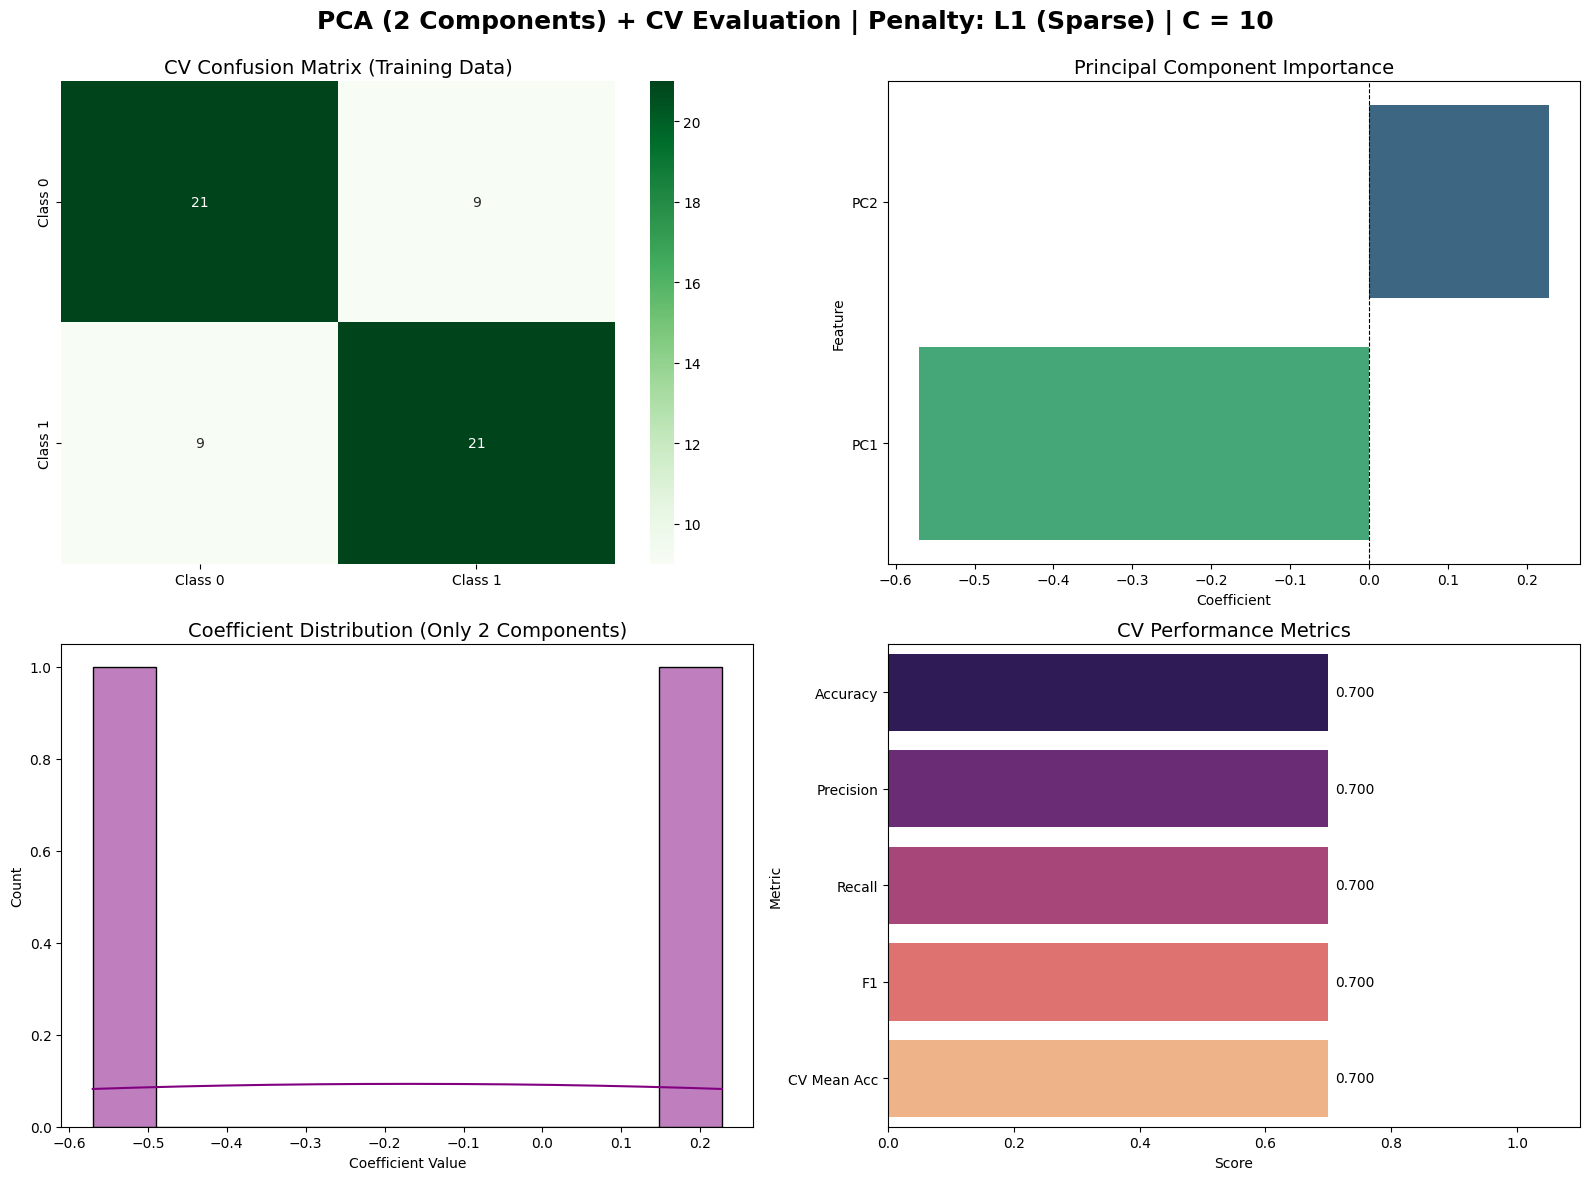


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970


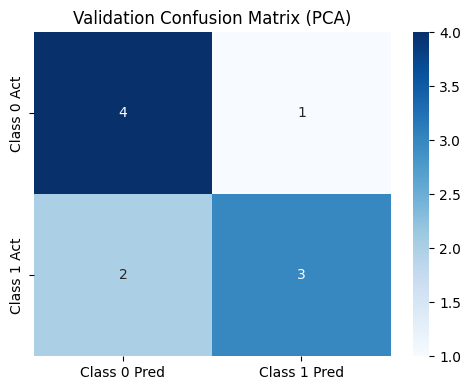


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

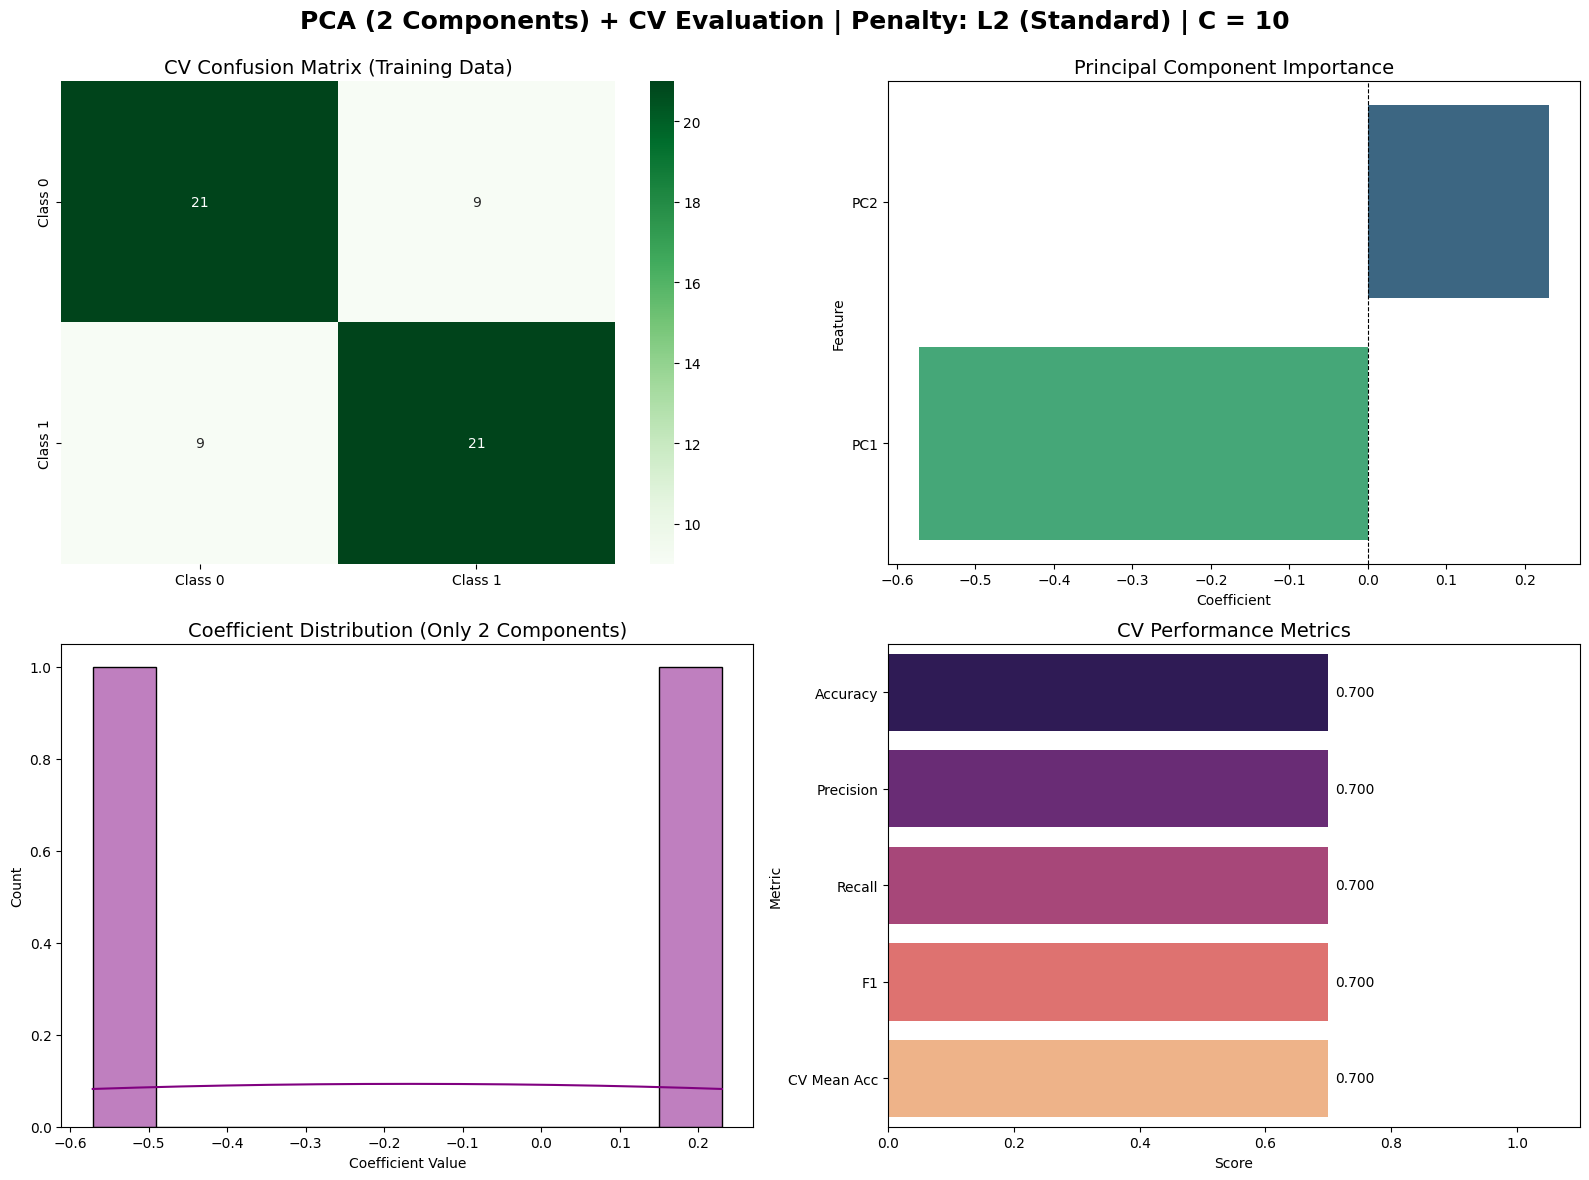


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970


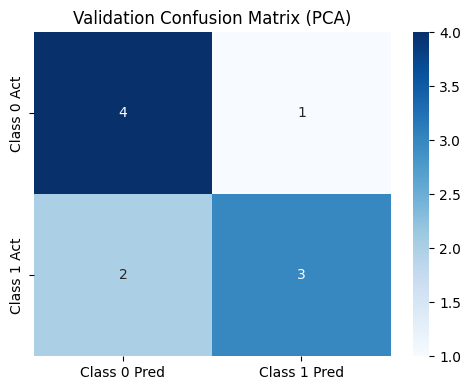

--- Running Experiment 1: L1 (Sparse/Pruned) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

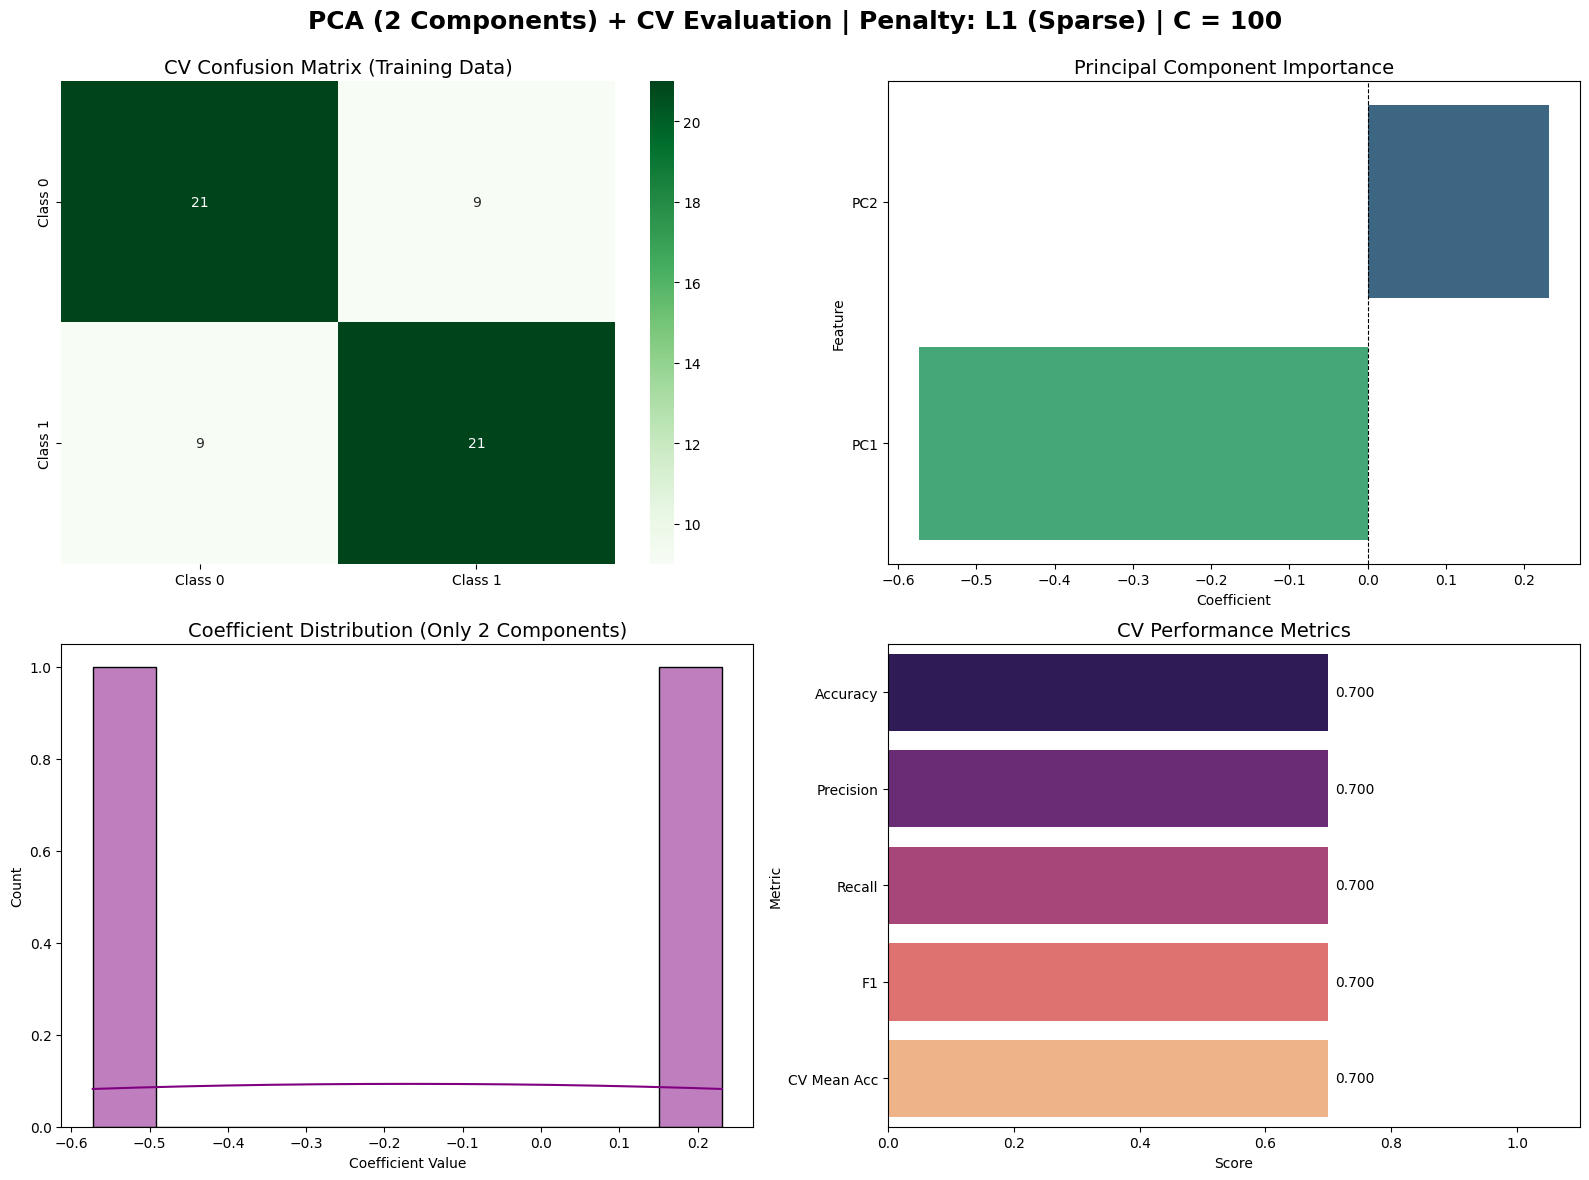


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970


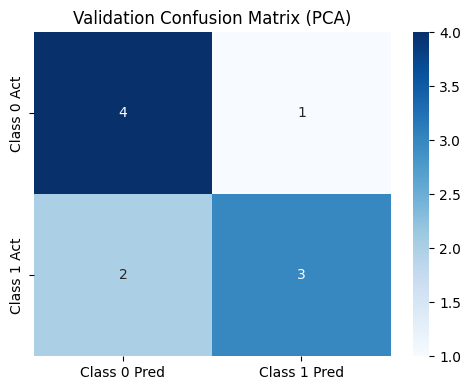


--- Running Experiment 2: L2 (Standard) ---
Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

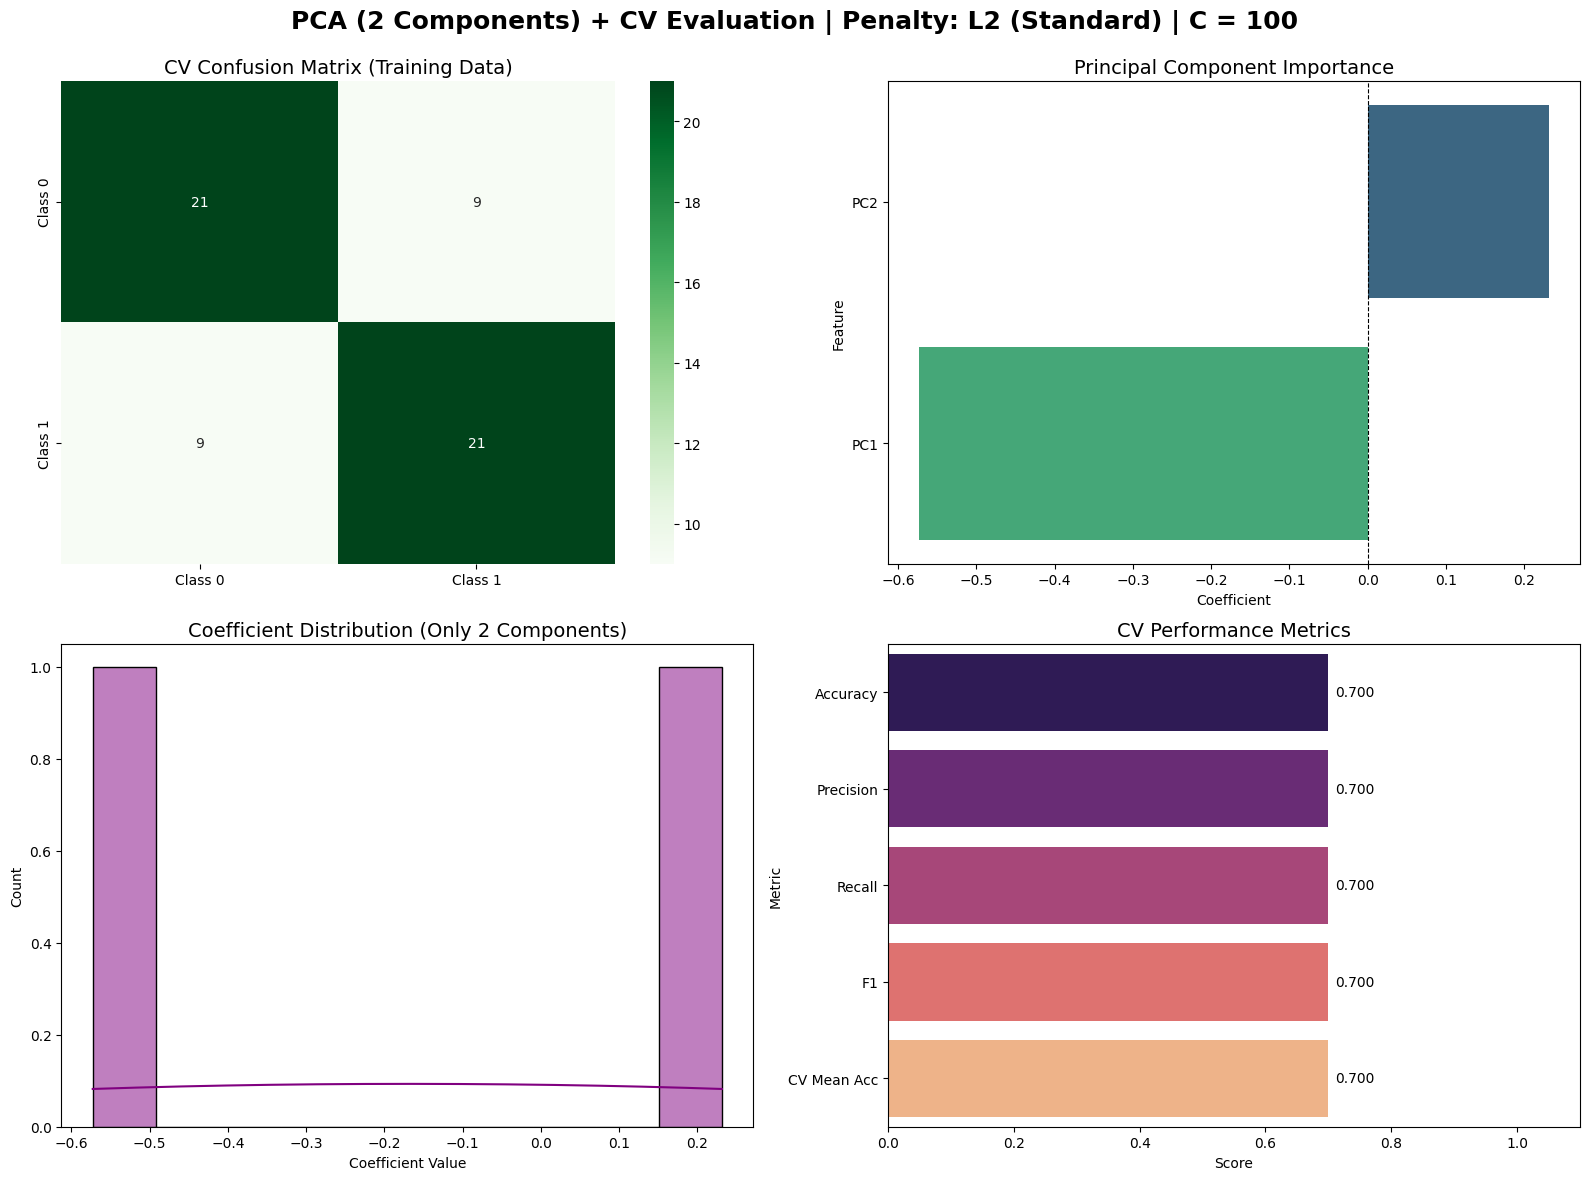


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970


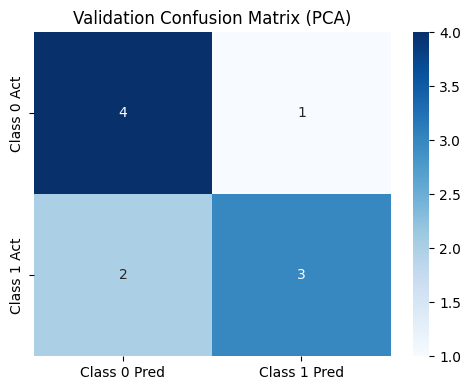

In [50]:
if __name__ == "__main__":
    c_values = [0.01, 0.1, 1, 10, 100]
    for c in c_values:
        # Experiment 1: Sparse model (L1 Regularization)
        # This will effectively prune features by pushing coefficients to zero.
        print("--- Running Experiment 1: L1 (Sparse/Pruned) ---")
        evaluate_logreg_with_pca_kfold(use_l1=True, C_value=c)
        
        # Experiment 2: Standard model (L2 Regularization)
        # This will keep all features and distribute weights more evenly.
        print("\n--- Running Experiment 2: L2 (Standard) ---")
        evaluate_logreg_with_pca_kfold(use_l1=False, C_value=c)